# Fairness and Accountability
Notebook 02 froze the final model (XGBoost, trained on Base months 0-3 with 5 seeds, thresholds picked on month 5). Notebook 04 found that it flags genuine applicants aged 50+ 3.3 times as often as younger ones, and that housing BA, employment CC and income 0.9 are flagged even more often. **This notebook is where the age gap is analysed in depth.** It asks three things:

1. **How big are the gaps, and are they stable?** Age (50+ vs under 50) is the main attribute; income, employment and housing are checked as a second tier.
2. **Where does the gap come from?** The ranking, the shared threshold, the base rates, the direct use of age, or proxies.
3. **Which interventions reduce it, and what do they cost?** Removing age and its proxies, reweighing and group-specific thresholds, in recall, false alarms and cost; then whether they carry over to other data, and what a fairness-aware review workflow adds.

**The frozen model stays frozen.** Sections 1 to 5 and 6.1 only score with it. Sections 6.2, 7 and 9 train *new* models (the recipe of the frozen model, with its settings), and every choice is made on month 4 (settings) and month 5 (thresholds) before months 6-7 are looked at once.

**Table of Contents**
1. Setup
2. Data and proxy audit
3. Baseline findings on Base
4. Why is there a gap?
5. Second-tier groups and intersections
6. The BAF variants
7. Mitigations
8. The trade-off between fairness and fraud detection
9. Does a mitigation carry over?
10. Fairness in the review workflow
11. Accountability
- Summary and recommendations

## **1. Setup**
### **1.1 Imports and Data Setup**

In [1]:
import os
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import OrdinalEncoder
import xgboost as xgb

from model_loading import calibrate, load_model   # Platt calibration saved by notebook 04; load_model also works on Windows

# Plot settings (same as notebooks 02-05)
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREEN = '#1baf7a'
GREY = '#8a8a8a'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['grid.alpha'] = 0.3

The same evaluation rules as notebooks 02-05:

| Months | Used for |
|---|---|
| 0-3 | training the models (and, here, choosing groups and proxies) |
| 4 | choosing settings (validation) |
| 5 | picking thresholds (the frozen one, and the group thresholds of section 7) |
| 6-7 | final results, reported once |

This notebook uses the table of scores that notebook 04 saved (`data/cache/scores.parquet`), or makes it itself if the file is missing (see below).

**Choices fixed for the whole notebook**
- **Main group:** age 50+ vs under 50. The BAF dataset treats `customer_age` of 50 or more as the group with a documented bias, and notebooks 02, 04 and 05 use the same split, so numbers can be compared. `customer_age` only takes decade values (10, 20, ...), so 50 is a bin edge.
- **Threshold:** the frozen one, 5% of genuine month-5 applications flagged per seed. It is the project's operating point (notebook 02).
- **Seeds:** 5 (0-4), the same as the frozen model; every result is the mean over seeds.
- **Cost ratios:** 5, 10, 20 and 50, the same grid as notebook 04 (section 9).
- **Reliable group:** at least 1,000 rows (for an FPR) and at least 50 fraud cases (for a recall), the same rules as notebook 04 (section 12).
- **Where choices are made:** month 4 for choices, month 5 for thresholds, and months 6-7 only to report. Month 4 was not used to train any model or to set any threshold, and nothing was picked by looking at months 6-7.

In [2]:
DATA_DIR = '../data'
CACHE_FILE = f'{DATA_DIR}/cache/scores.parquet'
TARGET = 'fraud_bool'

TRAIN_MONTHS = [0, 1, 2, 3]
VALIDATION_MONTHS = [4]
CALIBRATION_MONTHS = [5]
TEST_MONTHS = [6, 7]
SEEDS = [0, 1, 2, 3, 4]

AGE_CUT = 50                       # the BAF group with a documented bias: customer_age of 50 or more
TARGET_FPR = 0.05                  # the project's budget: at most 5% of genuine applications flagged
FPR_BUDGETS = [0.01, 0.05, 0.10]   # section 3.4: 5 times stricter, the project's, and twice as generous
COST_RATIOS = [5, 10, 20, 50]      # the same grid as notebook 04, section 9
N_BOOTSTRAP = 1000                 # as notebook 04, section 5
BOOTSTRAP_SEED = 4012              # as notebook 04, so the same resampled applications are used
MIN_GROUP_ROWS = 1000              # as notebook 04, section 12: below this a group is "unreliable"
MIN_FRAUD_CASES = 50               # as notebook 04, section 12: below this a group's recall is not reported
FOUR_FIFTHS = 0.8                  # the common adverse-impact reference for a ratio of rates
N_CALIBRATION_BINS = 10            # the usual number of bins for reliability plots

final_model = json.load(open('../configs/final_model.json'))
FEATURES = final_model['features']
thresholds = {int(seed): t for seed, t in final_model['thresholds'].items()}

Every later section works from one table of scores: Base months 0-7 and each variant's months 5-7, scored by the 5 frozen models. Notebook 04 (section 3) makes that table and saves it to `data/cache/scores.parquet`. **If the file is missing, this notebook makes it itself** with the same code (copied below), which takes about a minute, and saves it to the same place. Nothing is retrained.

In [3]:
DATASET_FILES = {'base': 'Base.csv', 'variant_i': 'Variant I.csv', 'variant_ii': 'Variant II.csv',
                 'variant_iii': 'Variant III.csv', 'variant_iv': 'Variant IV.csv', 'variant_v': 'Variant V.csv'}
DATASETS = list(DATASET_FILES)
BASE_MONTHS = list(range(8))   # Base is scored on every month
VARIANT_MONTHS = [5, 6, 7]     # the variants on the threshold month and the test months

MISSING_AS_MINUS_ONE = ['prev_address_months_count', 'current_address_months_count',
                        'bank_months_count', 'session_length_in_minutes',
                        'device_distinct_emails_8w']

CATEGORY_LEVELS = {
    'payment_type': ['AA', 'AB', 'AC', 'AD', 'AE'],
    'employment_status': ['CA', 'CB', 'CC', 'CD', 'CE', 'CF', 'CG'],
    'housing_status': ['BA', 'BB', 'BC', 'BD', 'BE', 'BF', 'BG'],
    'source': ['INTERNET', 'TELEAPP'],
    'device_os': ['linux', 'macintosh', 'other', 'windows', 'x11'],
}
DRIFTING_COLUMNS = ['velocity_6h', 'velocity_24h', 'velocity_4w', 'zip_count_4w']
KEEP_COLUMNS = ['customer_age', 'income', 'employment_status', 'housing_status', 'source', 'device_os', 'payment_type']


def preprocess(df, missing_flags=True):
    # Copied from notebook 02, section 3.
    X = df.copy()
    X['income'] = X['income'].round(1)

    for col in MISSING_AS_MINUS_ONE + ['intended_balcon_amount']:
        if col == 'intended_balcon_amount':
            is_missing = X[col] < 0      # any negative number means missing
        else:
            is_missing = X[col] == -1
        if missing_flags:
            X[f'{col}_missing'] = is_missing.astype(int)
        X.loc[is_missing, col] = np.nan

    for col, levels in CATEGORY_LEVELS.items():
        X[col] = pd.Categorical(X[col], categories=levels)

    return X.drop(columns=['device_fraud_count', 'x1', 'x2'], errors='ignore')


def make_features(df, missing_flags=False, drifting='keep', valid_phones=False, include_age=True):
    # Copied from notebook 02, section 4.2.
    X = preprocess(df, missing_flags)

    if valid_phones:
        X['valid_phones'] = X['phone_home_valid'] + X['phone_mobile_valid']

    if drifting == 'ratio':
        X['velocity_6h_vs_24h'] = X['velocity_6h'] / X['velocity_24h']
        X['velocity_24h_vs_4w'] = X['velocity_24h'] / X['velocity_4w']
        X['zip_count_vs_velocity_4w'] = X['zip_count_4w'] / X['velocity_4w']
    elif drifting == 'rank':
        for col in DRIFTING_COLUMNS:
            X[f'{col}_month_rank'] = X.groupby('month')[col].rank(pct=True)
    if drifting != 'keep':
        X = X.drop(columns=DRIFTING_COLUMNS)

    if not include_age:
        X = X.drop(columns=['customer_age'])

    return X.drop(columns=[TARGET, 'month'])


def score_dataset(dataset, months, models):
    # Copied from notebook 04, section 3: scores the given months of one dataset with all 5 frozen models.
    df = pd.read_csv(f'{DATA_DIR}/{DATASET_FILES[dataset]}')
    part = df[df['month'].isin(months)]
    X = make_features(part, **FEATURES)

    table = pd.DataFrame({'dataset': dataset, 'row_id': part.index.to_numpy(), 'month': part['month'].to_numpy(),
                          'y_true': part[TARGET].to_numpy()})
    for col in KEEP_COLUMNS:
        table[col] = part[col].to_numpy()
    for seed, model in models.items():
        table[f'score_seed{seed}'] = model.predict_proba(X)[:, 1].astype(np.float32)
    return table


if os.path.exists(CACHE_FILE):
    scores = pd.read_parquet(CACHE_FILE)
    print(f'Loaded the saved scores from {CACHE_FILE}')
else:
    print(f'{CACHE_FILE} is missing (notebook 04 has not saved it here): scoring with the frozen models')
    start = time.time()
    frozen_models = {seed: load_model(f"../outputs/models/{final_model['model']}_seed{seed}.joblib") for seed in SEEDS}
    parts = []
    for dataset in DATASETS:
        parts.append(score_dataset(dataset, BASE_MONTHS if dataset == 'base' else VARIANT_MONTHS, frozen_models))
        print(f'{dataset:12s} scored: {len(parts[-1]):,} rows')
    scores = pd.concat(parts, ignore_index=True)
    try:
        os.makedirs(os.path.dirname(CACHE_FILE), exist_ok=True)
        scores.to_parquet(CACHE_FILE, index=False)
        print(f'Scored in {(time.time() - start) / 60:.1f} min, saved to {CACHE_FILE}')
    except Exception as error:   # for example, no parquet library installed
        print(f'Scored in {(time.time() - start) / 60:.1f} min; the scores could not be saved ({type(error).__name__}), they stay in memory')
scores['dataset'] = pd.Categorical(scores['dataset'], categories=DATASETS)

Loaded the saved scores from ../data/cache/scores.parquet


In [4]:
base = scores[scores['dataset'] == 'base'].reset_index(drop=True)
base['age_50_plus'] = (base['customer_age'] >= AGE_CUT).to_numpy()
SCORE_COLUMNS = [f'score_seed{seed}' for seed in SEEDS]

test = base[base['month'].isin(TEST_MONTHS)].reset_index(drop=True)
y_test = test['y_true'].to_numpy()
old_test = test['age_50_plus'].to_numpy()
flags_test = {seed: test[f'score_seed{seed}'].to_numpy() >= thresholds[seed] for seed in SEEDS}

print(f'Base months 0-7: {len(base):,} applications; test months 6-7: {len(test):,} applications, '
      f'{y_test.sum():,} fraud cases ({y_test.mean():.2%}); aged {AGE_CUT}+: {old_test.mean():.1%}')

Base months 0-7: 1,000,000 applications; test months 6-7: 205,011 applications, 2,878 fraud cases (1.40%); aged 50+: 16.5%


Each seed's frozen threshold was picked so that it flags 5% of genuine Base applications in month 5. It should still do that on the saved scores.

In [5]:
month5 = base[base['month'].isin(CALIBRATION_MONTHS)]
genuine5 = month5['y_true'].to_numpy() == 0
threshold_check = pd.Series({seed: (month5.loc[genuine5, f'score_seed{seed}'] >= thresholds[seed]).mean() for seed in SEEDS},
                            name='share of genuine month-5 applications flagged').rename_axis('seed')
assert threshold_check.between(0.045, 0.055).all(), 'the frozen thresholds do not flag about 5% of genuine month-5 applications'
threshold_check.to_frame()

,share of genuine month-5 applications flagged
seed,
0,0.049927
1,0.049995
2,0.049783
3,0.049681
4,0.049986


### **1.2 Fairness Metrics**
All metrics compare the **group of interest** (aged 50+) with the **reference group** (under 50), at a decision rule that flags some applications. They only use four counts per group (applications, fraud cases, flagged, flagged fraud), so one function gives all of them.

| Metric | What it compares | Why it matters here |
|---|---|---|
| **Demographic parity** | flag rate, P(flagged) | Whether the group is flagged as often. It can be unfair to demand if the groups really differ in fraud. |
| **Equal opportunity** | TPR (recall), P(flagged given fraud) | Whether fraud is caught equally often in both groups. |
| **Predictive equality** (the main metric here) | FPR, P(flagged given genuine) | Whether genuine customers are wrongly flagged equally often. This is the harm the customer feels, and the metric notebooks 02-04 use. |
| **Equalised odds** | the larger of the TPR gap and the FPR gap | Equal opportunity and predictive equality together. |
| **Predictive parity** | precision (PPV), P(fraud given flagged) | Whether a flag means the same thing in both groups. |
| **Calibration within group** | predicted probability vs actual fraud rate, per group | Whether a score of 0.3 means 30% for both groups (section 3.6). |

**Ratios** are the lower rate divided by the higher one (1 = equal), as in notebooks 02-04. **Differences** are the group of interest minus the reference. **Reference value 0.8 (the four-fifths rule).** The common rule of thumb for adverse impact in US employment guidelines: a ratio below 0.8 is treated as a sign of disparity. It is a screening rule, not a legal test. There is no comparable standard for differences, so differences are reported without a pass mark. Ratios are used because they are scale-free and are what the earlier notebooks report; differences show the size in percentage points.

This notebook optimizes for **predictive equality**, the ratio of false positive rates, as the main fairness metric because the harm of a fraud model falls on genuine customers who are wrongly flagged: they are delayed, questioned or refused, and it is this burden that **fairness rules and complaints** are concerned with. A missed fraud is a financial loss to the bank, not an injury to the group, so recall measures detection quality rather than fairness of treatment. The data supports this choice. Genuine applicants aged 50+ are flagged 12.7% of the time against 3.9% for those under 50 (a ratio of 0.31), while recall is higher for the 50+ group (0.70 against 0.49), so a recall-based metric would point at the wrong group. Recall is not ignored: equal opportunity is reported as a second aim, and every mitigation is judged by its recall and cost. Because fraud rates differ between the groups (2.9% against 1.1%), the fairness metrics cannot all be equal at once, so a choice has to be made, and this one is consistent with notebooks 02–04.

In [6]:
def weighted_group_rates(W, y, is_a, flags_by_seed, labels=('50+', 'under 50')):
    """Group rates for each row of W (one row = one set of applicant weights; all ones = the real data).

    y: 1 for fraud; is_a: True for the group of interest; flags_by_seed: {seed: True if flagged}.
    Rates are computed for every seed, then averaged over the seeds, as in notebook 04.
    Returns a table with one row per row of W and columns (group, metric)."""
    y = np.asarray(y)
    is_a = np.asarray(is_a)
    fraud = y == 1
    masks = [is_a, ~is_a]
    columns = []
    for m in masks:
        columns += [m, m & fraud, m & ~fraud]                           # size, fraud cases, genuine
    for flags in flags_by_seed.values():
        for m in masks:
            columns += [m & flags, m & flags & fraud, m & flags & ~fraud]   # flagged, flagged fraud, flagged genuine
    S = np.asarray(W, dtype=np.float32) @ np.column_stack(columns).astype(np.float32)

    out = {}
    total = S[:, 0] + S[:, 3]
    for g, label in enumerate(labels):
        size, n_fraud, n_genuine = S[:, 3 * g], S[:, 3 * g + 1], S[:, 3 * g + 2]
        per_seed = []
        for k in range(len(flags_by_seed)):
            flagged, tp, fp = (S[:, 6 + 6 * k + 3 * g + j] for j in range(3))
            precision = np.divide(tp, flagged, out=np.full_like(tp, np.nan), where=flagged > 0)
            per_seed.append(np.column_stack([flagged / size, tp / n_fraud, fp / n_genuine, precision]))
        flag_rate, tpr, fpr, ppv = np.nanmean(per_seed, axis=0).T
        out[(label, 'share of applications')] = size / total
        out[(label, 'fraud rate')] = n_fraud / size
        out[(label, 'flag rate')] = flag_rate
        out[(label, 'TPR (recall)')] = tpr
        out[(label, 'FPR')] = fpr
        out[(label, 'precision (PPV)')] = ppv
    return pd.DataFrame(out)


def gap_measures(a, b):
    """Gap measures between the group of interest (a) and the reference group (b); a and b are the rates tables of one group each."""
    def ratio(x, y):
        return np.minimum(x, y) / np.maximum(x, y)     # lower rate / higher rate, 1 = equal
    tpr_difference = a['TPR (recall)'] - b['TPR (recall)']
    fpr_difference = a['FPR'] - b['FPR']
    return pd.DataFrame({
        'demographic parity ratio': ratio(a['flag rate'], b['flag rate']),
        'equal opportunity ratio': ratio(a['TPR (recall)'], b['TPR (recall)']),
        'predictive equality ratio': ratio(a['FPR'], b['FPR']),
        'predictive parity ratio': ratio(a['precision (PPV)'], b['precision (PPV)']),
        'flag rate difference': a['flag rate'] - b['flag rate'],
        'TPR difference': tpr_difference,
        'FPR difference': fpr_difference,
        'equalised odds difference': np.maximum(np.abs(tpr_difference), np.abs(fpr_difference)),
    })


def point_rates(y, is_a, flags_by_seed, labels=('50+', 'under 50')):
    """Rates and gaps on the real data (no resampling)."""
    rates = weighted_group_rates(np.ones((1, len(y)), dtype=np.float32), y, is_a, flags_by_seed, labels)
    return rates, gap_measures(rates[labels[0]], rates[labels[1]])

**Simple example check**
- Group A (4 applicants) has 1 fraud case; 2 are flagged, one of them the fraud case. For A: flag rate 0.5, TPR 1, FPR 1/3, precision 0.5
- Group B (4 applicants) has 2 fraud cases; 1 is flagged, a fraud case. For B: flag rate 0.25, TPR 0.5, FPR 0, precision 1. 
- The gaps follow: demographic parity ratio 0.5, equal opportunity ratio 0.5, predictive equality ratio 0, predictive parity ratio 0.5, equalised odds difference max(0.5, 1/3) = 0.5.

In [7]:
toy_y = np.array([1, 0, 0, 0, 1, 1, 0, 0])
toy_a = np.array([True] * 4 + [False] * 4)
toy_flags = {0: np.array([True, True, False, False, True, False, False, False])}
toy_rates, toy_gaps = point_rates(toy_y, toy_a, toy_flags)
expected = {'demographic parity ratio': 0.5, 'equal opportunity ratio': 0.5, 'predictive equality ratio': 0.0,
            'predictive parity ratio': 0.5, 'equalised odds difference': 0.5}
for name, value in expected.items():
    assert np.isclose(toy_gaps[name].iloc[0], value), (name, toy_gaps[name].iloc[0], value)
assert np.isclose(toy_rates[('50+', 'FPR')].iloc[0], 1 / 3)
print('The toy example gives the hand-worked values.')

try:   # a second check against fairlearn, if it is installed
    from fairlearn.metrics import demographic_parity_difference, equalized_odds_difference
    s = {'sensitive_features': toy_a}
    ours = point_rates(toy_y, toy_a, toy_flags)[1].iloc[0]
    print('fairlearn demographic parity difference:', round(demographic_parity_difference(toy_y, toy_flags[0], **s), 4),
          '| ours (absolute):', round(abs(ours['flag rate difference']), 4))
    print('fairlearn equalized odds difference:', round(equalized_odds_difference(toy_y, toy_flags[0], **s), 4),
          '| ours:', round(ours['equalised odds difference'], 4))
except ImportError:
    print('fairlearn is not installed: the cross-check with it was skipped (optional: it is only a second check).')

The toy example gives the hand-worked values.
fairlearn is not installed: the cross-check with it was skipped (optional: it is only a second check).


### **1.3 Confidence Intervals**
The same Poisson bootstrap as notebook 04 (section 5): each application gets a random weight (how many times it was drawn, from a Poisson distribution with mean 1), the group rates are recomputed with those weights, and the 95% interval is the range between the 2.5th and 97.5th percentiles of 1,000 resamples. Every seed sees the same weights. Group rates are ratios of weighted counts, so a batch of resamples is one matrix product. The interval is 95% from 1,000 resamples with seed 4012, the same size and seed as notebook 04. 1,000 resamples put 25 resamples beyond each end of a 95% interval, enough for a stable end point.

Resampling applications measures how much the numbers depend on **which applicants happened to be in the test months**. It does not cover changes over time.

Later sections rely on this section to determine if differences are real / not noise.

In [8]:
def bootstrap_rates(y, is_a, flags_by_seed, labels=('50+', 'under 50'), n_resamples=N_BOOTSTRAP,
                    rng_seed=BOOTSTRAP_SEED, batch=50):
    """Group rates for n_resamples Poisson resamples of the applications."""
    rng = np.random.default_rng(rng_seed)
    parts = []
    for start in range(0, n_resamples, batch):
        W = rng.poisson(1.0, size=(min(batch, n_resamples - start), len(y))).astype(np.float32)
        parts.append(weighted_group_rates(W, y, is_a, flags_by_seed, labels))
    return pd.concat(parts, ignore_index=True)


def interval(values, estimate):
    """Estimate with the 95% interval of the resamples."""
    return pd.DataFrame({'estimate': estimate, 'CI low': values.quantile(0.025), 'CI high': values.quantile(0.975)})


def fairness_summary(y, is_a, flags_by_seed, labels=('50+', 'under 50'), n_resamples=N_BOOTSTRAP):
    """The rates of both groups and the gap measures, each with a 95% interval (one set of resamples for both)."""
    rates, gaps = point_rates(y, is_a, flags_by_seed, labels)
    resampled = bootstrap_rates(y, is_a, flags_by_seed, labels, n_resamples)
    resampled_gaps = gap_measures(resampled[labels[0]], resampled[labels[1]])
    rate_table = interval(resampled, rates.iloc[0]).rename_axis(['group', 'metric'])
    gap_table = interval(resampled_gaps, gaps.iloc[0]).rename_axis('measure')
    return rate_table, gap_table

## **2. Data and Proxy Audit**
Examine the training data: who the groups are, how much fraud each has, and how much information about age sits in the other features. The choices in this section (which groups, which proxies) are made on **training months 0-3 and validation month 4 only**.

In [9]:
base_raw = pd.read_csv(f'{DATA_DIR}/Base.csv')
base_raw['income'] = base_raw['income'].round(1)
train_raw = base_raw[base_raw['month'].isin(TRAIN_MONTHS)]
validation_raw = base_raw[base_raw['month'].isin(VALIDATION_MONTHS)]
assert len(base_raw) == scores.loc[scores['dataset'] == 'base', 'row_id'].nunique(), 'Base.csv and the saved scores differ in size'
print(f'training months {TRAIN_MONTHS}: {len(train_raw):,} applications, validation month {VALIDATION_MONTHS}: {len(validation_raw):,}')

training months [0, 1, 2, 3]: 547,975 applications, validation month [4]: 127,691


### **2.1 Choosing the Second-Tier Groups**
- Income, employment_status and housing_status are the second tier of groups, and to a certain extent is also a proxy for age
- This section defines the groups. The rule: **the value with the highest fraud rate in training months 0-3, among values with at least 1,000 training applications.** Those are the customers a fraud model is most likely to flag, so the ones most at risk of a gap. The rule is fixed on training data, before any test errors are seen, so the groups are not picked after looking at who is treated worst.

In [10]:
SECOND_TIER_COLUMNS = ['income', 'employment_status', 'housing_status']


def highest_fraud_value(column):
    table = train_raw.groupby(column)[TARGET].agg(rows='size', fraud_rate='mean')
    table = table[table['rows'] >= MIN_GROUP_ROWS]
    return table['fraud_rate'].idxmax(), table.sort_values('fraud_rate', ascending=False)


SECOND_TIER = {}   # name -> (column, value)
for column in SECOND_TIER_COLUMNS:
    value, table = highest_fraud_value(column)
    SECOND_TIER[f'{column} = {value}'] = (column, value)
    print(f'{column}: highest fraud rate in months 0-3 among values with at least {MIN_GROUP_ROWS:,} rows is {value} '
          f'({table.loc[value, "fraud_rate"]:.2%} against {train_raw[TARGET].mean():.2%} overall)')

def in_group(frame, column, value):
    """True for the applications with the given value (income is compared with a tolerance, as it is a decimal)."""
    if column == 'income':
        return pd.Series(np.isclose(frame[column].astype(float), float(value), atol=0.05), index=frame.index)
    return frame[column].eq(value)


for name, (column, value) in SECOND_TIER.items():
    base[name] = in_group(base, column, value).to_numpy()
    test[name] = in_group(test, column, value).to_numpy()
    train_raw = train_raw.assign(**{name: in_group(train_raw, column, value)})
GROUP_NAMES = ['age 50+'] + list(SECOND_TIER)
base['age 50+'] = base['age_50_plus']
test['age 50+'] = test['age_50_plus']
train_raw = train_raw.assign(**{'age 50+': train_raw['customer_age'] >= AGE_CUT})

income: highest fraud rate in months 0-3 among values with at least 1,000 rows is 0.9 (1.93% against 0.97% overall)
employment_status: highest fraud rate in months 0-3 among values with at least 1,000 rows is CC (2.29% against 0.97% overall)
housing_status: highest fraud rate in months 0-3 among values with at least 1,000 rows is BA (3.35% against 0.97% overall)


### **2.2 Group Sizes and Fraud Rates**
The fraud rate of each group in the training months and in the test months, and the share of all applications the group makes up. A group with a higher fraud rate will be flagged more often by any model that works, which is why the fraud rate is shown next to every error rate in this notebook.

In [11]:
rows = []
for name in GROUP_NAMES:
    for label, mask_train, mask_test in [(name, train_raw[name], test[name]),
                                         (f'not ({name})', ~train_raw[name], ~test[name])]:
        rows.append({
            'group': label,
            'share of applications, months 0-3': mask_train.mean(),
            'fraud rate, months 0-3': train_raw.loc[mask_train, TARGET].mean(),
            'applications, months 6-7': int(mask_test.sum()),
            'fraud cases, months 6-7': int(test.loc[mask_test, 'y_true'].sum()),
            'fraud rate, months 6-7': test.loc[mask_test, 'y_true'].mean(),
            'fraud rate relative to everyone': test.loc[mask_test, 'y_true'].mean() / test['y_true'].mean(),
        })
group_overview = pd.DataFrame(rows).set_index('group')
group_overview.round(4)

,"share of applications, months 0-3","fraud rate, months 0-3","applications, months 6-7","fraud cases, months 6-7","fraud rate, months 6-7",fraud rate relative to everyone
group,,,,,,
age 50+,0.1910,0.0211,33779,989,0.0293,2.0856
not (age 50+),0.8090,0.0069,171232,1889,0.0110,0.7858
income = 0.9,0.1890,0.0193,59217,1486,0.0251,1.7876
not (income = 0.9),0.8110,0.0074,145794,1392,0.0095,0.6801
employment_status = CC,0.0400,0.0229,6511,202,0.0310,2.2100
not (employment_status = CC),0.9600,0.0091,198500,2676,0.0135,0.9603
housing_status = BA,0.1537,0.0335,39900,1786,0.0448,3.1886
not (housing_status = BA),0.8463,0.0053,165111,1092,0.0066,0.4711


### **2.3 Intersections**
Bias may hides where two attributes meet (e.g. young applicant with no job). This table counts applications and fraud cases in each age x second-tier cell on the test months, and marks whether a cell is big enough to measure: **at least 1,000 applications for an FPR** and **at least 50 fraud cases for a recall**, the rules of notebook 04, section 12. Cells that fail are still shown, but later sections will not draw conclusions from them.

In [12]:
rows = []
for name in list(SECOND_TIER):
    for old_label, old_mask in [('50+', test['age 50+']), ('under 50', ~test['age 50+'])]:
        for in_label, in_mask in [(name, test[name]), (f'not ({name})', ~test[name])]:
            cell = old_mask & in_mask
            rows.append({
                'second-tier group': name, 'age': old_label, 'cell': in_label,
                'applications': int(cell.sum()), 'fraud cases': int(test.loc[cell, 'y_true'].sum()),
                'fraud rate': test.loc[cell, 'y_true'].mean(),
                'FPR measurable': bool(cell.sum() >= MIN_GROUP_ROWS),
                'recall measurable': bool(test.loc[cell, 'y_true'].sum() >= MIN_FRAUD_CASES),
            })
intersection_sizes = pd.DataFrame(rows).set_index(['second-tier group', 'age', 'cell'])
intersection_sizes.round(4)

applications  \
second-tier group      age      cell                                         
income = 0.9           50+      income = 0.9                         11285   
                                not (income = 0.9)                   22494   
                       under 50 income = 0.9                         47932   
                                not (income = 0.9)                  123300   
employment_status = CC 50+      employment_status = CC                5024   
                                not (employment_status = CC)         28755   
                       under 50 employment_status = CC                1487   
                                not (employment_status = CC)        169745   
housing_status = BA    50+      housing_status = BA                  10471   
                                not (housing_status = BA)            23308   
                       under 50 housing_status = BA                  29429   
                                not (housing_status = BA)           141803   

                                                              fraud cases  \
second-tier group      age      cell                                        
income = 0.9           50+      income = 0.9                          550   
                                not (income = 0.9)                    439   
                       under 50 income = 0.9                          936   
                                not (income = 0.9)                    953   
employment_status = CC 50+      employment_status = CC                176   
                                not (employment_status = CC)          813   
                       under 50 employment_status = CC                 26   
                                not (employment_status = CC)         1863   
housing_status = BA    50+      housing_status = BA                   674   
                                not (housing_status = BA)             315   
                       under 50 housing_status = BA                  1112   
                                not (housing_status = BA)             777   

                                                              fraud rate  \
second-tier group      age      cell                                       
income = 0.9           50+      income = 0.9                      0.0487   
                                not (income = 0.9)                0.0195   
                       under 50 income = 0.9                      0.0195   
                                not (income = 0.9)                0.0077   
employment_status = CC 50+      employment_status = CC            0.0350   
                                not (employment_status = CC)      0.0283   
                       under 50 employment_status = CC            0.0175   
                                not (employment_status = CC)      0.0110   
housing_status = BA    50+      housing_status = BA               0.0644   
                                not (housing_status = BA)         0.0135   
                       under 50 housing_status = BA               0.0378   
                                not (housing_status = BA)         0.0055   

                                                              FPR measurable  \
second-tier group      age      cell                                           
income = 0.9           50+      income = 0.9                            True   
                                not (income = 0.9)                      True   
                       under 50 income = 0.9                            True   
                                not (income = 0.9)                      True   
employment_status = CC 50+      employment_status = CC                  True   
                                not (employment_status = CC)            True   
                       under 50 employment_status = CC                  True   
                                not (employment_status = CC)            True   
housing_status = BA    50

### **2.4 How Much Does the Rest of the Data Know About Age?**
The model's gap with age does not need `customer_age`: any other feature that tracks age can carry it (there are proxy features for age). Two measurements, both on features **without** `customer_age`:

1. **One feature at a time:** how well each feature alone separates applicants aged 50+ from the rest (AUC; 0.5 = no information). For a numeric feature this is its AUC on month 4; for a category the rate of 50+ in each category is learned on months 0-3 and then scored on month 4. The AUC is shown as "distance from 0.5" so that a feature that is inversely related to age counts as strongly as one that is directly related.
2. **All features together:** a small gradient-boosting model (depth 3 like the frozen model, 100 trees, a 200,000-row sample of months 0-3) predicts "aged 50+" from all the other features. Its AUC on month 4 says how much age information is left after `customer_age` is removed. Common rules of thumb call an AUC of 0.7-0.8 acceptable and above 0.8 good discrimination, so an AUC at or above about 0.7 means that dropping `customer_age` alone cannot remove age from the model. The model is kept small (depth 3, 100 trees, 200,000 rows) because it only measures how much age information the other features hold and has to be small enough to run many times.

In [13]:
CATEGORICAL = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
NOT_FEATURES = [TARGET, 'month', 'customer_age', 'device_fraud_count', 'x1', 'x2']


def audit_features(df):
    """The model's features without customer_age, with missing values marked as in notebook 02."""
    X = df.drop(columns=[c for c in NOT_FEATURES if c in df.columns]).copy()
    X = X.drop(columns=[c for c in GROUP_NAMES if c in X.columns])
    for col in MISSING_AS_MINUS_ONE:
        X.loc[X[col] == -1, col] = np.nan
    X.loc[X['intended_balcon_amount'] < 0, 'intended_balcon_amount'] = np.nan
    return X


X_train_audit, X_validation_audit = audit_features(train_raw), audit_features(validation_raw)
old_train = (train_raw['customer_age'] >= AGE_CUT).to_numpy()
old_validation = (validation_raw['customer_age'] >= AGE_CUT).to_numpy()
NUMERIC = [c for c in X_train_audit.columns if c not in CATEGORICAL]

rows = []
for col in X_train_audit.columns:
    if col in CATEGORICAL:
        rate_by_category = pd.Series(old_train).groupby(X_train_audit[col].to_numpy()).mean()
        encoded = X_validation_audit[col].map(rate_by_category).fillna(old_train.mean()).to_numpy()
    else:
        encoded = X_validation_audit[col].fillna(X_train_audit[col].median()).to_numpy()
    auc = roc_auc_score(old_validation, encoded)
    rows.append({'feature': col, 'AUC for age 50+': auc, 'distance from 0.5': abs(auc - 0.5),
                 'direction': 'higher goes with 50+' if auc >= 0.5 else 'higher goes with under 50'})
single_proxy = pd.DataFrame(rows).set_index('feature').sort_values('distance from 0.5', ascending=False)
PROXY_RANKING = list(single_proxy.index)
single_proxy.round(3).head(12)

,AUC for age 50+,distance from 0.5,direction
feature,,,
date_of_birth_distinct_emails_4w,0.188,0.312,higher goes with under 50
housing_status,0.657,0.157,higher goes with 50+
current_address_months_count,0.629,0.129,higher goes with 50+
phone_home_valid,0.621,0.121,higher goes with 50+
employment_status,0.612,0.112,higher goes with 50+
device_os,0.601,0.101,higher goes with 50+
credit_risk_score,0.575,0.075,higher goes with 50+
phone_mobile_valid,0.440,0.060,higher goes with under 50
proposed_credit_limit,0.559,0.059,higher goes with 50+


**All features together, and dropping proxies one by one.** The model is refitted on the features that remain after removing the top *k* proxies, for several *k*. Two orders are compared: the single-feature order of the table above, and the order of **permutation importance inside the age model** (how much the age model's AUC falls on month 4 when a feature is shuffled), which also catches features that are only useful in combination. The curve shows how many features have to go before age can no longer be predicted. The numbers of features to remove are **tested here before they are used** in later sections. The numbers of proxies tested are 0 (age only), 1, 3, 5, 8 and 12, in the order that lowers age predictability faster. The curve falls steadily with no plateau, so no single "enough" number exists. The grid is spaced roughly geometrically so that the accuracy cost of each step is visible, and the number to use is chosen later from the fraud-detection results on month 4. A first rule (within 0.02 AUC of the lowest value) picked the end of the grid and was dropped.

In [14]:
rng = np.random.default_rng(0)
sample = rng.choice(len(X_train_audit), size=min(200_000, len(X_train_audit)), replace=False)


def fit_age_model(drop_features):
    # A small model that predicts age 50+ from the features that remain; returns the model and a function that prepares features for it.
    keep = [c for c in X_train_audit.columns if c not in drop_features]
    categorical = [c for c in keep if c in CATEGORICAL]
    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan)
    if categorical:
        encoder.fit(X_train_audit.iloc[sample][categorical])

    def prepare(X):
        out = X[keep].copy()
        if categorical:
            out[categorical] = encoder.transform(X[categorical])
        return out

    model = HistGradientBoostingClassifier(max_depth=3, max_iter=100, learning_rate=0.1,
                                           categorical_features=[c in categorical for c in keep], random_state=0)
    model.fit(prepare(X_train_audit.iloc[sample]), old_train[sample])
    return model, prepare


def age_predictability(drop_features):
    model, prepare = fit_age_model(drop_features)
    return roc_auc_score(old_validation, model.predict_proba(prepare(X_validation_audit))[:, 1])


# permutation importance inside the age model that has every feature (customer_age excluded), on 50,000 month-4 rows
full_model, full_prepare = fit_age_model([])
check = np.random.default_rng(1).choice(len(X_validation_audit), size=min(50_000, len(X_validation_audit)), replace=False)
importance = permutation_importance(full_model, full_prepare(X_validation_audit.iloc[check]), old_validation[check],
                                    scoring='roc_auc', n_repeats=3, random_state=0)
PERMUTATION_ORDER = list(pd.Series(importance.importances_mean, index=X_train_audit.columns).sort_values(ascending=False).index)
SINGLE_ORDER = PROXY_RANKING

n_features = X_train_audit.shape[1]
K_GRID = [k for k in [0, 1, 2, 3, 5, 8, 12, 16, 20, 24] if k < n_features]
start = time.time()
proxy_curve = pd.DataFrame({
    'single-feature order': {k: age_predictability(SINGLE_ORDER[:k]) for k in K_GRID},
    'permutation order': {k: age_predictability(PERMUTATION_ORDER[:k]) for k in K_GRID},
})
proxy_curve.index.name = f'proxies removed (of {n_features} features)'
print(f'{2 * len(K_GRID)} models fitted in {(time.time() - start) / 60:.1f} min')
print('first 12 features in the permutation order:', PERMUTATION_ORDER[:12])
proxy_curve.round(3)

20 models fitted in 0.3 min
first 12 features in the permutation order: ['date_of_birth_distinct_emails_4w', 'housing_status', 'employment_status', 'device_os', 'phone_home_valid', 'current_address_months_count', 'prev_address_months_count', 'credit_risk_score', 'income', 'session_length_in_minutes', 'proposed_credit_limit', 'phone_mobile_valid']


,single-feature order,permutation order
proxies removed (of 28 features),,
0,0.859,0.859
1,0.796,0.796
2,0.775,0.775
3,0.769,0.746
5,0.717,0.712
8,0.677,0.678
12,0.643,0.621
16,0.620,0.595
20,0.545,0.559


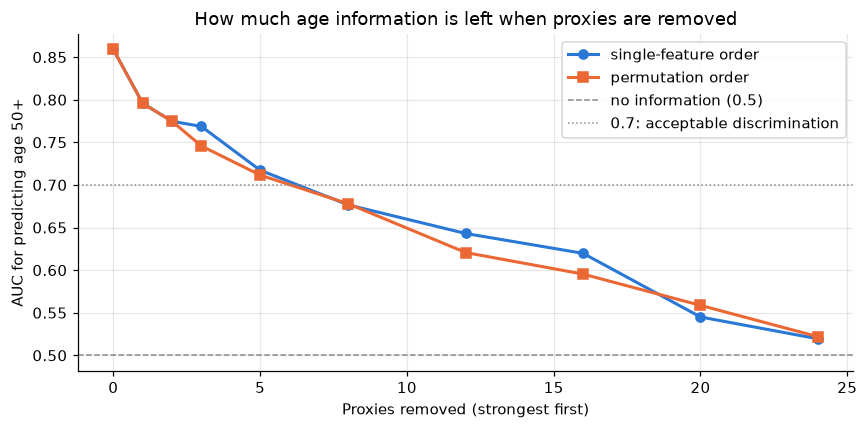

order used in section 7: permutation order; numbers of proxies tested: [0, 1, 3, 5, 8, 12]
their age predictability: {0: 0.859, 1: 0.796, 3: 0.746, 5: 0.712, 8: 0.678, 12: 0.621}


In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(proxy_curve.index, proxy_curve['single-feature order'], marker='o', color=BLUE, linewidth=2, label='single-feature order')
ax.plot(proxy_curve.index, proxy_curve['permutation order'], marker='s', color=ORANGE, linewidth=2, label='permutation order')
ax.axhline(0.5, color=GREY, linestyle='--', linewidth=1, label='no information (0.5)')
ax.axhline(0.7, color=GREY, linestyle=':', linewidth=1, label='0.7: acceptable discrimination')
ax.set_xlabel('Proxies removed (strongest first)')
ax.set_ylabel('AUC for predicting age 50+')
ax.set_title('How much age information is left when proxies are removed')
ax.legend()
plt.tight_layout()
plt.show()

# The order that lowers age predictability faster (lower mean AUC over the grid) is used in section 7
PROXY_ORDER_NAME = proxy_curve.mean().idxmin()
PROXY_ORDER = PERMUTATION_ORDER if PROXY_ORDER_NAME == 'permutation order' else SINGLE_ORDER
PROXY_GRID = [k for k in [0, 1, 3, 5, 8, 12] if k < n_features]   # the numbers of proxies tested in section 7
print(f'order used in section 7: {PROXY_ORDER_NAME}; numbers of proxies tested: {PROXY_GRID}')
print('their age predictability:', proxy_curve.loc[PROXY_GRID, PROXY_ORDER_NAME].round(3).to_dict())

**Key Findings**
- **The rule picks the groups of earlier notebooks.** On training months 0-3 it chooses income 0.9, employment CC and housing BA, the same groups notebook 04 flagged. Their fraud rates in months 6-7 are 2.5%, 3.1% and 4.5%, against 1.4% overall; the 50+ group has 2.9%. All four groups have 1.8 to 3.2 times the average fraud rate, so a model that works will flag them more often.
- **Employment CC is mostly an age group.** 5,024 of its 6,511 test applications (77%) are aged 50+, and only 26 fraud cases are under 50, so its recall cannot be measured for the under-50 cell (below 50 cases). Conclusions about employment CC independent of age are not possible with this data.
- **Every other intersection is large enough** to measure both FPR and recall. Within each age group the second-tier group still has the higher fraud rate (for example 6.4% against 1.4% for 50+ with and without housing BA), so the second-tier effects are not just age.
- **Age is spread over many features.** The strongest single proxy is `date_of_birth_distinct_emails_4w` (AUC 0.19, which is 0.81 turned around: more emails per date of birth go with younger applicants), then `housing_status` (0.66), `current_address_months_count` (0.63), `phone_home_valid` (0.62), `employment_status` (0.61) and `device_os` (0.60). Together, a small model that never sees `customer_age` still predicts age 50+ with AUC 0.86, and removing the 12 strongest single-feature proxies still leaves 0.64. Dropping the column `customer_age` therefore cannot remove age from the model.
- **Dropping customer_age cannot remove age from the model**. A small model that never sees customer_age still predicts age 50+ with AUC 0.86. Removing the strongest proxy brings it to 0.80, and removing the 12 strongest still leaves about 0.62–0.64 (depending on the order). The curve never flattens, so no small set of proxies removes age.
- **Consequence for the mitigations**. Because age sits in many features, later sections tests a grid of proxy counts (0, 1, 3, 5, 8, 12) and chooses on month 4, instead of assuming one number. It also explains why “drop age” alone is expected to close only part of the gap.

## **3. Baseline Findings on Base Variant**
The frozen model on Base months 6-7, with the frozen threshold of each seed (mean over the 5 seeds). Everything is compared between applicants aged 50+ and under 50.

### **3.1 All Metrics, with Intervals**
- Result: FPR 12.7% vs 3.9% (predictive equality ratio 0.31, interval 0.30–0.32); recall 0.70 vs 0.49; both far below the 0.8 reference

In [16]:
start = time.time()
rate_table, gap_table = fairness_summary(y_test, old_test, flags_test)
print(f'{N_BOOTSTRAP:,} resamples in {(time.time() - start) / 60:.1f} min')


def four_fifths_status(row):
    if not row.name.endswith('ratio'):
        return ''
    if row['CI high'] < FOUR_FIFTHS:
        return 'clearly below 0.8'
    if row['CI low'] >= FOUR_FIFTHS:
        return 'clearly at or above 0.8'
    return 'unclear'


gap_table['against the 0.8 reference'] = gap_table.apply(four_fifths_status, axis=1)
rate_table.round(4)

1,000 resamples in 0.1 min


estimate  CI low  CI high
group    metric                                          
50+      share of applications    0.1648  0.1632   0.1662
         fraud rate               0.0293  0.0275   0.0311
         flag rate                0.1434  0.1396   0.1469
         TPR (recall)             0.6997  0.6710   0.7279
         FPR                      0.1266  0.1233   0.1301
         precision (PPV)          0.1428  0.1332   0.1525
under 50 share of applications    0.8352  0.8338   0.8368
         fraud rate               0.0110  0.0105   0.0116
         flag rate                0.0439  0.0429   0.0448
         TPR (recall)             0.4891  0.4683   0.5111
         FPR                      0.0389  0.0380   0.0397
         precision (PPV)          0.1230  0.1163   0.1308

In [17]:
gap_table.round(4)

,estimate,CI low,CI high,against the 0.8 reference
measure,,,,
demographic parity ratio,0.3059,0.2961,0.3163,clearly below 0.8
equal opportunity ratio,0.6991,0.6611,0.7442,clearly below 0.8
predictive equality ratio,0.3072,0.2964,0.3177,clearly below 0.8
predictive parity ratio,0.8612,0.7933,0.9436,unclear
flag rate difference,0.0996,0.0959,0.1032,
TPR difference,0.2105,0.1744,0.2447,
FPR difference,0.0877,0.0844,0.0914,
equalised odds difference,0.2105,0.1744,0.2447,


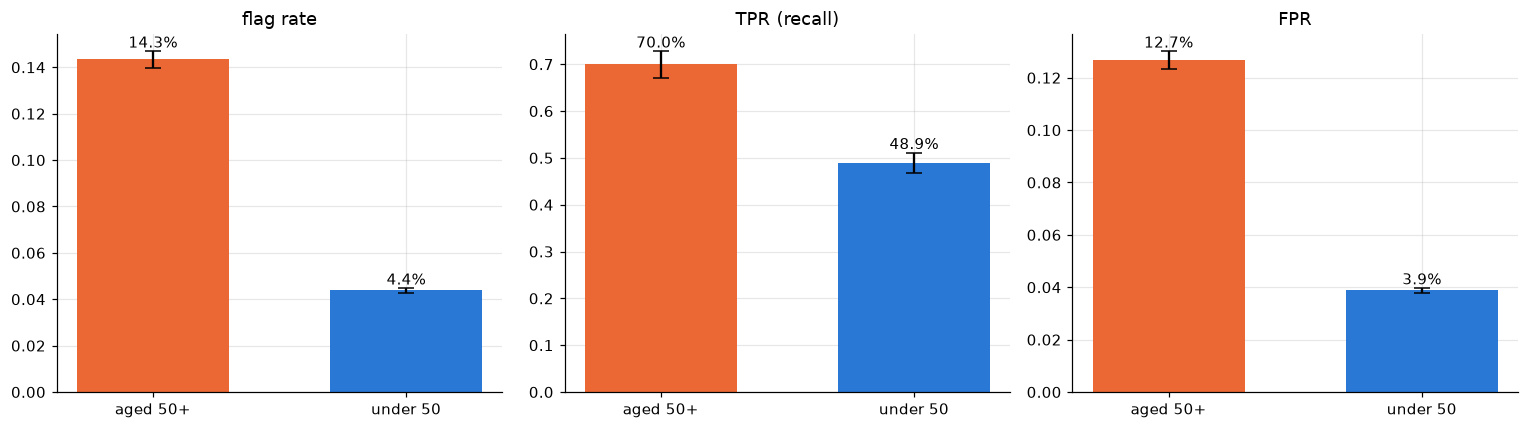

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ['flag rate', 'TPR (recall)', 'FPR']):
    for i, (label, colour) in enumerate([('50+', ORANGE), ('under 50', BLUE)]):
        row = rate_table.loc[(label, metric)]
        ax.bar(i, row['estimate'], color=colour, width=0.6)
        ax.errorbar(i, row['estimate'], yerr=[[row['estimate'] - row['CI low']], [row['CI high'] - row['estimate']]],
                    color='black', capsize=5)
        ax.text(i, row['CI high'], f"{row['estimate']:.1%}", ha='center', va='bottom')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['aged 50+', 'under 50'])
    ax.set_title(metric)
    ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

### **3.2 Are the Differences Real or Chance?**
- Two-proportion z-tests for the three rates, using seed 0 (the seeds score the same applicants, so they are not independent samples). With about 200,000 applications almost any difference gives a tiny p-value, so the test is a floor, not a verdict: **how big** the gap is (the ratio and its interval above) matters more than whether it is zero.
- Result: z above 60 for the flag rate and FPR, but with 200,000 applications the size of the gap matters more than the p-value

In [19]:
def two_proportion_test(successes_a, n_a, successes_b, n_b):
    p_a, p_b = successes_a / n_a, successes_b / n_b
    pooled = (successes_a + successes_b) / (n_a + n_b)
    z = (p_a - p_b) / np.sqrt(pooled * (1 - pooled) * (1 / n_a + 1 / n_b))
    return z, 2 * stats.norm.sf(abs(z))


flagged0 = flags_test[0]
fraud_mask, genuine_mask = y_test == 1, y_test == 0
rows = []
for name, population in [('flag rate (all applications)', np.ones_like(fraud_mask)),
                         ('TPR (fraud cases)', fraud_mask), ('FPR (genuine applications)', genuine_mask)]:
    a, b = population & old_test, population & ~old_test
    z, p = two_proportion_test(flagged0[a].sum(), a.sum(), flagged0[b].sum(), b.sum())
    rows.append({'rate': name, '50+': flagged0[a].mean(), 'under 50': flagged0[b].mean(), 'z': z, 'p-value': p})
pd.DataFrame(rows).set_index('rate').round(4)

,50+,under 50,z,p-value
rate,,,,
flag rate (all applications),0.1439,0.0438,70.6924,0.0
TPR (fraud cases),0.7017,0.4902,10.8642,0.0
FPR (genuine applications),0.1271,0.0388,65.2722,0.0


### **3.3 Is the Gap Stable over Time?**
- The same comparison on every month of Base with the same frozen thresholds. A gap that is steady across all of them is a feature of the model and the data; a gap that grows or shrinks is drift.
- Result: Predictive equality is 0.23–0.32 in every month, steady, with a slight rise (0.23 in month 0 to about 0.31 in months 4–7)

In [20]:
rows = []
for month in sorted(base['month'].unique()):
    part = base[base['month'] == month]
    flags = {seed: part[f'score_seed{seed}'].to_numpy() >= thresholds[seed] for seed in SEEDS}
    rates_m, gaps_m = fairness_summary(part['y_true'].to_numpy(), part['age_50_plus'].to_numpy(), flags)
    rows.append({'month': month, 'applications': len(part),
                 **{f'{m} {g}': rates_m.loc[(g, m), 'estimate'] for g in ['50+', 'under 50'] for m in ['FPR', 'TPR (recall)']},
                 'predictive equality ratio': gaps_m.loc['predictive equality ratio', 'estimate'],
                 'PE CI low': gaps_m.loc['predictive equality ratio', 'CI low'],
                 'PE CI high': gaps_m.loc['predictive equality ratio', 'CI high'],
                 'equal opportunity ratio': gaps_m.loc['equal opportunity ratio', 'estimate']})
by_month = pd.DataFrame(rows).set_index('month')
by_month.round(4)

,applications,FPR 50+,TPR (recall) 50+,FPR under 50,TPR (recall) under 50,predictive equality ratio,PE CI low,PE CI high,equal opportunity ratio
month,,,,,,,,,
0,132440,0.1163,0.6780,0.0267,0.4100,0.2293,0.2190,0.2403,0.6047
1,127620,0.1098,0.7401,0.0287,0.4868,0.2612,0.2491,0.2745,0.6578
2,136979,0.1086,0.7262,0.0261,0.4395,0.2406,0.2291,0.2532,0.6052
3,150936,0.1669,0.8017,0.0477,0.6392,0.2860,0.2765,0.2964,0.7974
4,127691,0.1759,0.7763,0.0550,0.5950,0.3126,0.3009,0.3246,0.7664
5,119323,0.1137,0.7153,0.0366,0.4561,0.3222,0.3068,0.3367,0.6376
6,108168,0.1320,0.6872,0.0415,0.4796,0.3145,0.3000,0.3279,0.6979
7,96843,0.1177,0.7167,0.0362,0.4974,0.3075,0.2908,0.3283,0.6940


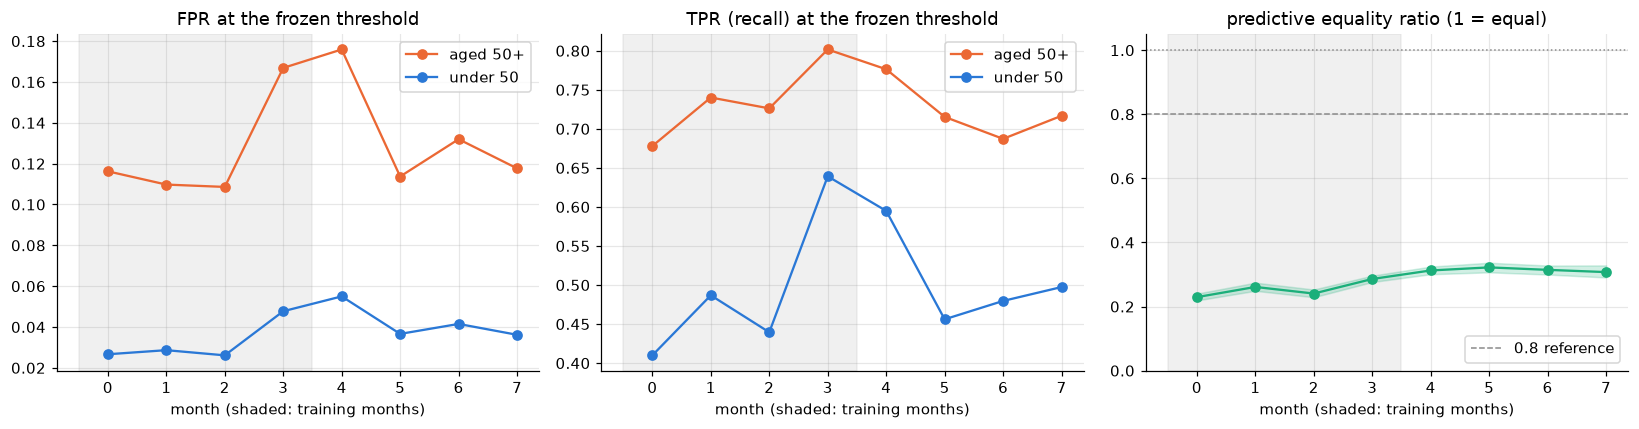

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax in axes:
    ax.axvspan(-0.5, 3.5, color=GREY, alpha=0.12)
    ax.set_xlabel('month (shaded: training months)')
axes[0].plot(by_month.index, by_month['FPR 50+'], marker='o', color=ORANGE, label='aged 50+')
axes[0].plot(by_month.index, by_month['FPR under 50'], marker='o', color=BLUE, label='under 50')
axes[0].set_title('FPR at the frozen threshold')
axes[0].legend()
axes[1].plot(by_month.index, by_month['TPR (recall) 50+'], marker='o', color=ORANGE, label='aged 50+')
axes[1].plot(by_month.index, by_month['TPR (recall) under 50'], marker='o', color=BLUE, label='under 50')
axes[1].set_title('TPR (recall) at the frozen threshold')
axes[1].legend()
axes[2].plot(by_month.index, by_month['predictive equality ratio'], marker='o', color=GREEN)
axes[2].fill_between(by_month.index, by_month['PE CI low'], by_month['PE CI high'], color=GREEN, alpha=0.2)
axes[2].axhline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1, label='0.8 reference')
axes[2].axhline(1, color=GREY, linestyle=':', linewidth=1)
axes[2].set_ylim(0, 1.05)
axes[2].set_title('predictive equality ratio (1 = equal)')
axes[2].legend()
plt.tight_layout()
plt.show()

### **3.4 Does the Gap Depend on the FPR Budget?**
- Does it vanish at a different review size?
- The project flags 5% of genuine applications. A bank might review fewer (1%) or more (10%). For each budget, each seed's threshold is set on **month 5** as in notebook 02 (the threshold that flags that share of genuine month-5 applications) and applied to the test months. At 5% this reproduces the frozen thresholds, which is checked. 5% is the project's budget; 1% is 5 times stricter and 10% twice as generous, so one table shows whether the gap depends on the budget.
- Result: No; ratio 0.21 at 1% FPR, 0.31 at 5%, 0.37 at 10%, so it narrows slowly but stays far below 0.8

In [22]:
def threshold_at_fpr(y_true, scores_, target_fpr):
    """Copied from notebook 02, section 2: the last cut-off that stays within the FPR budget."""
    fpr, tpr, cut_offs = roc_curve(y_true, scores_)
    return cut_offs[np.searchsorted(fpr, target_fpr, side='right') - 1]


month5_y = month5['y_true'].to_numpy()
budget_thresholds = {budget: {seed: threshold_at_fpr(month5_y, month5[f'score_seed{seed}'].to_numpy(), budget) for seed in SEEDS}
                     for budget in FPR_BUDGETS}
assert all(np.isclose(budget_thresholds[TARGET_FPR][seed], thresholds[seed]) for seed in SEEDS), 'the 5% thresholds differ from the frozen ones'

rows = []
for budget in FPR_BUDGETS:
    flags = {seed: test[f'score_seed{seed}'].to_numpy() >= budget_thresholds[budget][seed] for seed in SEEDS}
    rates_b, gaps_b = fairness_summary(y_test, old_test, flags)
    rows.append({'FPR budget': budget,
                 'overall FPR': np.mean([flags[s][y_test == 0].mean() for s in SEEDS]),
                 'FPR 50+': rates_b.loc[('50+', 'FPR'), 'estimate'], 'FPR under 50': rates_b.loc[('under 50', 'FPR'), 'estimate'],
                 'predictive equality ratio': gaps_b.loc['predictive equality ratio', 'estimate'],
                 'PE CI low': gaps_b.loc['predictive equality ratio', 'CI low'], 'PE CI high': gaps_b.loc['predictive equality ratio', 'CI high'],
                 'TPR 50+': rates_b.loc[('50+', 'TPR (recall)'), 'estimate'], 'TPR under 50': rates_b.loc[('under 50', 'TPR (recall)'), 'estimate'],
                 'equal opportunity ratio': gaps_b.loc['equal opportunity ratio', 'estimate'],
                 'equalised odds difference': gaps_b.loc['equalised odds difference', 'estimate']})
by_budget = pd.DataFrame(rows).set_index('FPR budget')
by_budget.round(4)

,overall FPR,FPR 50+,FPR under 50,predictive equality ratio,PE CI low,PE CI high,TPR 50+,TPR under 50,equal opportunity ratio,equalised odds difference
FPR budget,,,,,,,,,,
0.01,0.0115,0.0340,0.0072,0.2113,0.1955,0.2282,0.4206,0.2033,0.4833,0.2173
0.05,0.0531,0.1266,0.0389,0.3072,0.2964,0.3177,0.6997,0.4891,0.6991,0.2105
0.10,0.1051,0.2215,0.0826,0.3729,0.3638,0.3814,0.8247,0.6353,0.7703,0.1894


### **3.5 The Same Ranking, a Different Operating Point?**
- If each group's own recall at 5% FPR is similar, the model ranks the two groups about equally well, and the gap comes from using **one threshold for two groups whose scores sit at different levels**. The ROC curves test this: if the curves overlap, the ranking is equally good for both groups and the gap is a matter of where the shared threshold cuts. The dots mark where the frozen threshold lands in each group (seed 0).
- Each group's **own recall at 5% FPR** (the threshold chosen separately inside each group) is computed with the same weighted method as notebook 04, with an interval, together with the group's AUC.
- Is the model worse at ranking older applicants?
- Result: No; the ROC curves nearly coincide (AUC 0.885 vs 0.887) and recall at 5% FPR inside each group is 0.50 vs 0.53, difference −0.03 (interval includes zero)

In [23]:
def within_group_recall_at_fpr(W, y, s, target=TARGET_FPR):
    """Recall at the cut-off that flags `target` of the genuine applications, for each row of W (weights).
    Scores are treated as distinct (ties are negligible with continuous scores)."""
    order = np.argsort(-s, kind='mergesort')
    fraud = (y[order] == 1)
    w = np.asarray(W, dtype=np.float32)[:, order]
    tp = np.cumsum(w * fraud, axis=1)
    fp = np.cumsum(w * ~fraud, axis=1)
    within = (fp / fp[:, -1:] <= target).sum(axis=1)
    index = np.maximum(within - 1, 0)
    return np.where(within > 0, tp[np.arange(len(w)), index], 0) / tp[:, -1]


def bootstrap_within_recall(y, s_by_seed, n_resamples=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED, batch=50):
    """Mean over seeds of the within-group recall at 5% FPR, on the real data (first value) and each resample."""
    rng = np.random.default_rng(rng_seed)
    results = []
    for start in range(0, n_resamples, batch):
        W = rng.poisson(1.0, size=(min(batch, n_resamples - start), len(y))).astype(np.float32)
        results.append(np.mean([within_group_recall_at_fpr(W, y, s) for s in s_by_seed], axis=0))
    estimate = np.mean([within_group_recall_at_fpr(np.ones((1, len(y))), y, s) for s in s_by_seed])
    return estimate, np.concatenate(results)


own_recall = {}
for label, mask in [('50+', old_test), ('under 50', ~old_test)]:
    y_g = y_test[mask]
    s_g = [test.loc[mask, f'score_seed{seed}'].to_numpy() for seed in SEEDS]
    estimate, resampled = bootstrap_within_recall(y_g, s_g)
    own_recall[label] = (estimate, resampled)

difference = own_recall['50+'][1] - own_recall['under 50'][1]
rows = []
for label, mask in [('50+', old_test), ('under 50', ~old_test)]:
    estimate, resampled = own_recall[label]
    rows.append({'group': label, 'AUC (mean over seeds)': np.mean([roc_auc_score(y_test[mask], test.loc[mask, f'score_seed{s}']) for s in SEEDS]),
                 'recall at 5% FPR inside the group': estimate,
                 'CI low': np.quantile(resampled, 0.025), 'CI high': np.quantile(resampled, 0.975),
                 'recall at the frozen threshold': rate_table.loc[(label, 'TPR (recall)'), 'estimate'],
                 'FPR at the frozen threshold': rate_table.loc[(label, 'FPR'), 'estimate']})
within_group = pd.DataFrame(rows).set_index('group')
print(f'recall at 5% FPR inside the group, 50+ minus under 50: {own_recall["50+"][0] - own_recall["under 50"][0]:+.4f} '
      f'(95% CI {np.quantile(difference, 0.025):+.4f} to {np.quantile(difference, 0.975):+.4f})')
within_group.round(4)

recall at 5% FPR inside the group, 50+ minus under 50: -0.0308 (95% CI -0.0686 to +0.0083)


,AUC (mean over seeds),recall at 5% FPR inside the group,CI low,CI high,recall at the frozen threshold,FPR at the frozen threshold
group,,,,,,
50+,0.8847,0.5013,0.4694,0.5351,0.6997,0.1266
under 50,0.8870,0.5321,0.5106,0.5557,0.4891,0.0389


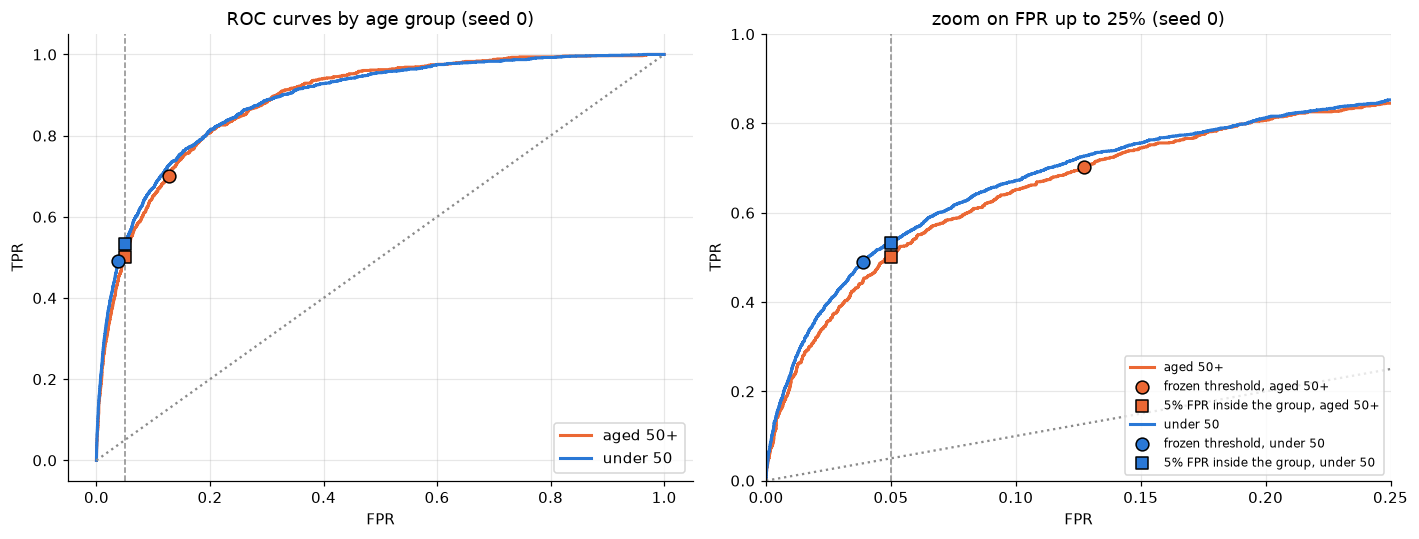

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, zoom in zip(axes, [False, True]):
    for label, mask, colour in [('aged 50+', old_test, ORANGE), ('under 50', ~old_test, BLUE)]:
        fpr_, tpr_, _ = roc_curve(y_test[mask], test.loc[mask, 'score_seed0'])
        ax.plot(fpr_, tpr_, color=colour, linewidth=2, label=label)
        group_key = '50+' if label == 'aged 50+' else 'under 50'
        point_fpr = (flags_test[0][mask & (y_test == 0)]).mean()
        point_tpr = (flags_test[0][mask & (y_test == 1)]).mean()
        ax.scatter([point_fpr], [point_tpr], color=colour, s=70, edgecolor='black', zorder=5,
                   label=f'frozen threshold, {label}' if zoom else None)
        ax.scatter([TARGET_FPR], [own_recall[group_key][0]], color=colour, s=70, marker='s', edgecolor='black', zorder=5,
                   label=f'5% FPR inside the group, {label}' if zoom else None)
    ax.plot([0, 1], [0, 1], color=GREY, linestyle=':')
    ax.axvline(TARGET_FPR, color=GREY, linestyle='--', linewidth=1)
    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')
    if zoom:
        ax.set_xlim(0, 0.25)
        ax.set_ylim(0, 1)
        ax.set_title('zoom on FPR up to 25% (seed 0)')
        ax.legend(fontsize=8, loc='lower right')
    else:
        ax.set_title('ROC curves by age group (seed 0)')
        ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### **3.6 Calibration by Group**
- Does a probability mean the same in both groups?
- Notebook 04 calibrated the scores with one Platt calibrator fitted on Base month 5 (`configs/calibration.json`). Here its probabilities are checked **separately for each age group** on the test months:
    - **Observed / expected (O/E):** actual fraud cases divided by the sum of predicted probabilities, with a 95% interval (1 = well calibrated, above 1 = the model under-calls fraud in that group).
    - **Calibration slope and intercept:** a logistic regression of the outcome on the model's log-odds, fitted within each group. A slope of 1 and an intercept of 0 is perfect; a slope below 1 means the probabilities are too extreme.
    - **Reliability table and plot:** 10 bins with equal numbers of applications over both groups together (so both groups use the same bins). A bin is plotted for a group only with at least 10 fraud cases and 10 genuine cases, the usual rule for a normal approximation of a proportion. Ten bins with equal numbers of applications are the usual choice for reliability plots and expected calibration error.
    - **Expected calibration error (ECE):** the average gap between predicted and observed rate over the bins, weighted by the number of applications.
- Result: Observed/expected 1.08 and 1.14, slopes 0.95 and 0.97, ECE 0.003 and 0.001, so calibration is not what produces the gap

In [25]:
p_test = {seed: calibrate(test[f'score_seed{seed}'].to_numpy(), seed) for seed in SEEDS}


def observed_over_expected(y, is_a, p_by_seed, n_resamples=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED, batch=50):
    """O/E of each group (mean over seeds), real and bootstrap."""
    masks = {'50+': is_a, 'under 50': ~is_a}
    columns = [y * m for m in masks.values()] + [p * m for p in p_by_seed.values() for m in masks.values()]
    M = np.column_stack(columns).astype(np.float64)
    rng = np.random.default_rng(rng_seed)

    def oe(W):
        S = W @ M
        observed = S[:, :2]
        expected = np.stack([S[:, 2 + 2 * k: 4 + 2 * k] for k in range(len(p_by_seed))])   # seed x row x group
        return np.mean(observed[None] / expected, axis=0)

    estimate = oe(np.ones((1, len(y))))[0]
    resampled = np.concatenate([oe(rng.poisson(1.0, size=(min(batch, n_resamples - s), len(y))).astype(np.float64))
                                for s in range(0, n_resamples, batch)])
    return estimate, resampled


estimate, resampled = observed_over_expected(y_test, old_test, p_test)
rows = []
for g, label in enumerate(['50+', 'under 50']):
    mask = old_test if label == '50+' else ~old_test
    p0 = np.clip(p_test[0][mask], 1e-6, 1 - 1e-6)
    fit = LogisticRegression(C=1e6, max_iter=1000).fit(np.log(p0 / (1 - p0)).reshape(-1, 1), y_test[mask])   # C large: no penalty
    rows.append({'group': label, 'mean predicted probability': np.mean([p_test[s][mask].mean() for s in SEEDS]),
                 'actual fraud rate': y_test[mask].mean(),
                 'O/E': estimate[g], 'O/E CI low': np.quantile(resampled[:, g], 0.025), 'O/E CI high': np.quantile(resampled[:, g], 0.975),
                 'calibration slope (seed 0)': fit.coef_[0, 0], 'calibration intercept (seed 0)': fit.intercept_[0]})
calibration_by_group = pd.DataFrame(rows).set_index('group')
calibration_by_group.round(4)

,mean predicted probability,actual fraud rate,O/E,O/E CI low,O/E CI high,calibration slope (seed 0),calibration intercept (seed 0)
group,,,,,,,
50+,0.0271,0.0293,1.0811,1.0184,1.1414,0.9478,-0.0422
under 50,0.0097,0.0110,1.1412,1.0923,1.1932,0.9719,0.0550


expected calibration error (seed 0, 10 equal-count bins over both groups): {'50+': np.float64(0.0027), 'under 50': np.float64(0.0014)}


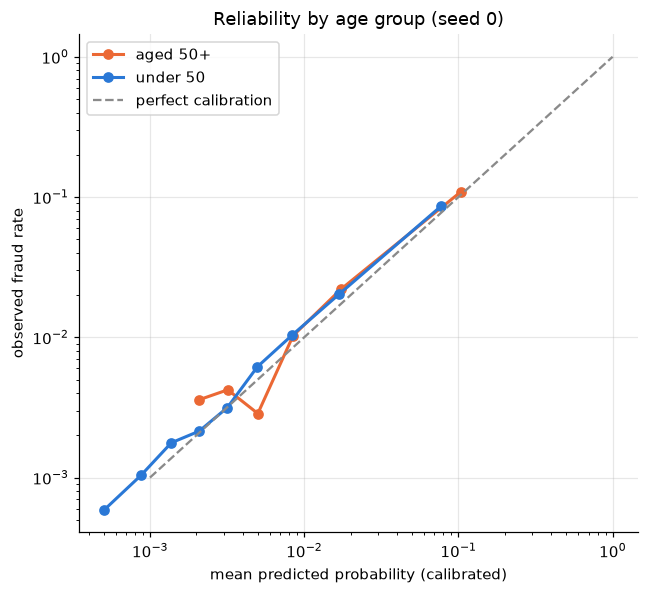

applications  fraud cases  genuine  mean predicted  \
group    bin                                                       
50+      0            1478            3     1475          0.0002   
         1            1894            0     1894          0.0005   
         2            2193            1     2192          0.0009   
         3            2429            2     2427          0.0014   
         4            2782           10     2772          0.0021   
         5            3077           13     3064          0.0032   
         6            3494           10     3484          0.0050   
         7            4083           42     4041          0.0085   
         8            5038          111     4927          0.0173   
         9            7311          797     6514          0.1037   
under 50 0           19023            5    19018          0.0002   
         1           18607           11    18596          0.0005   
         2           18308           19    18289          0.0009   
         3           18072           32    18040          0.0014   
         4           17719           38    17681          0.0021   
         5           17424           55    17369          0.0032   
         6           17007          105    16902          0.0050   
         7           16418          171    16247          0.0084   
         8           15463          314    15149          0.0169   
         9           13191         1139    12052          0.0774   

              observed fraud rate  plotted  
group    bin                                
50+      0                 0.0020    False  
         1                 0.0000    False  
         2                 0.0005    False  
         3                 0.0008    False  
         4                 0.0036     True  
         5                 0.0042     True  
         6                 0.0029     True  
         7                 0.0103     True  
         8                 0.0220     True  
         9                 0.1090     True  
under 50 0                 0.0003    False  
         1                 0.0006     True  
         2                 0.0010     True  
         3                 0.0018     True  
         4                 0.0021     True  
         5                 0.0032     True  
         6                 0.0062     True  
         7                 0.0104     True  
         8                 0.0203     True  
         9                 0.0863     True

In [26]:
edges = np.unique(np.quantile(p_test[0], np.linspace(0, 1, N_CALIBRATION_BINS + 1)))
bin_of = np.clip(np.digitize(p_test[0], edges[1:-1]), 0, len(edges) - 2)
rows = []
for label, mask in [('50+', old_test), ('under 50', ~old_test)]:
    for b in range(len(edges) - 1):
        m = mask & (bin_of == b)
        rows.append({'group': label, 'bin': b, 'applications': int(m.sum()), 'fraud cases': int(y_test[m].sum()),
                     'genuine': int((y_test[m] == 0).sum()),
                     'mean predicted': p_test[0][m].mean() if m.any() else np.nan,
                     'observed fraud rate': y_test[m].mean() if m.any() else np.nan})
reliability = pd.DataFrame(rows).set_index(['group', 'bin'])
reliability['plotted'] = (reliability['fraud cases'] >= 10) & (reliability['genuine'] >= 10)
ece = {label: np.nansum(np.where(reliability.loc[label, 'applications'] > 0,
                                 reliability.loc[label, 'applications'] * (reliability.loc[label, 'mean predicted'] - reliability.loc[label, 'observed fraud rate']).abs(),
                                 0)) / reliability.loc[label, 'applications'].sum() for label in ['50+', 'under 50']}
print('expected calibration error (seed 0, 10 equal-count bins over both groups):', {k: round(v, 4) for k, v in ece.items()})

fig, ax = plt.subplots(figsize=(6, 5.5))
for label, colour in [('50+', ORANGE), ('under 50', BLUE)]:
    part = reliability.loc[label]
    part = part[part['plotted']]
    ax.plot(part['mean predicted'], part['observed fraud rate'], marker='o', color=colour, linewidth=2, label=f'aged {label}' if label == '50+' else label)
low, high = 1e-3, 1
ax.plot([low, high], [low, high], color=GREY, linestyle='--', label='perfect calibration')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('mean predicted probability (calibrated)')
ax.set_ylabel('observed fraud rate')
ax.set_title('Reliability by age group (seed 0)')
ax.legend()
plt.tight_layout()
plt.show()
reliability.round(4)

**Key Findings**
- **The gap is large, and it is real.** With the frozen threshold, 14.3% of applicants aged 50+ are flagged against 4.4% of the others (demographic parity ratio 0.31, 95% interval 0.30-0.32). For genuine applicants the FPR is 12.7% against 3.9% (predictive equality ratio 0.307, interval 0.296-0.318), so a genuine 50+ applicant is wrongly flagged about 3.3 times as often. Both ratio intervals lie far below the 0.8 reference. The z-tests (z above 60 for the flag rate and the FPR) only confirm that this is not chance; the size of the gap is what matters.
- **Older applicants are also caught more often.** Recall is 0.70 against 0.49 (equal opportunity ratio 0.70, interval 0.66-0.74), so the equalised odds difference is 0.21, and it comes from the recall gap (0.21), not the FPR gap (0.088 in absolute terms). The gap is double-edged: the 50+ group is both over-flagged when genuine and better protected when it is a victim of fraud.
- **A flag means about the same in both groups.** Precision is 14.3% for 50+ against 12.3% under 50 (predictive parity ratio 0.86, interval 0.79-0.94, which neither clearly passes nor fails the 0.8 reference). The calibration check agrees: observed over expected is 1.08 (1.02-1.14) for 50+ and 1.14 (1.09-1.19) for under 50, so the model under-calls fraud by 8-14% in both groups. Calibration slopes are 0.95 and 0.97, intercepts -0.04 and +0.06, and the expected calibration error is 0.003 and 0.001. The calibrator is not what produces the gap.
- **The ranking is equally good for both groups.** The ROC curves almost coincide (AUC 0.885 against 0.887). Each group's recall at 5% FPR, with its own threshold, is 0.501 (0.469-0.535) for 50+ against 0.532 (0.511-0.556) for under 50, and the difference of -0.031 has an interval (-0.069 to +0.008) that includes zero. So the gap is not a worse ranking for older applicants. It is what happens when one threshold is applied to two groups with different fraud rates (2.9% against 1.1% in months 6-7, a ratio of 2.7, close to the FPR ratio of 3.3). This is the pattern predicted by the impossibility argument for fairness metrics: a model that is calibrated in each group, with different base rates, has different error rates.
- **What equal FPR would cost.** If each group had its own threshold at 5% FPR, the 50+ group's recall would fall from 0.70 to 0.50 (about 20 points) and the under-50 group's would rise from 0.49 to 0.53 (4 points). This is the trade-off that group-specific thresholds carry in the mitigation experiments.
- **The gap is stable in ratio, not in level.** The predictive equality ratio is 0.31-0.32 in months 4-7 with overlapping intervals; it was lower, 0.23-0.29, in months 0-3, which the model was trained on. The FPRs themselves move a lot: for 50+ they range from 11% to 18% and for under 50 from 2.6% to 5.5%, with a peak in months 3 and 4 for both groups (recall also peaks in month 3, at 0.80 for 50+ and 0.64 for under 50). The frozen threshold flags more in those months, so the level of the gap moves with the alert rate while the ratio stays put. The unequal treatment is structural; only its level drifts.
- **It holds at every FPR budget.** The predictive equality ratio is 0.21 at a 1% budget, 0.31 at 5% and 0.37 at 10%, so it is worst when review capacity is tightest. The equalised odds difference stays between 0.19 and 0.22 at all three, and at a 1% budget genuine 50+ applicants are flagged 3.4% of the time against 0.7%.

## **4. Why Is There a Gap?**
The earlier measurements showed that the model ranks both age groups equally well, so the gap comes from where one shared threshold falls on the two groups’ scores. This section asks why the scores of genuine older applicants sit higher. There are three candidate causes:
1. **Real risk.** real risk (older applicants have about 2.7 times the fraud rate, 2.9% against 1.1%)
2. **The direct use of `customer_age`.** The model adds a positive contribution for age 50+.
3. **Proxies of age.** Other features that track age carry the same effect without the column.
This section measures them with the frozen model, with no retraining.

**Key Findings**
- The shift is real, spread over the whole score distribution, and not specific to innocent customers.
- The direct use of age explains about a quarter of the distance to parity, and removing it costs little recall.
- Three quarters of the gap remains, carried by many proxies, so dropping the age column alone cannot fix it.

### **4.1 How Do the Scores of Genuine Applicants Differ?**
The FPR depends only on the scores of genuine applicants, so this compares their calibrated log-odds by age group and asks whether the score carries age information (AUC for telling 50+ from under 50). The same AUC among fraud cases shows whether the shift is there for fraud too.

**Key Findings**
- Genuine 50+ applicants score 0.94 log-odds higher on average (mean −5.11 against −6.05; median −5.18 against −6.14).
- The whole distribution is shifted, not just a tail: the gap is about 1 log-odds at the 90th, 95th and 99th percentiles too (−2.81 against −3.97, −2.14 against −3.30, −1.00 against −2.04). Against a threshold of −3.07, that puts 12.7% of genuine 50+ applicants above it against 3.9% of the others.
- The score separates the two age groups about equally well among genuine applicants (AUC 0.656) and among fraud cases (0.663), so older applicants score higher whether they are genuine or not. This is what a model that has learned that age goes with fraud risk would produce.

In [27]:
margin_test = {seed: np.log(p_test[seed] / (1 - p_test[seed])) for seed in SEEDS}      # calibrated log-odds
threshold_margin = {seed: float(np.log(calibrate(thresholds[seed], seed) / (1 - calibrate(thresholds[seed], seed)))) for seed in SEEDS}
genuine_test = y_test == 0

rows = []
for label, mask in [('50+', old_test), ('under 50', ~old_test)]:
    rows.append({'group': label, 'genuine applications': int((mask & genuine_test).sum()),
                 'mean': np.mean([margin_test[s][mask & genuine_test].mean() for s in SEEDS]),
                 **{f'{q}th percentile': np.mean([np.percentile(margin_test[s][mask & genuine_test], q) for s in SEEDS]) for q in [50, 90, 95, 99]},
                 'share above the threshold (FPR)': rate_table.loc[(label, 'FPR'), 'estimate']})
score_shift = pd.DataFrame(rows).set_index('group')
print('threshold in calibrated log-odds (mean over seeds): %.3f' % np.mean(list(threshold_margin.values())))
print('mean difference between the groups among genuine applicants (50+ minus under 50): %.3f log-odds'
      % (score_shift.loc['50+', 'mean'] - score_shift.loc['under 50', 'mean']))

age_auc = pd.Series({
    'among genuine applications': np.mean([roc_auc_score(old_test[genuine_test], margin_test[s][genuine_test]) for s in SEEDS]),
    'among fraud cases': np.mean([roc_auc_score(old_test[~genuine_test], margin_test[s][~genuine_test]) for s in SEEDS]),
}, name='AUC for telling 50+ from under 50 with the score')
display(score_shift.round(3))
age_auc.round(3).to_frame()

threshold in calibrated log-odds (mean over seeds): -3.073
mean difference between the groups among genuine applicants (50+ minus under 50): 0.941 log-odds


,genuine applications,mean,50th percentile,90th percentile,95th percentile,99th percentile,share above the threshold (FPR)
group,,,,,,,
50+,32790,-5.114,-5.180,-2.813,-2.139,-0.998,0.127
under 50,169343,-6.054,-6.135,-3.967,-3.296,-2.038,0.039


,AUC for telling 50+ from under 50 with the score
among genuine applications,0.656
among fraud cases,0.663


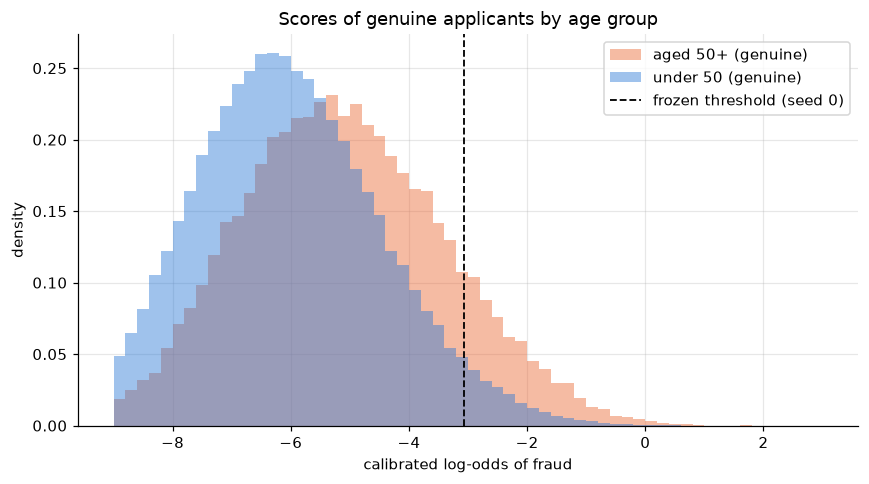

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(-9, 3, 61)
for label, mask, colour in [('aged 50+', old_test, ORANGE), ('under 50', ~old_test, BLUE)]:
    ax.hist(margin_test[0][mask & genuine_test], bins=bins, density=True, histtype='stepfilled', alpha=0.45, color=colour, label=f'{label} (genuine)')
ax.axvline(threshold_margin[0], color='black', linestyle='--', linewidth=1.2, label='frozen threshold (seed 0)')
ax.set_xlabel('calibrated log-odds of fraud')
ax.set_ylabel('density')
ax.set_title('Scores of genuine applicants by age group')
ax.legend()
plt.tight_layout()
plt.show()

### **4.2 What If the Model Could Not See Age? (The Direct Effect)**
A counterfactual with the frozen model: every applicant’s customer_age is replaced by one reference age, everything else is left as it is, and the applications are scored again. If the gap barely moves, the direct use of age is not the cause. The threshold is matched, so each seed flags the same share of genuine applications as before (5.3%) and any change is a redistribution. Every reference age with at least 1% of the training applications is tried (10, 20, 30, 40, 50, 60), plus the average over the training age distribution.

**Key Findings**
- The recomputed scores match the saved ones exactly (largest difference 0).
- Removing the age signal raises predictive equality from 0.31 to about 0.47 (interval 0.45–0.49), and equal opportunity from 0.70 to about 0.82. It does not depend on which age is used (0.45–0.47).
- The 50+ FPR falls from 12.7% to 9.6% and the FPR of the others rises from 3.9% to 4.5%, while overall recall falls by only 0.6 points (56.2% to 55.5%).
- So the direct use of age is a real part of the gap, about a quarter of the distance to parity, and cheap to remove. Three quarters remain: the ratio stays far below 0.8.
- With the unmatched frozen threshold the overall FPR swings from 3% to 9% depending on the reference age, which is why the matched table is the one to use.

In [29]:
models = {seed: load_model(f"../outputs/models/{final_model['model']}_seed{seed}.joblib") for seed in SEEDS}
raw_test = base_raw.loc[test['row_id'].to_numpy()]
X_real = make_features(raw_test, **FEATURES)

recomputed = {seed: models[seed].predict_proba(X_real)[:, 1] for seed in SEEDS}
print('largest difference between the recomputed scores and the saved scores: %.1e'
      % max(np.abs(recomputed[seed] - test[f'score_seed{seed}'].to_numpy()).max() for seed in SEEDS))

age_share = train_raw['customer_age'].value_counts(normalize=True).sort_index()
REFERENCE_AGES = [int(a) for a in age_share[age_share >= 0.01].index]
reference_weights = age_share.loc[REFERENCE_AGES] / age_share.loc[REFERENCE_AGES].sum()
print('reference ages (at least 1% of the training applications) and their weights:')
print(reference_weights.round(3).to_dict())

start = time.time()
counterfactual_scores = {}   # (reference, seed) -> scores
for age in REFERENCE_AGES:
    X_age = make_features(raw_test.assign(customer_age=age), **FEATURES)
    for seed in SEEDS:
        counterfactual_scores[(age, seed)] = models[seed].predict_proba(X_age)[:, 1]
for seed in SEEDS:
    counterfactual_scores[('average', seed)] = sum(reference_weights[age] * counterfactual_scores[(age, seed)] for age in REFERENCE_AGES)
print(f'{len(REFERENCE_AGES)} reference ages x {len(SEEDS)} seeds scored in {(time.time() - start) / 60:.1f} min')

largest difference between the recomputed scores and the saved scores: 0.0e+00
reference ages (at least 1% of the training applications) and their weights:
{10: 0.018, 20: 0.249, 30: 0.324, 40: 0.223, 50: 0.149, 60: 0.036}


6 reference ages x 5 seeds scored in 0.1 min


In [30]:
def counterfactual_flags(reference, matched=True):
    flags = {}
    for seed in SEEDS:
        s = counterfactual_scores[(reference, seed)]
        if matched:   # the same share of genuine applications flagged as with the real scores
            target = flags_test[seed][genuine_test].mean()
            cut = np.quantile(s[genuine_test], 1 - target)
        else:
            cut = thresholds[seed]
        flags[seed] = s >= cut
    return flags


def counterfactual_row(label, flags, n_resamples=200):
    rates_c, gaps_c = fairness_summary(y_test, old_test, flags, n_resamples=n_resamples)   # 200 resamples: enough for a rough interval
    pe = gaps_c.loc['predictive equality ratio']
    return {'scores used': label,
            'overall FPR': np.mean([flags[s][genuine_test].mean() for s in SEEDS]),
            'overall recall': np.mean([flags[s][~genuine_test].mean() for s in SEEDS]),
            'FPR 50+': rates_c.loc[('50+', 'FPR'), 'estimate'], 'FPR under 50': rates_c.loc[('under 50', 'FPR'), 'estimate'],
            'predictive equality ratio': pe['estimate'], 'PE CI low': pe['CI low'], 'PE CI high': pe['CI high'],
            'TPR 50+': rates_c.loc[('50+', 'TPR (recall)'), 'estimate'], 'TPR under 50': rates_c.loc[('under 50', 'TPR (recall)'), 'estimate'],
            'equal opportunity ratio': gaps_c.loc['equal opportunity ratio', 'estimate']}


rows = [counterfactual_row('real ages (frozen threshold)', flags_test)]
for reference in REFERENCE_AGES + ['average']:
    label = f'age set to {reference}' if reference != 'average' else 'age averaged over its distribution'
    rows.append(counterfactual_row(label, counterfactual_flags(reference, matched=True)))
counterfactual_table = pd.DataFrame(rows).set_index('scores used')
counterfactual_table.round(4)

,overall FPR,overall recall,FPR 50+,FPR under 50,predictive equality ratio,PE CI low,PE CI high,TPR 50+,TPR under 50,equal opportunity ratio
scores used,,,,,,,,,,
real ages (frozen threshold),0.0531,0.5615,0.1266,0.0389,0.3072,0.2967,0.3202,0.6997,0.4891,0.6991
age set to 10,0.0531,0.5518,0.0981,0.0444,0.4532,0.4379,0.4726,0.6334,0.5091,0.8037
age set to 20,0.0531,0.5525,0.0978,0.0445,0.4550,0.4388,0.4754,0.6330,0.5104,0.8064
age set to 30,0.0531,0.5553,0.0957,0.0449,0.4692,0.4523,0.4898,0.6297,0.5164,0.8200
age set to 40,0.0531,0.5546,0.0956,0.0449,0.4697,0.4528,0.4903,0.6291,0.5156,0.8196
age set to 50,0.0531,0.5547,0.0949,0.0450,0.4745,0.4570,0.4942,0.6289,0.5158,0.8202
age set to 60,0.0531,0.5537,0.0952,0.0450,0.4724,0.4549,0.4911,0.6307,0.5134,0.8140
age averaged over its distribution,0.0531,0.5551,0.0960,0.0448,0.4668,0.4497,0.4879,0.6313,0.5152,0.8160


In [31]:
rows = [counterfactual_row('real ages (frozen threshold)', flags_test)]
for reference in REFERENCE_AGES + ['average']:
    label = f'age set to {reference}' if reference != 'average' else 'age averaged over its distribution'
    rows.append(counterfactual_row(label, counterfactual_flags(reference, matched=False)))
counterfactual_frozen = pd.DataFrame(rows).set_index('scores used')
print('Same table with the frozen threshold instead of the matched one (the overall number of flags changes):')
counterfactual_frozen[['overall FPR', 'overall recall', 'FPR 50+', 'FPR under 50', 'predictive equality ratio']].round(4)

Same table with the frozen threshold instead of the matched one (the overall number of flags changes):


,overall FPR,overall recall,FPR 50+,FPR under 50,predictive equality ratio
scores used,,,,,
real ages (frozen threshold),0.0531,0.5615,0.1266,0.0389,0.3072
age set to 10,0.0316,0.4466,0.0621,0.0256,0.4129
age set to 20,0.0408,0.4981,0.0776,0.0336,0.4331
age set to 30,0.0485,0.5359,0.0886,0.0407,0.4595
age set to 40,0.0478,0.5336,0.0875,0.0402,0.4592
age set to 50,0.0667,0.6008,0.1156,0.0573,0.4954
age set to 60,0.0943,0.6729,0.1548,0.0825,0.5331
age averaged over its distribution,0.0494,0.5396,0.0903,0.0415,0.4591


### **4.3 Which Features Carry the Difference?**
Among genuine applicants, the difference in average score between the groups is the sum, over features, of the differences in their average TreeSHAP contributions. Each feature’s share says how much of the shift it carries. Features are split into customer_age itself, the strongest k age proxies (k = 1, 3, 5, 8, 12, since no single number is right), and all others.

**Key Findings**
- The contributions add up to the total difference of 0.941 log-odds.
- customer_age carries 48% of the difference. This is more than its effect on the ratio in 4.2, because the two measure different things: the mean shift of everyone against the change in who passes one threshold.
- The rest is spread over many features: housing_status 18%, prev_address_months_count 16%, date_of_birth_distinct_emails_4w 15%, device_os 11%. Two features push the other way and offset part of the gap: phone_home_valid (−16%) and has_other_cards (−11%).
- The proxy share is not a smooth function of k: 15% for the top 1, 33% for the top 3, 28% for the top 5 (because phone_home_valid has a negative effect), 54% for the top 8 and 60% for the top 12, with the other features then at −8%. It is a spread, not a short list: the age information sits in many features at once.
- This analysis cannot say which of these are real differences in the applicants (housing status BA is a real fraud risk factor) and which are only correlated with age, which is why the cost of removing the proxies is measured with retrained models.

In [32]:
def shap_contributions(model, X):
    booster = model.get_booster()
    return booster.predict(xgb.DMatrix(X, enable_categorical=True), pred_contribs=True)   # one column per feature, then the baseline


calibration = json.load(open('../configs/calibration.json'))
group_of = {name: (name[:-len('_missing')] if name.endswith('_missing') else name) for name in X_real.columns}
GROUPS_OF_FEATURES = list(dict.fromkeys(group_of.values()))

start = time.time()
grouped_effect = {}   # seed -> (applications x feature groups), calibrated log-odds
additivity = []
for seed in SEEDS:
    contributions = shap_contributions(models[seed], X_real)
    a = calibration['seeds'][str(seed)]['a']
    margin_raw = np.log(recomputed[seed] / (1 - recomputed[seed]))
    additivity.append(np.abs(contributions.sum(axis=1) - margin_raw).max())
    per_column = pd.DataFrame(a * contributions[:, :-1], columns=X_real.columns)
    grouped_effect[seed] = per_column.T.groupby(group_of).sum().T[GROUPS_OF_FEATURES].to_numpy()
print(f'contributions computed in {(time.time() - start) / 60:.1f} min; largest difference between baseline + contributions and the model margin: {max(additivity):.1e}')
assert max(additivity) < 1e-3, 'the contributions do not add up to the model margin'

mean_50 = np.mean([grouped_effect[s][old_test & genuine_test].mean(axis=0) for s in SEEDS], axis=0)
mean_under = np.mean([grouped_effect[s][~old_test & genuine_test].mean(axis=0) for s in SEEDS], axis=0)
gap_by_feature = pd.DataFrame({'mean contribution 50+': mean_50, 'mean contribution under 50': mean_under,
                               'difference': mean_50 - mean_under}, index=GROUPS_OF_FEATURES)
total_gap = gap_by_feature['difference'].sum()
gap_by_feature['share of the difference'] = gap_by_feature['difference'] / total_gap
print('total difference in mean calibrated log-odds among genuine applicants: %.3f (section 4.1: %.3f)'
      % (total_gap, score_shift.loc['50+', 'mean'] - score_shift.loc['under 50', 'mean']))
gap_by_feature.sort_values('difference', key=np.abs, ascending=False).head(12).round(3)

contributions computed in 0.4 min; largest difference between baseline + contributions and the model margin: 1.1e-05
total difference in mean calibrated log-odds among genuine applicants: 0.941 (section 4.1: 0.941)


,mean contribution 50+,mean contribution under 50,difference,share of the difference
customer_age,0.300,-0.153,0.454,0.482
housing_status,0.018,-0.154,0.172,0.183
phone_home_valid,-0.248,-0.098,-0.150,-0.159
prev_address_months_count,-0.012,-0.157,0.145,0.155
date_of_birth_distinct_emails_4w,0.100,-0.037,0.137,0.146
device_os,-0.103,-0.208,0.105,0.111
has_other_cards,-0.177,-0.076,-0.101,-0.107
current_address_months_count,-0.062,-0.118,0.055,0.059
credit_risk_score,-0.015,-0.058,0.043,0.046
income,0.050,0.012,0.038,0.040


In [33]:
# The proxy audit ranked the raw columns; the model uses ratios in place of the four drifting ones (notebook 02),
# so a raw column stands for the ratio features built from it.
RATIOS_USING = {'velocity_6h': ['velocity_6h_vs_24h'], 'velocity_24h': ['velocity_6h_vs_24h', 'velocity_24h_vs_4w'],
                'velocity_4w': ['velocity_24h_vs_4w', 'zip_count_vs_velocity_4w'], 'zip_count_4w': ['zip_count_vs_velocity_4w']}


def model_features_of(columns):
    out = []
    for column in columns:
        out += RATIOS_USING.get(column, [column])
    return [f for f in dict.fromkeys(out) if f in gap_by_feature.index and f != 'customer_age']


rows = []
for k in [1, 3, 5, 8, 12]:
    proxies = model_features_of(PROXY_ORDER[:k])
    direct = gap_by_feature.loc['customer_age', 'difference']
    proxy_part = gap_by_feature.loc[proxies, 'difference'].sum()
    rows.append({'proxies counted (k)': k, 'direct: customer_age': direct / total_gap,
                 'proxies': proxy_part / total_gap, 'all other features': (total_gap - direct - proxy_part) / total_gap})
gap_split = pd.DataFrame(rows).set_index('proxies counted (k)')
print('Share of the difference in mean log-odds carried by the direct effect, by the strongest k proxies, and by everything else:')
gap_split.round(3)

Share of the difference in mean log-odds carried by the direct effect, by the strongest k proxies, and by everything else:


,direct: customer_age,proxies,all other features
proxies counted (k),,,
1,0.482,0.146,0.372
3,0.482,0.325,0.193
5,0.482,0.277,0.241
8,0.482,0.536,-0.019
12,0.482,0.599,-0.081


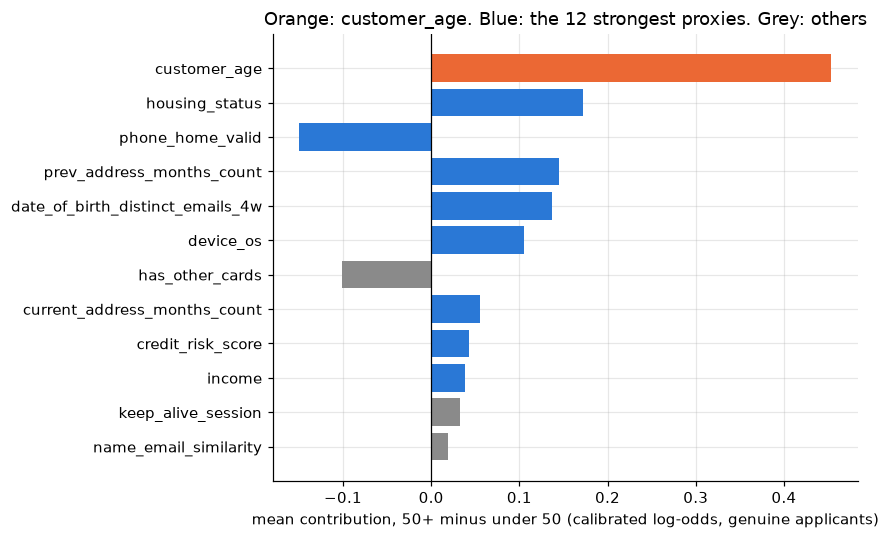

In [34]:
top = gap_by_feature.reindex(gap_by_feature['difference'].abs().sort_values(ascending=False).index).head(12)
strongest_12 = model_features_of(PROXY_ORDER[:12])
colours = [ORANGE if f == 'customer_age' else BLUE if f in strongest_12 else GREY for f in top.index]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(range(len(top)), top['difference'], color=colours)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top.index)
ax.invert_yaxis()
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('mean contribution, 50+ minus under 50 (calibrated log-odds, genuine applicants)')
ax.set_title('Orange: customer_age. Blue: the 12 strongest proxies. Grey: others')
plt.tight_layout()
plt.show()

## **5. Second-Tier Groups and Intersections**
Age is the main attribute, but the model may treat other groups unequally too. Two questions: do the second-tier groups (income 0.9, employment CC, housing BA, chosen by a rule on the training months) show gaps of the same kind as age, and **do those gaps survive once age is held fixed**? Each group is compared with everyone else at the frozen threshold, with the same measures and bootstrap as for age. Then each group is compared with the others **within each age band** (50+ and under 50). A cell is reported only if it has at least 1,000 applications (FPR) and, for recall, at least 50 fraud cases.

**Findings**
- Every second-tier group has a gap, and **housing BA has by far the largest**, larger than age on every measure.
- The housing and income gaps are **not an age effect**: they remain inside each age band. Employment CC is mostly an age effect.
- In every group and cell, the FPR follows the fraud rate. The gaps in age, housing and income are the same effect: a group with more fraud gets disproportionally more false alarms at one shared threshold.

### **5.1 The Gaps of the Second-Tier Groups**
Measure the gap of each second-tier group, so it can be compared with the age gap. The same measures as for age, with each group as the group of interest and everyone else as the reference, at the frozen threshold (1,000 bootstrap resamples per group). Age 50+ is shown for comparison.

**Findings**
- **Housing status BA** has FPR 20.8% against 1.7% (predictive equality 0.08, interval 0.079-0.086) and recall 72% against 30% (equal opportunity 0.41), and an equalised odds difference of 0.43. Its fraud rate is 4.5% against 0.7%. This is larger than the age gap (predictive equality 0.31, equalised odds difference 0.21) on every measure.
- **Income 0.9** has a gap similar to age: FPR 10.1% against 3.4% (predictive equality 0.33, interval 0.32-0.35), recall 0.65 against 0.46.
- **Employment CC** has FPR 12.6% against 5.1% (predictive equality 0.40, interval 0.38-0.43) and the smallest recall gap (equal opportunity 0.83). It is a small group (3.2% of applications).
- **Precision stays similar** (predictive parity 0.74-0.89): a flag means roughly the same thing in every group, as for age.

In [35]:
group_masks = {name: test[name].to_numpy() for name in GROUP_NAMES}
second_tier_results = {}
start = time.time()
for name in GROUP_NAMES:
    second_tier_results[name] = fairness_summary(y_test, group_masks[name], flags_test, labels=(name, f'not ({name})'))
print(f'{len(GROUP_NAMES)} groups, {N_BOOTSTRAP:,} resamples each, in {(time.time() - start) / 60:.1f} min')

rows = []
for name, (rates_g, gaps_g) in second_tier_results.items():
    rest = f'not ({name})'
    rows.append({
        'group': name, 'share of applications': rates_g.loc[(name, 'share of applications'), 'estimate'],
        'fraud rate': rates_g.loc[(name, 'fraud rate'), 'estimate'], 'fraud rate, others': rates_g.loc[(rest, 'fraud rate'), 'estimate'],
        'FPR': rates_g.loc[(name, 'FPR'), 'estimate'], 'FPR, others': rates_g.loc[(rest, 'FPR'), 'estimate'],
        'predictive equality ratio': gaps_g.loc['predictive equality ratio', 'estimate'],
        'PE CI low': gaps_g.loc['predictive equality ratio', 'CI low'], 'PE CI high': gaps_g.loc['predictive equality ratio', 'CI high'],
        'TPR': rates_g.loc[(name, 'TPR (recall)'), 'estimate'], 'TPR, others': rates_g.loc[(rest, 'TPR (recall)'), 'estimate'],
        'equal opportunity ratio': gaps_g.loc['equal opportunity ratio', 'estimate'],
        'EO CI low': gaps_g.loc['equal opportunity ratio', 'CI low'], 'EO CI high': gaps_g.loc['equal opportunity ratio', 'CI high'],
        'demographic parity ratio': gaps_g.loc['demographic parity ratio', 'estimate'],
        'predictive parity ratio': gaps_g.loc['predictive parity ratio', 'estimate'],
        'equalised odds difference': gaps_g.loc['equalised odds difference', 'estimate'],
    })
group_gaps = pd.DataFrame(rows).set_index('group')
group_gaps.round(4)

4 groups, 1,000 resamples each, in 0.3 min


,share of applications,fraud rate,"fraud rate, others",FPR,"FPR, others",predictive equality ratio,PE CI low,PE CI high,TPR,"TPR, others",equal opportunity ratio,EO CI low,EO CI high,demographic parity ratio,predictive parity ratio,equalised odds difference
group,,,,,,,,,,,,,,,,
age 50+,0.1648,0.0293,0.0110,0.1266,0.0389,0.3072,0.2964,0.3177,0.6997,0.4891,0.6991,0.6611,0.7442,0.3059,0.8612,0.2105
income = 0.9,0.2888,0.0251,0.0095,0.1013,0.0339,0.3347,0.3231,0.3471,0.6534,0.4634,0.7091,0.6633,0.7566,0.3301,0.8175,0.1901
employment_status = CC,0.0318,0.0310,0.0135,0.1258,0.0508,0.4037,0.3775,0.4347,0.6673,0.5535,0.8294,0.7560,0.9267,0.4036,0.8929,0.1138
housing_status = BA,0.1946,0.0448,0.0066,0.2078,0.0172,0.0827,0.0793,0.0862,0.7234,0.2967,0.4101,0.3703,0.4505,0.0824,0.7352,0.4267


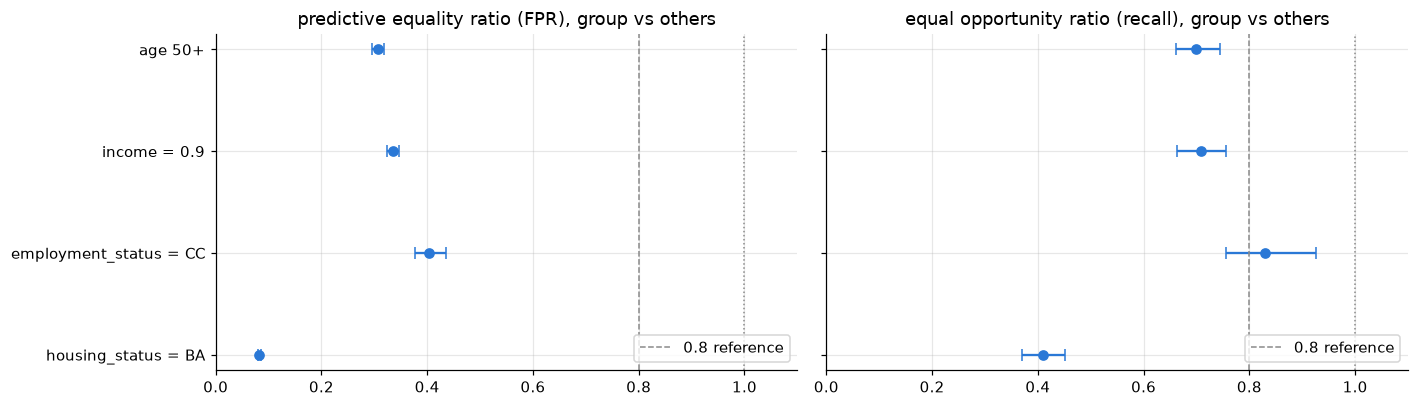

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
positions = np.arange(len(group_gaps))[::-1]
for ax, (col, title) in zip(axes, [('predictive equality ratio', 'predictive equality ratio (FPR)'),
                                    ('equal opportunity ratio', 'equal opportunity ratio (recall)')]):
    short = 'PE' if col.startswith('predictive') else 'EO'
    ax.errorbar(group_gaps[col], positions, xerr=[group_gaps[col] - group_gaps[f'{short} CI low'], group_gaps[f'{short} CI high'] - group_gaps[col]],
                fmt='o', color=BLUE, capsize=4)
    ax.axvline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1, label='0.8 reference')
    ax.axvline(1, color=GREY, linestyle=':', linewidth=1)
    ax.set_xlim(0, 1.1)
    ax.set_title(title + ', group vs others')
    ax.legend(loc='lower right')
axes[0].set_yticks(positions)
axes[0].set_yticklabels(group_gaps.index)
plt.tight_layout()
plt.show()

### **5.2 Do the Gaps Survive Holding Age Fixed?**
Separate an age effect from a gap of the group's own. If a gap is only an age effect, then within an age band the group would be treated like everyone else (a ratio near 1). For each second-tier group, in-group and out-of-group applicants are compared **within each age band** (50+, under 50): FPR and recall of the two. Cells below the size rules are skipped (FPR) or have their recall left blank (fewer than 50 fraud cases).

**Findings**
- **Housing BA is not an age effect.** Predictive equality is 0.17 within the 50+ band and 0.07 within the under-50 band (FPR 30.3% against 5.2%, and 17.5% against 1.2%).
- **Income 0.9 persists within each band:** 0.47 in 50+ (interval 0.44-0.49) and 0.29 under 50. It is not explained by age.
- **Employment CC is mostly an age effect.** Its predictive equality is 0.40 overall but 0.84 within 50+ (0.78-0.90), and 0.70 under 50 on a small cell (1,487 applications, interval 0.58-0.87). 5,024 of its 6,511 test applications are aged 50+, and the recall comparison under 50 cannot be made (fewer than 50 fraud cases).
- **The age gap is not a housing composition effect either.** Among BA applicants the under-50 FPR is 17.5% against 30.3% for 50+ (ratio 0.58), and among all others 1.2% against 5.2% (ratio 0.23): older applicants are over-flagged inside both housing groups. (31% of the 50+ group is BA against 17% of the others, which does contribute.)

In [37]:
rows = []
for name in SECOND_TIER:
    for age_label, age_mask in [('50+', old_test), ('under 50', ~old_test)]:
        in_group, rest = group_masks[name] & age_mask, ~group_masks[name] & age_mask
        if min(in_group.sum(), rest.sum()) < MIN_GROUP_ROWS:
            rows.append({'group': name, 'age': age_label, 'note': 'too few applications'})
            continue
        flags_s = {seed: flags_test[seed][age_mask] for seed in SEEDS}
        rates_s, gaps_s = fairness_summary(y_test[age_mask], group_masks[name][age_mask], flags_s, labels=(name, f'not ({name})'))
        recall_ok = min(y_test[in_group].sum(), y_test[rest].sum()) >= MIN_FRAUD_CASES
        pe, eo = gaps_s.loc['predictive equality ratio'], gaps_s.loc['equal opportunity ratio']
        rows.append({
            'group': name, 'age': age_label, 'applications in group': int(in_group.sum()), 'applications, others': int(rest.sum()),
            'fraud rate in group': y_test[in_group].mean(), 'fraud rate, others': y_test[rest].mean(),
            'FPR in group': rates_s.loc[(name, 'FPR'), 'estimate'], 'FPR, others': rates_s.loc[(f'not ({name})', 'FPR'), 'estimate'],
            'predictive equality ratio': pe['estimate'], 'PE CI low': pe['CI low'], 'PE CI high': pe['CI high'],
            'TPR in group': rates_s.loc[(name, 'TPR (recall)'), 'estimate'] if recall_ok else np.nan,
            'TPR, others': rates_s.loc[(f'not ({name})', 'TPR (recall)'), 'estimate'] if recall_ok else np.nan,
            'equal opportunity ratio': eo['estimate'] if recall_ok else np.nan,
            'note': '' if recall_ok else 'fewer than 50 fraud cases in a cell: recall not reported',
        })
stratified = pd.DataFrame(rows).set_index(['group', 'age'])
stratified.round(4)

applications in group  applications, others  \
group                  age                                                     
income = 0.9           50+                       11285                 22494   
                       under 50                  47932                123300   
employment_status = CC 50+                        5024                 28755   
                       under 50                   1487                169745   
housing_status = BA    50+                       10471                 23308   
                       under 50                  29429                141803   

                                 fraud rate in group  fraud rate, others  \
group                  age                                                 
income = 0.9           50+                    0.0487              0.0195   
                       under 50               0.0195              0.0077   
employment_status = CC 50+                    0.0350              0.0283   
                       under 50               0.0175              0.0110   
housing_status = BA    50+                    0.0644              0.0135   
                       under 50               0.0378              0.0055   

                                 FPR in group  FPR, others  \
group                  age                                   
income = 0.9           50+             0.1974       0.0922   
                       under 50        0.0793       0.0234   
employment_status = CC 50+             0.1469       0.1231   
                       under 50        0.0557       0.0388   
housing_status = BA    50+             0.3030       0.0515   
                       under 50        0.1749       0.0116   

                                 predictive equality ratio  PE CI low  \
group                  age                                              
income = 0.9           50+                          0.4669     0.4436   
                       under 50                     0.2949     0.2806   
employment_status = CC 50+                          0.8378     0.7802   
                       under 50                     0.6955     0.5817   
housing_status = BA    50+                          0.1700     0.1601   
                       under 50                     0.0662     0.0629   

                                 PE CI high  TPR in group  TPR, others  \
group                  age                                               
income = 0.9           50+           0.4941        0.7764       0.6036   
                       under 50      0.3084        0.5812       0.3987   
employment_status = CC 50+           0.9017        0.6716       0.7058   
                       under 50      0.8696           NaN          NaN   
housing_status = BA    50+           0.1803        0.8062       0.4717   
                       under 50      0.0699        0.6732       0.2257   

                                 equal opportunity ratio  \
group                  age                                 
income = 0.9           50+                        0.7775   
                       under 50                   0.6861   
employment_status = CC 50+                        0.9516   
                       under 50                      NaN   
housing_status = BA    50+                        0.5851   
                       under 50                   0.3353   

                                                                              note  
group                  age                                                          
income = 0.9           50+                                                          
                       under 50                                                     
employment_status = CC 50+                                                          
                       under 50  fewer than 50 fraud cases in a cell: recall no...  
housing_status = BA    50+                                                          
                       under 50

### **5.3 Is the FPR of Every Group Just Its Fraud Rate?**
Test whether a group's FPR is explained by how much fraud it has. Notebook 04 found a Spearman correlation of 0.98 between group fraud rate and group FPR across 38 groups; this repeats the check for the groups and intersection cells of this notebook. For the 20 groups and cells with at least 1,000 applications, the FPR is plotted against the fraud rate, with the Spearman correlation, a fitted line on log scales (slope 1 would mean exactly proportional), and the FPR per unit of fraud rate. A group above the line is flagged more than its fraud rate predicts. The groups are nested and overlapping, so the points are not 20 independent observations.

**Findings**
- The Spearman correlation is **1.00**, and FPR rises faster than the fraud rate (log-log slope **1.25**): at one shared threshold, a group with more fraud gets disproportionally more false alarms. The gaps in age, housing and income are the same effect.
- **No group is flagged far beyond its fraud rate.** FPR per unit of fraud rate is 4.6-4.7 for housing BA and its cells, 4.0-4.1 for income 0.9, and 4.2-4.4 for employment CC and age 50+, against 3.5 for the groups outside them.
- **Age 50+ sits a little above the others** (4.3 against 3.5), in line with the small direct effect of age found earlier.

20 groups with at least 1,000 applications: Spearman correlation of fraud rate and FPR 1.00; on log scales FPR is proportional to fraud rate to the power 1.25 (1 would be exactly proportional)


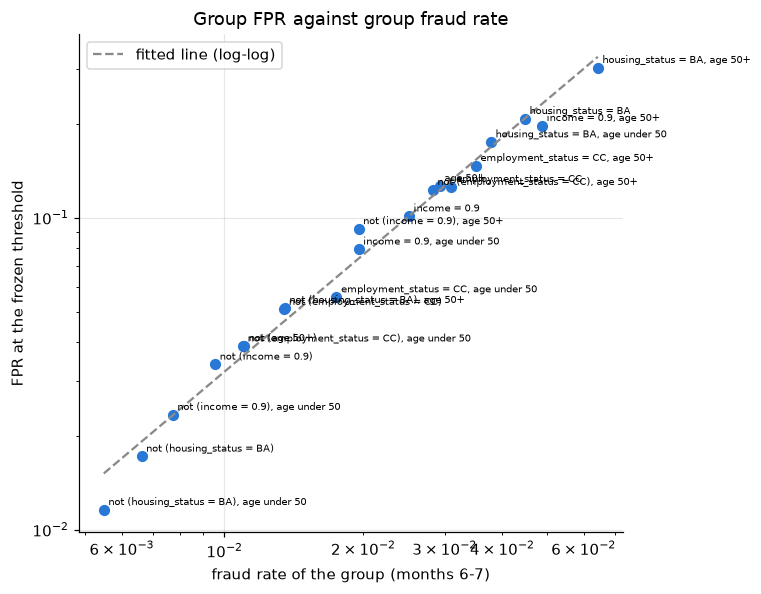

,applications,fraud rate,FPR,FPR per unit of fraud rate
group,,,,
"not (income = 0.9), age 50+",22494,0.0195,0.0922,4.7236
"housing_status = BA, age 50+",10471,0.0644,0.3030,4.7068
housing_status = BA,39900,0.0448,0.2078,4.6430
"housing_status = BA, age under 50",29429,0.0378,0.1749,4.6290
"not (employment_status = CC), age 50+",28755,0.0283,0.1231,4.3546
age 50+,33779,0.0293,0.1266,4.3254
"employment_status = CC, age 50+",5024,0.0350,0.1469,4.1947
"income = 0.9, age under 50",47932,0.0195,0.0793,4.0603
employment_status = CC,6511,0.0310,0.1258,4.0555


In [38]:
points = {}
for name in GROUP_NAMES:
    points[name] = group_masks[name]
    points[f'not ({name})'] = ~group_masks[name]
for name in SECOND_TIER:
    for age_label, age_mask in [('50+', old_test), ('under 50', ~old_test)]:
        points[f'{name}, age {age_label}'] = group_masks[name] & age_mask
        points[f'not ({name}), age {age_label}'] = ~group_masks[name] & age_mask

rows = []
for label, mask in points.items():
    rows.append({'group': label, 'applications': int(mask.sum()), 'fraud rate': y_test[mask].mean(),
                 'FPR': np.mean([flags_test[s][mask & genuine_test].mean() for s in SEEDS])})
fpr_vs_fraud = pd.DataFrame(rows).set_index('group')
fpr_vs_fraud = fpr_vs_fraud[fpr_vs_fraud['applications'] >= MIN_GROUP_ROWS]
fpr_vs_fraud['FPR per unit of fraud rate'] = fpr_vs_fraud['FPR'] / fpr_vs_fraud['fraud rate']
rho, p_value = stats.spearmanr(fpr_vs_fraud['fraud rate'], fpr_vs_fraud['FPR'])
slope, intercept = np.polyfit(np.log(fpr_vs_fraud['fraud rate']), np.log(fpr_vs_fraud['FPR']), 1)
print(f'{len(fpr_vs_fraud)} groups with at least {MIN_GROUP_ROWS:,} applications: Spearman correlation of fraud rate and FPR {rho:.2f}; '
      f'on log scales FPR is proportional to fraud rate to the power {slope:.2f} (1 would be exactly proportional)')

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(fpr_vs_fraud['fraud rate'], fpr_vs_fraud['FPR'], color=BLUE, s=40)
for label, row in fpr_vs_fraud.iterrows():
    ax.annotate(label, (row['fraud rate'], row['FPR']), fontsize=6.5, xytext=(3, 3), textcoords='offset points')
grid = np.linspace(fpr_vs_fraud['fraud rate'].min(), fpr_vs_fraud['fraud rate'].max(), 50)
ax.plot(grid, np.exp(intercept) * grid ** slope, color=GREY, linestyle='--', label='fitted line (log-log)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('fraud rate of the group (months 6-7)')
ax.set_ylabel('FPR at the frozen threshold')
ax.set_title('Group FPR against group fraud rate')
ax.legend()
plt.tight_layout()
plt.show()
fpr_vs_fraud.sort_values('FPR per unit of fraud rate', ascending=False).round(4)

## **6. The BAF Variants**
BAF comes as Base and five variants, each with bias built in differently. Two separate questions are asked, and they must not be mixed:
- **Does the frozen model behave the same on the variants?** A robustness check of the model that would be deployed. Nothing is refitted.
- **Does bias in the training data carry into a model?** The model's recipe is trained again on each variant.
The first question scores the frozen model on months 6-7 of every dataset at the frozen thresholds. The second trains the same recipe (same features, same hyperparameters, no retuning) on each variant's own months 0-3, tests it on months 6-7, and sets its own threshold on that variant's month 5. Variants IV and V are biased only in months 0-5, which the Base model never sees, so only this experiment shows what that bias does.

**Findings**
- The gap of the frozen model is the same on every dataset (predictive equality 0.31), so it does not depend on the test data.
- A model trained on data where the age groups have similar fraud rates has almost no gap, so **the age gap of the Base model is largely inherited from the age-linked fraud rate in its training data**.
- A bias in the training months carries into the model even when the test data are fair.

### **6.1 The Frozen Model on Every Variant**
Check whether the gap of the frozen model depends on the test data. All fairness measures on months 6-7 of each dataset at the frozen thresholds (which are not refitted either), together with recall at 5% FPR, the main accuracy measure, from the ranking alone.

**Findings**
- **The predictive equality ratio is 0.305-0.309 on every dataset**, with intervals of about +/-0.01.
- This holds even where the fraud rates of the two age groups are almost equal (variants III, IV and V: 1.11% against 1.08%; variant I: 1.56% against 1.38%). There the predictive parity ratio falls to 0.44-0.53 (Base 0.86): the model flags 50+ applicants about 3.3 times as often but with half the precision. On Base the gap is partly a real base-rate difference; on the variants it is purely a learned effect.
- Variants III and IV give identical results because they share their test applications.
- Absolute FPRs are not comparable across datasets: the frozen threshold flags 8.3-8.4% of genuine applications on variants II-V, 4.9% on variant I and 5.3% on Base. Recall at 5% FPR falls from 0.548 on Base to 0.47-0.51 on variants I, III, IV and V.

In [39]:
def recall_at_fpr(y_true, scores_, target_fpr=TARGET_FPR):
    # Copied from notebook 02.
    fpr, tpr, cut_offs = roc_curve(y_true, scores_)
    return tpr[np.searchsorted(fpr, target_fpr, side='right') - 1]


def dataset_summary(part, thresholds_by_seed, n_resamples=N_BOOTSTRAP):
    y = part['y_true'].to_numpy()
    old = (part['customer_age'] >= AGE_CUT).to_numpy()
    flags = {seed: part[f'score_seed{seed}'].to_numpy() >= thresholds_by_seed[seed] for seed in SEEDS}
    rates_d, gaps_d = fairness_summary(y, old, flags, n_resamples=n_resamples)
    row = {'applications': len(y), 'share 50+': old.mean(), 'fraud rate': y.mean(),
           'fraud rate 50+': rates_d.loc[('50+', 'fraud rate'), 'estimate'], 'fraud rate under 50': rates_d.loc[('under 50', 'fraud rate'), 'estimate'],
           'recall@5%FPR': np.mean([recall_at_fpr(y, part[f'score_seed{seed}'].to_numpy()) for seed in SEEDS]),
           'overall FPR': np.mean([flags[s][y == 0].mean() for s in SEEDS]),
           'FPR 50+': rates_d.loc[('50+', 'FPR'), 'estimate'], 'FPR under 50': rates_d.loc[('under 50', 'FPR'), 'estimate'],
           'TPR 50+': rates_d.loc[('50+', 'TPR (recall)'), 'estimate'], 'TPR under 50': rates_d.loc[('under 50', 'TPR (recall)'), 'estimate']}
    for measure in ['predictive equality ratio', 'equal opportunity ratio', 'demographic parity ratio', 'predictive parity ratio', 'equalised odds difference']:
        row[measure] = gaps_d.loc[measure, 'estimate']
        if measure in ('predictive equality ratio', 'equal opportunity ratio'):
            row[measure + ' CI low'], row[measure + ' CI high'] = gaps_d.loc[measure, 'CI low'], gaps_d.loc[measure, 'CI high']
    return row


start = time.time()
variant_frozen = pd.DataFrame({dataset: dataset_summary(scores[(scores['dataset'] == dataset) & scores['month'].isin(TEST_MONTHS)], thresholds)
                               for dataset in DATASETS}).T
print(f'{len(DATASETS)} datasets in {(time.time() - start) / 60:.1f} min')
variant_frozen.round(4)

6 datasets in 0.5 min


,applications,share 50+,fraud rate,fraud rate 50+,fraud rate under 50,recall@5%FPR,overall FPR,FPR 50+,FPR under 50,TPR 50+,TPR under 50,predictive equality ratio,predictive equality ratio CI low,predictive equality ratio CI high,equal opportunity ratio,equal opportunity ratio CI low,equal opportunity ratio CI high,demographic parity ratio,predictive parity ratio,equalised odds difference
base,205011.0,0.1648,0.014,0.0293,0.0110,0.5482,0.0531,0.1266,0.0389,0.6997,0.4891,0.3072,0.2964,0.3177,0.6991,0.6611,0.7442,0.3059,0.8612,0.2105
variant_i,205010.0,0.1095,0.014,0.0156,0.0138,0.5136,0.0491,0.1281,0.0394,0.6815,0.4854,0.3076,0.2959,0.3205,0.7123,0.6621,0.7683,0.3333,0.5284,0.1961
variant_ii,205010.0,0.5053,0.014,0.0232,0.0046,0.5505,0.0836,0.1280,0.0391,0.7010,0.4532,0.3054,0.2954,0.3159,0.6465,0.5822,0.7126,0.2902,0.4441,0.2478
variant_iii,241672.0,0.5053,0.011,0.0111,0.0108,0.4676,0.0842,0.1282,0.0392,0.6904,0.4725,0.3058,0.2957,0.3149,0.6845,0.6386,0.7325,0.3264,0.4906,0.2178
variant_iv,241672.0,0.5053,0.011,0.0111,0.0108,0.4676,0.0842,0.1282,0.0392,0.6904,0.4725,0.3058,0.2965,0.3153,0.6845,0.6391,0.7302,0.3264,0.4906,0.2178
variant_v,241672.0,0.5054,0.011,0.0111,0.0109,0.4835,0.0832,0.1264,0.0390,0.7087,0.4737,0.3089,0.2997,0.3187,0.6684,0.6273,0.7125,0.3295,0.5003,0.2350


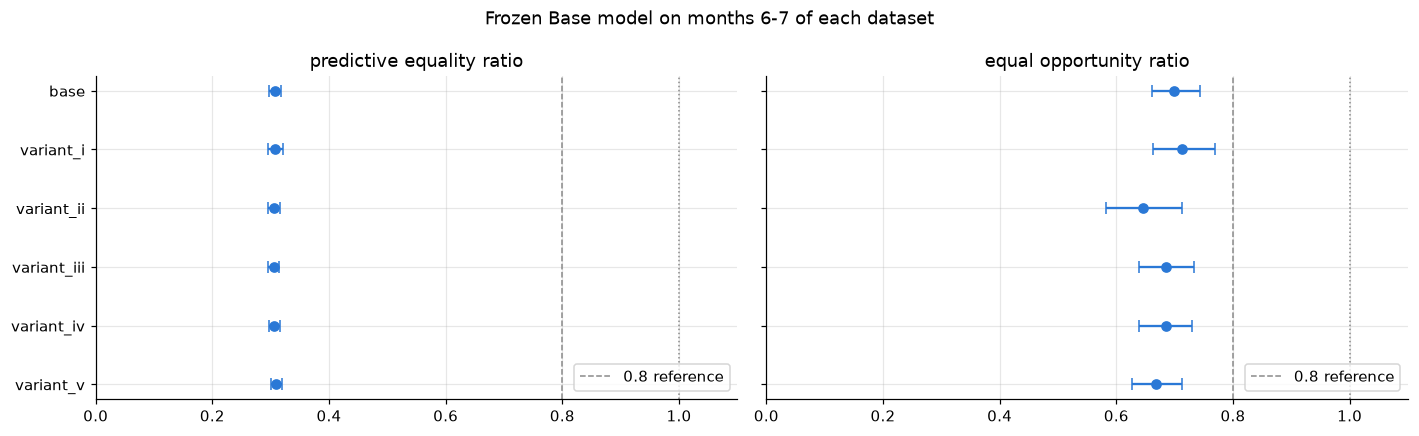

In [40]:
def forest(table, col_pairs, title, datasets=DATASETS):
    fig, axes = plt.subplots(1, len(col_pairs), figsize=(6.5 * len(col_pairs), 4), sharey=True)
    axes = np.atleast_1d(axes)
    positions = np.arange(len(datasets))[::-1]
    for ax, (col, label) in zip(axes, col_pairs):
        est = table.loc[datasets, col].astype(float)
        low, high = table.loc[datasets, col + ' CI low'].astype(float), table.loc[datasets, col + ' CI high'].astype(float)
        ax.errorbar(est, positions, xerr=[est - low, high - est], fmt='o', color=BLUE, capsize=4)
        ax.axvline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1, label='0.8 reference')
        ax.axvline(1, color=GREY, linestyle=':', linewidth=1)
        ax.set_xlim(0, 1.1)
        ax.set_title(label)
        ax.legend(loc='lower right')
    axes[0].set_yticks(positions)
    axes[0].set_yticklabels(datasets)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


forest(variant_frozen, [('predictive equality ratio', 'predictive equality ratio'), ('equal opportunity ratio', 'equal opportunity ratio')],
       'Frozen Base model on months 6-7 of each dataset')

### **6.2 Training on Each Variant**
Show whether bias built into a dataset's training data carries into a model trained on it. For Base and every variant, the model of notebook 02 is trained on that dataset's months 0-3 with the frozen hyperparameters and no retuning, using 3 seeds (notebook 04 found a seed standard deviation of recall at 5% FPR of about 0.002, small against the +/-0.018 sampling interval). Each model gets its own threshold (5% of genuine month-5 applications of the same dataset). **Base is trained again the same way as a control**, so that each variant is compared with a model trained by exactly the same code and seeds, and any difference between a variant and the refitted Base is due to the training data. (In the project's environment the refit is identical to the frozen model; on another setup the trees can differ slightly, notebook 05, section 15.2.) The 18 models take about 5 minutes, and their scores are cached.

**Findings**
- The refitted Base reproduces the frozen model (predictive equality 0.31, recall at 5% FPR 0.549 on its 3 seeds against 0.548 on all 5), so the comparison is fair.

| Training data | fraud rate 50+ / under 50 (test) | predictive equality | equal opportunity | recall at 5% FPR |
|---|---|---|---|---|
| Base (control) | 2.9% / 1.1% | 0.31 | 0.70 | 0.549 |
| Variant I | 1.6% / 1.4% | 0.83 | 0.95 | 0.525 |
| Variant II | 2.3% / 0.5% | 0.14 | 0.39 | 0.548 |
| Variant III | 1.1% / 1.1% | 0.93 | 0.96 | 0.496 |
| Variant IV | 1.1% / 1.1% | 0.15 | 0.46 | 0.435 |
| Variant V | 1.1% / 1.1% | 0.91 | 0.99 | 0.513 |

- **Models trained on data where the age groups have similar fraud rates (I, III, V) have almost no age gap** (0.83-0.93), and lose little recall against the frozen model scored on the same variant. The age gap of the Base model is largely inherited from the age-linked fraud rate in its training data.
- **Variant IV is the opposite case.** Its test data are balanced, but its training months carry the bias, and the model trained on them has a gap of 0.15 and the lowest recall at 5% FPR (0.435). A bias in the training months carries into the model even when the test data are fair, and the Base model never saw it.
- The variants are synthetic constructions, so these numbers show what could happen, not what to expect from a real fix. They point to a mitigation that works on the cause: **reweighing the training data so that age and fraud are not linked**.

In [41]:
RETRAIN_SEEDS = [0, 1, 2]
RETRAIN_CACHE = f'{DATA_DIR}/cache/variant_retrained_scores.parquet'
BASE_PARAMS = dict(final_model['params'])


def make_xgboost(seed, params=None):
    # Copied from notebook 02, section 4.1 (make_model for xgboost): the starting settings are overridden by the given ones.
    settings = {'subsample': 0.8, 'colsample_bytree': 0.8, **(params or BASE_PARAMS)}
    return xgb.XGBClassifier(**settings, random_state=seed, tree_method='hist', enable_categorical=True)


def retrain_dataset(dataset):
    df = pd.read_csv(f'{DATA_DIR}/{DATASET_FILES[dataset]}')
    train_part = df[df['month'].isin(TRAIN_MONTHS)]
    X_train = make_features(train_part, **FEATURES)
    y_train = train_part[TARGET].to_numpy()
    score_part = df[df['month'].isin(CALIBRATION_MONTHS + TEST_MONTHS)]
    X_score = make_features(score_part, **FEATURES)
    table = pd.DataFrame({'dataset': dataset, 'row_id': score_part.index.to_numpy(), 'month': score_part['month'].to_numpy(),
                          'y_true': score_part[TARGET].to_numpy(), 'customer_age': score_part['customer_age'].to_numpy()})
    for seed in RETRAIN_SEEDS:
        model = make_xgboost(seed).fit(X_train, y_train)
        table[f'score_seed{seed}'] = model.predict_proba(X_score)[:, 1].astype(np.float32)
    return table


if os.path.exists(RETRAIN_CACHE):
    retrained = pd.read_parquet(RETRAIN_CACHE)
    print(f'Loaded the retrained scores from {RETRAIN_CACHE}')
else:
    start = time.time()
    parts = []
    for dataset in DATASETS:
        parts.append(retrain_dataset(dataset))
        print(f'{dataset:12s} trained on its months 0-3 ({len(RETRAIN_SEEDS)} seeds), {(time.time() - start) / 60:.1f} min so far')
    retrained = pd.concat(parts, ignore_index=True)
    try:
        retrained.to_parquet(RETRAIN_CACHE, index=False)
        print(f'saved to {RETRAIN_CACHE}')
    except Exception as error:
        print(f'the scores could not be saved ({type(error).__name__}); they stay in memory')
retrained['dataset'] = pd.Categorical(retrained['dataset'], categories=DATASETS)

base         trained on its months 0-3 (3 seeds), 0.2 min so far


variant_i    trained on its months 0-3 (3 seeds), 0.4 min so far


variant_ii   trained on its months 0-3 (3 seeds), 0.6 min so far


variant_iii  trained on its months 0-3 (3 seeds), 0.8 min so far


variant_iv   trained on its months 0-3 (3 seeds), 1.0 min so far


variant_v    trained on its months 0-3 (3 seeds), 1.3 min so far


saved to ../data/cache/variant_retrained_scores.parquet


In [42]:
SEEDS_FROZEN = SEEDS
SEEDS = RETRAIN_SEEDS   # the helper functions below average over SEEDS; the retrained models have 3 seeds
rows = {}
retrained_thresholds = {}
for dataset in DATASETS:
    part = retrained[retrained['dataset'] == dataset]
    month5_part = part[part['month'].isin(CALIBRATION_MONTHS)]
    retrained_thresholds[dataset] = {seed: threshold_at_fpr(month5_part['y_true'].to_numpy(), month5_part[f'score_seed{seed}'].to_numpy(), TARGET_FPR)
                                     for seed in SEEDS}
    rows[dataset] = dataset_summary(part[part['month'].isin(TEST_MONTHS)], retrained_thresholds[dataset])
variant_retrained = pd.DataFrame(rows).T
SEEDS = SEEDS_FROZEN
variant_retrained.round(4)

,applications,share 50+,fraud rate,fraud rate 50+,fraud rate under 50,recall@5%FPR,overall FPR,FPR 50+,FPR under 50,TPR 50+,TPR under 50,predictive equality ratio,predictive equality ratio CI low,predictive equality ratio CI high,equal opportunity ratio,equal opportunity ratio CI low,equal opportunity ratio CI high,demographic parity ratio,predictive parity ratio,equalised odds difference
base,205011.0,0.1648,0.014,0.0293,0.0110,0.5488,0.0530,0.1266,0.0388,0.7010,0.4899,0.3063,0.2955,0.3169,0.6987,0.6605,0.7454,0.3051,0.8629,0.2112
variant_i,205010.0,0.1095,0.014,0.0156,0.0138,0.5250,0.0546,0.0640,0.0534,0.5214,0.5470,0.8338,0.7915,0.8784,0.9531,0.8598,0.9973,0.8460,0.9107,0.0257
variant_ii,205010.0,0.5053,0.014,0.0232,0.0046,0.5483,0.0560,0.0978,0.0140,0.6384,0.2489,0.1437,0.1361,0.1523,0.3899,0.3354,0.4513,0.1372,0.5667,0.3895
variant_iii,241672.0,0.5053,0.011,0.0111,0.0108,0.4956,0.0560,0.0581,0.0539,0.5107,0.5303,0.9263,0.8949,0.9532,0.9630,0.8990,0.9979,0.9340,0.9255,0.0196
variant_iv,241672.0,0.5053,0.011,0.0111,0.0108,0.4351,0.0564,0.0973,0.0147,0.6291,0.2892,0.1514,0.1441,0.1584,0.4598,0.4176,0.5004,0.1715,0.3838,0.3399
variant_v,241672.0,0.5054,0.011,0.0111,0.0109,0.5134,0.0528,0.0553,0.0501,0.5227,0.5287,0.9069,0.8795,0.9396,0.9887,0.9197,0.9984,0.9156,0.9187,0.0060


In [43]:
comparison = pd.DataFrame({
    'recall@5%FPR, frozen Base model': variant_frozen['recall@5%FPR'],
    'recall@5%FPR, trained on the dataset': variant_retrained['recall@5%FPR'],
    'predictive equality, frozen Base model': variant_frozen['predictive equality ratio'],
    'predictive equality, trained on the dataset': variant_retrained['predictive equality ratio'],
    'predictive equality, difference from refitted Base': variant_retrained['predictive equality ratio'] - variant_retrained.loc['base', 'predictive equality ratio'],
    'equal opportunity, frozen Base model': variant_frozen['equal opportunity ratio'],
    'equal opportunity, trained on the dataset': variant_retrained['equal opportunity ratio'],
    'equal opportunity, difference from refitted Base': variant_retrained['equal opportunity ratio'] - variant_retrained.loc['base', 'equal opportunity ratio'],
}).astype(float)
comparison.round(4)

,"recall@5%FPR, frozen Base model","recall@5%FPR, trained on the dataset","predictive equality, frozen Base model","predictive equality, trained on the dataset","predictive equality, difference from refitted Base","equal opportunity, frozen Base model","equal opportunity, trained on the dataset","equal opportunity, difference from refitted Base"
base,0.5482,0.5488,0.3072,0.3063,0.0000,0.6991,0.6987,0.0000
variant_i,0.5136,0.5250,0.3076,0.8338,0.5275,0.7123,0.9531,0.2543
variant_ii,0.5505,0.5483,0.3054,0.1437,-0.1626,0.6465,0.3899,-0.3088
variant_iii,0.4676,0.4956,0.3058,0.9263,0.6200,0.6845,0.9630,0.2643
variant_iv,0.4676,0.4351,0.3058,0.1514,-0.1549,0.6845,0.4598,-0.2390
variant_v,0.4835,0.5134,0.3089,0.9069,0.6006,0.6684,0.9887,0.2900


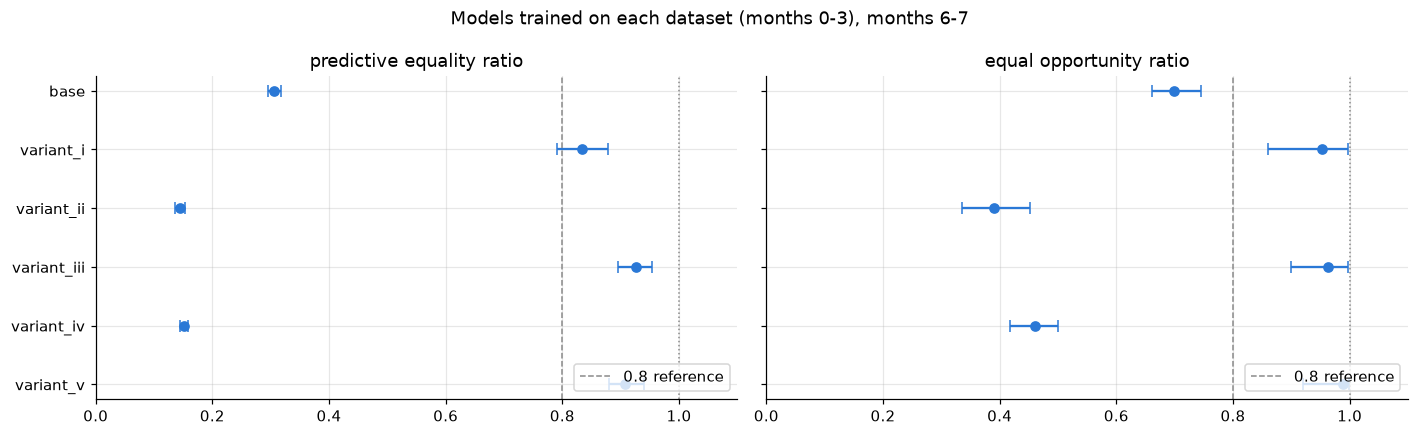

In [44]:
forest(variant_retrained, [('predictive equality ratio', 'predictive equality ratio'), ('equal opportunity ratio', 'equal opportunity ratio')],
       'Models trained on each dataset (months 0-3), months 6-7')

## **7. Mitigations**
The earlier findings point to four kinds of intervention, tested here on Base: the direct use of `customer_age` explains about a quarter of the distance to parity, the rest is spread over many proxies, and a model trained on data where age and fraud are not linked has almost no gap.

| Family | What changes | Needs age at decision time? |
|---|---|---|
| **Drop age** (unawareness) | `customer_age` is removed from the model's features | no |
| **Drop age and proxies** | `customer_age` and the *k* strongest proxies are removed (k = 1, 3, 5, 8, 12) | no |
| **Reweighing** | training rows are weighted so that, in the weighted data, being 50+ and being fraud are unrelated (Kamiran and Calders, 2012) | no: the model still takes `customer_age` as an input; only the training weights change |
| **Group-specific thresholds** | the model is unchanged; each age group gets its own threshold | **yes** (a legal question, so it is reported as a bound, not as a recommendation) |

Every retrained model uses the frozen model's hyperparameters (no retuning) and the same training months 0-3, with 3 seeds, and gets its own 5%-FPR threshold from month 5. **Choices between mitigations are made on month 4**; months 6-7 report the results, and nothing is re-chosen after seeing them. Constrained training (ExponentiatedGradient) is not used: the four families are enough to show the trade-off, and it needs a library and about 50 refits.

**Findings**
- **The refit control is faithful**: in this environment its 3 seeds are the frozen model's seeds 0-2 (predictive equality 0.306 against 0.307 over all 5 seeds, recall 0.562 for both), so every difference below is due to the mitigation.
- **Drop age is small and cheap** (0.31 to 0.41), **dropping proxies is a poor trade**, and **reweighing at full strength** (0.90) and **equal-FPR group thresholds** (0.91) give the same fairness for about 2 points of recall.
- Every age mitigation leaves **housing BA at 0.08-0.10** and income 0.9 at about 0.33.

### **7.1 The Settings and the Weights**
Define each retrained setting and the reweighing weights. Each setting is one row: whether `customer_age` is dropped, how many proxies are dropped, and the reweighing strength. **Reweighing:** each training application gets the weight P(g) x P(y) / P(g, y), where g is the age group and y the label, so that group and label are independent in the weighted data. Fraud among 50+ applicants is over-represented, so it gets a weight below 1, and genuine 50+ applications get a weight slightly above 1. The weights compose with the model's own `scale_pos_weight`, so the model still sees fraud as rare; only the link with age is removed. Full strength (exponent 1) is the definition; a half-strength version (weight to the power 0.5) is tested next to it to see whether the effect grows steadily with the strength. Strength 1 is the definition of Kamiran and Calders, and 0.5 tests whether the effect grows steadily with strength. Both are reported and none is tuned.

**Findings**
- At full strength both age groups have the same weighted fraud rate (0.97%, from 2.11% and 0.69%); at half strength the rates lie about half-way (1.43% and 0.82%).
- The weights are moderate: 0.46 to 1.39 (fraud among 50+ gets 0.46, fraud among others 1.39, genuine applications about 1.0), so the fit is stable. 

In [45]:
MITIGATIONS = {   # key -> label, drop customer_age, number of proxies dropped, reweighing strength (0 = none)
    'control':            dict(label='refit, no change',           drop_age=False, k=0, strength=0.0),
    'drop_age':           dict(label='drop age',                   drop_age=True,  k=0, strength=0.0),
    **{f'proxies_{k}': dict(label=f'drop age + {k} proxies', drop_age=True, k=k, strength=0.0) for k in PROXY_GRID if k > 0},
    'reweigh_0.5':        dict(label='reweigh, half strength',     drop_age=False, k=0, strength=0.5),
    'reweigh_1':          dict(label='reweigh, full strength',     drop_age=False, k=0, strength=1.0),
    'reweigh_1_drop_age': dict(label='reweigh + drop age',         drop_age=True,  k=0, strength=1.0),
}
MIT_SEEDS = RETRAIN_SEEDS


def reweighing_weights(y, is_old, strength=1.0):
    """Kamiran and Calders (2012): w(g, y) = P(g) P(y) / P(g, y), raised to the given strength."""
    y, is_old = np.asarray(y), np.asarray(is_old)
    w = np.ones(len(y))
    for g in (True, False):
        for label in (0, 1):
            cell = (is_old == g) & (y == label)
            w[cell] = ((is_old == g).mean() * (y == label).mean() / cell.mean()) ** strength
    return w


def columns_to_drop(X, cfg):
    names = (['customer_age'] if cfg['drop_age'] else []) + (model_features_of(PROXY_ORDER[:cfg['k']]) if cfg['k'] else [])
    return [c for c in X.columns if group_of.get(c, c) in names]


def fit_and_score(cfg, X_train, y_train, old_train, X_score, seed):
    drop = columns_to_drop(X_train, cfg)
    weights = reweighing_weights(y_train, old_train, cfg['strength']) if cfg['strength'] else None
    model = make_xgboost(seed).fit(X_train.drop(columns=drop), y_train, sample_weight=weights)
    return model.predict_proba(X_score.drop(columns=drop))[:, 1].astype(np.float32)


# The weights on the training months, and what they do to the weighted fraud rate of each group
y_train_all = train_raw[TARGET].to_numpy()
old_train_all = (train_raw['customer_age'] >= AGE_CUT).to_numpy()
rows = []
for strength in (0.5, 1.0):
    w = reweighing_weights(y_train_all, old_train_all, strength)
    for label, mask in (('50+', old_train_all), ('under 50', ~old_train_all)):
        rows.append({'strength': strength, 'group': label, 'weight of a genuine application': w[mask & (y_train_all == 0)][0],
                     'weight of a fraud application': w[mask & (y_train_all == 1)][0],
                     'fraud rate before': y_train_all[mask].mean(), 'fraud rate after (weighted)': np.average(y_train_all[mask], weights=w[mask])})
pd.DataFrame(rows).set_index(['strength', 'group']).round(4)

weight of a genuine application  \
strength group                                       
0.5      50+                                1.0058   
         under 50                           0.9986   
1.0      50+                                1.0117   
         under 50                           0.9973   

                   weight of a fraud application  fraud rate before  \
strength group                                                        
0.5      50+                              0.6763             0.0211   
         under 50                         1.1787             0.0069   
1.0      50+                              0.4573             0.0211   
         under 50                         1.3893             0.0069   

                   fraud rate after (weighted)  
strength group                                  
0.5      50+                            0.0143  
         under 50                       0.0082  
1.0      50+                            0.0097  
         under 50                       0.0097

**What to look for.** At full strength the weighted fraud rate must be the same in both groups (that is the definition); at half strength it should lie about half-way. The weights should be moderate (a weight of 10 or more on a few rows would make the fit unstable).

### **7.2 Training the Mitigated Models**
Train every setting that needs a retrained model. Ten settings (the refit control, drop age, drop age plus 1, 3, 5, 8 or 12 proxies, reweighing at half and full strength, and reweighing with age dropped) are trained for 3 seeds on months 0-3 and score months 4-7. Scores are cached, so the 30 models (about 0.7 minutes per setting) are trained only once. Three seeds are used instead of five: a seed standard deviation of recall at 5% FPR of about 0.002 (notebook 04), small against the +/-0.018 sampling interval, and 3 seeds keep the 30 + 30 models of this section and of section 9 to about 20 minutes.

**Findings.** Dropping age removes 1 column; dropping 12 proxies removes 16 columns (a feature and its missing flag go together). All 30 models trained without problems on 452,025 scored applications.

In [46]:
MIT_CACHE = f'{DATA_DIR}/cache/mitigation_scores.parquet'
MIT_MONTHS = VALIDATION_MONTHS + CALIBRATION_MONTHS + TEST_MONTHS
mit = base[base['month'].isin(MIT_MONTHS)].reset_index(drop=True)     # months 4-7, with the frozen scores and the group columns
y_mit = mit['y_true'].to_numpy()
old_mit = mit['age_50_plus'].to_numpy()
is_m4, is_m5, is_test = (mit['month'] == 4).to_numpy(), (mit['month'] == 5).to_numpy(), mit['month'].isin(TEST_MONTHS).to_numpy()


def column_name(key, seed):
    return f'{key}__seed{seed}'


cached = None
if os.path.exists(MIT_CACHE):
    cached = pd.read_parquet(MIT_CACHE)
    if len(cached) != len(mit) or not (cached['row_id'].to_numpy() == mit['row_id'].to_numpy()).all():
        cached = None
        print('the saved scores are for other rows: training again')
if cached is None:
    cached = mit[['row_id', 'month']].copy()

if any(column_name(key, s) not in cached for key in MITIGATIONS for s in MIT_SEEDS):
    X_train_mit = make_features(base_raw[base_raw['month'].isin(TRAIN_MONTHS)], **FEATURES)
    X_score_mit = make_features(base_raw.loc[mit['row_id'].to_numpy()], **FEATURES)
    for key, cfg in MITIGATIONS.items():
        missing = [s for s in MIT_SEEDS if column_name(key, s) not in cached]
        if not missing:
            continue
        start = time.time()
        for seed in missing:
            cached[column_name(key, seed)] = fit_and_score(cfg, X_train_mit, y_train_all, old_train_all, X_score_mit, seed)
        print(f"{cfg['label']:28s} {len(missing)} seeds trained, {len(columns_to_drop(X_train_mit, cfg))} columns dropped, {(time.time() - start) / 60:.1f} min")
        try:
            cached.to_parquet(MIT_CACHE, index=False)
        except Exception as error:
            print(f'  (the scores could not be saved: {type(error).__name__})')
else:
    print(f'Loaded the saved scores from {MIT_CACHE}')

for key in MITIGATIONS:
    for seed in MIT_SEEDS:
        mit[column_name(key, seed)] = cached[column_name(key, seed)].to_numpy()
print(f'{len(MITIGATIONS)} settings x {len(MIT_SEEDS)} seeds; months {MIT_MONTHS}: {len(mit):,} applications')

refit, no change             3 seeds trained, 0 columns dropped, 0.2 min


drop age                     3 seeds trained, 1 columns dropped, 0.2 min


drop age + 1 proxies         3 seeds trained, 2 columns dropped, 0.2 min


drop age + 3 proxies         3 seeds trained, 4 columns dropped, 0.2 min


drop age + 5 proxies         3 seeds trained, 6 columns dropped, 0.2 min


drop age + 8 proxies         3 seeds trained, 11 columns dropped, 0.2 min


drop age + 12 proxies        3 seeds trained, 16 columns dropped, 0.2 min


reweigh, half strength       3 seeds trained, 0 columns dropped, 0.2 min


reweigh, full strength       3 seeds trained, 0 columns dropped, 0.2 min


reweigh + drop age           3 seeds trained, 1 columns dropped, 0.2 min


10 settings x 3 seeds; months [4, 5, 6, 7]: 452,025 applications


### **7.3 Thresholds, Flags and the Evaluation Function**
Make every candidate comparable with one rule and one evaluation. Every retrained model gets its own threshold per seed: the one that flags 5% of the genuine month-5 applications (the recipe of notebook 02). The frozen model keeps its frozen thresholds. One evaluation function takes the flags of any number of candidates and returns each measure with its Poisson-bootstrap resamples. **All candidates use the same resampling weights**, so a difference between two candidates comes with an interval that accounts for the pairing, which is much narrower than the two intervals on their own. The measures are recall, FPR by group, predictive equality, equal opportunity, false alarms per 1,000 applications, and the cost per 10,000 applications at each cost ratio (cost = R x missed fraud + false alarms).

**Findings.** On month 5 every setting flags about 5.0% of genuine applications (0.0498-0.0499 in the three printed), as intended.

In [47]:
def _metric_frame(c, t, n):
    """Measures from flagged counts c and totals t (one row per resample), each with columns:
    genuine, fraud, genuine 50+, genuine under 50, fraud 50+, fraud under 50, all 50+, all under 50."""
    d = {}
    d['recall'] = c[:, 1] / t[:, 1]
    d['FPR'] = c[:, 0] / t[:, 0]
    d['FPR 50+'], d['FPR under 50'] = c[:, 2] / t[:, 2], c[:, 3] / t[:, 3]
    d['TPR 50+'], d['TPR under 50'] = c[:, 4] / t[:, 4], c[:, 5] / t[:, 5]
    d['predictive equality'] = np.minimum(d['FPR 50+'], d['FPR under 50']) / np.maximum(d['FPR 50+'], d['FPR under 50'])
    d['equal opportunity'] = np.minimum(d['TPR 50+'], d['TPR under 50']) / np.maximum(d['TPR 50+'], d['TPR under 50'])
    d['FPR gap'] = np.abs(d['FPR 50+'] - d['FPR under 50'])
    missed = t[:, 1] - c[:, 1]
    d['false alarms per 1,000'] = 1000 * c[:, 0] / n
    d['false alarms per 1,000, 50+'] = 1000 * c[:, 2] / t[:, 6]
    d['false alarms per 1,000, under 50'] = 1000 * c[:, 3] / t[:, 7]
    for ratio in COST_RATIOS:
        d[f'cost per 10,000 (R={ratio})'] = 10_000 * (ratio * missed + c[:, 0]) / n
    return pd.DataFrame(d)


def evaluate_flags(y, is_old, candidates, n_resamples=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED, batch=50):
    """candidates: {name: {seed: flags}}. Returns {name: DataFrame}; row 0 is the real data, the others are Poisson resamples.
    The resampling weights are the same for every candidate (and for every call with the same number of applications)."""
    y, is_old = np.asarray(y), np.asarray(is_old)
    fraud = y == 1
    masks = np.column_stack([~fraud, fraud, ~fraud & is_old, ~fraud & ~is_old, fraud & is_old, fraud & ~is_old, is_old, ~is_old]).astype(np.float32)
    rng = np.random.default_rng(rng_seed)
    parts = {name: [] for name in candidates}

    def add(W):
        totals, n = W @ masks, W.sum(axis=1)
        for name, flags_by_seed in candidates.items():
            counts = np.mean([W @ (masks * np.asarray(f)[:, None].astype(np.float32)) for f in flags_by_seed.values()], axis=0)
            parts[name].append(_metric_frame(counts, totals, n))

    add(np.ones((1, len(y)), dtype=np.float32))
    for start in range(0, n_resamples, batch):
        add(rng.poisson(1.0, size=(min(batch, n_resamples - start), len(y))).astype(np.float32))
    return {name: pd.concat(p, ignore_index=True) for name, p in parts.items()}


def with_interval(results, names, column):
    """Estimate and 95% interval of one measure for several candidates."""
    return pd.DataFrame({name: {'estimate': results[name].loc[0, column], 'CI low': results[name].loc[1:, column].quantile(0.025),
                                'CI high': results[name].loc[1:, column].quantile(0.975)} for name in names}).T


def paired_difference(results, name, reference, column):
    """name minus reference, with the interval of the paired resamples."""
    diff = results[name][column] - results[reference][column]
    return {'difference': diff.iloc[0], 'CI low': diff.iloc[1:].quantile(0.025), 'CI high': diff.iloc[1:].quantile(0.975)}


def second_tier_equality(flags_by_seed, rows):
    """Predictive equality ratio (point estimate) of each second-tier group, on the given rows of `mit`."""
    out = {}
    genuine = y_mit[rows] == 0
    for name in SECOND_TIER:
        g = mit.loc[rows, name].to_numpy()
        fpr_in = np.mean([f[g & genuine].mean() for f in flags_by_seed.values()])
        fpr_out = np.mean([f[~g & genuine].mean() for f in flags_by_seed.values()])
        out[f'PE {name}'] = min(fpr_in, fpr_out) / max(fpr_in, fpr_out)
    return out


# Flags of the frozen model and of every retrained setting, on month 4 (for choosing) and the test months (for reporting)
retrained_cuts = {key: {s: threshold_at_fpr(y_mit[is_m5], mit.loc[is_m5, column_name(key, s)].to_numpy(), TARGET_FPR) for s in MIT_SEEDS} for key in MITIGATIONS}
LABELS = {'frozen': 'frozen model (shared threshold)', **{key: cfg['label'] for key, cfg in MITIGATIONS.items()}}
FAMILY = {'frozen': 'frozen', **{key: 'retrained' for key in MITIGATIONS}}
flags_at = {'month 4': {}, 'test': {}}
for where, rows in (('month 4', is_m4), ('test', is_test)):
    flags_at[where]['frozen'] = {s: mit.loc[rows, f'score_seed{s}'].to_numpy() >= thresholds[s] for s in SEEDS}
    for key in MITIGATIONS:
        flags_at[where][key] = {s: mit.loc[rows, column_name(key, s)].to_numpy() >= retrained_cuts[key][s] for s in MIT_SEEDS}
print('thresholds picked on month 5 for', len(MITIGATIONS), 'settings;',
      'overall FPR of each setting on month 5 (should be about 5%):',
      {key: round(float(np.mean([(mit.loc[is_m5, column_name(key, s)].to_numpy()[y_mit[is_m5] == 0] >= retrained_cuts[key][s]).mean() for s in MIT_SEEDS])), 4)
       for key in list(MITIGATIONS)[:3]})

thresholds picked on month 5 for 10 settings; overall FPR of each setting on month 5 (should be about 5%): {'control': 0.0499, 'drop_age': 0.0498, 'proxies_1': 0.0499}


### **7.4 Group-Specific Thresholds on the Frozen Model**
Show what a different cut-off for each age group can do on its own, without changing the model. The model is unchanged and only month 5 sets the cut-offs. Two rules, each at several strengths because there is no standard value:
- **Equal FPR.** The FPR of the 50+ group is moved from where the shared threshold puts it (about 12%) towards 5% in steps of a quarter of the way (25%, 50%, 75%, 100%), and the under-50 cut-off is set so the **overall FPR stays at 5%** (the same number of false alarms, redistributed).
- **Equal recall.** Each group's cut-off is set so that its recall equals the overall recall of the frozen threshold (the overall FPR is then free).

These use age at decision time, which may be unlawful as different treatment by age, so the numbers are a **bound** on what thresholds alone can do, not a proposal. Their intervals do not include the uncertainty of the cut-offs themselves, which were estimated on one month.

**Findings.** For seed 0 the shared cut-off is 0.475 in raw score. At equal FPR the cut-off of the 50+ group rises to 0.667 and that of the others falls to 0.411; the equal-recall rule gives 0.663 and 0.367.

In [48]:
def threshold_at_recall(y_true, scores_, target):
    """The highest cut-off whose recall reaches the target."""
    fpr, tpr, cut_offs = roc_curve(y_true, scores_)
    return cut_offs[np.searchsorted(tpr, target, side='left')]


def group_cuts(y5, old5, s5, shared_cut, rule, level):
    """(cut-off for 50+, cut-off for under 50) of one seed, set on month 5. rule: 'fpr' (level = how far to move towards equal FPR) or 'recall'."""
    genuine = y5 == 0
    if rule == 'fpr':
        if level == 0:
            return shared_cut, shared_cut
        f_shared = (s5[genuine & old5] >= shared_cut).mean()
        f_old = f_shared + level * (TARGET_FPR - f_shared)
        n_old, n_young = (genuine & old5).sum(), (genuine & ~old5).sum()
        f_young = (TARGET_FPR * (n_old + n_young) - f_old * n_old) / n_young          # keeps the overall FPR at 5%
        return threshold_at_fpr(y5[old5], s5[old5], f_old), threshold_at_fpr(y5[~old5], s5[~old5], f_young)
    target = (s5[y5 == 1] >= shared_cut).mean()
    return threshold_at_recall(y5[old5], s5[old5], target), threshold_at_recall(y5[~old5], s5[~old5], target)


GROUP_RULES = {'group_25': ('fpr', 0.25), 'group_50': ('fpr', 0.50), 'group_75': ('fpr', 0.75), 'group_equal_fpr': ('fpr', 1.0), 'group_equal_recall': ('recall', None)}
GROUP_LABELS = {'group_25': 'group thresholds, FPR gap closed 25%', 'group_50': 'group thresholds, FPR gap closed 50%',
                'group_75': 'group thresholds, FPR gap closed 75%', 'group_equal_fpr': 'group thresholds, equal FPR',
                'group_equal_recall': 'group thresholds, equal recall'}
LABELS.update(GROUP_LABELS)
FAMILY.update({key: 'group thresholds' for key in GROUP_RULES})
group_cut_table = {key: {s: group_cuts(y_mit[is_m5], old_mit[is_m5], mit.loc[is_m5, f'score_seed{s}'].to_numpy(), thresholds[s], rule, level)
                         for s in SEEDS} for key, (rule, level) in GROUP_RULES.items()}
for where, rows in (('month 4', is_m4), ('test', is_test)):
    for key in GROUP_RULES:
        flags_at[where][key] = {s: np.where(old_mit[rows], mit.loc[rows, f'score_seed{s}'].to_numpy() >= group_cut_table[key][s][0],
                                            mit.loc[rows, f'score_seed{s}'].to_numpy() >= group_cut_table[key][s][1]) for s in SEEDS}
print('cut-offs of seed 0 (50+, under 50) in raw score:', {key: tuple(round(float(c), 4) for c in group_cut_table[key][0]) for key in GROUP_RULES},
      '; shared:', round(float(thresholds[0]), 4))

cut-offs of seed 0 (50+, under 50) in raw score: {'group_25': (0.5243, 0.4582), 'group_50': (0.5622, 0.4393), 'group_75': (0.6071, 0.4251), 'group_equal_fpr': (0.6673, 0.4113), 'group_equal_recall': (0.6629, 0.3673)} ; shared: 0.4749


### **7.5 Every Candidate on Month 4 and on the Test Months**
Put all 16 candidates side by side: the frozen model, the 9 retrained settings (plus the control) and the 5 group-threshold rules. Each is evaluated on **month 4**, where choices are made, and on **test months 6-7**, which carry the results to report, with 95% intervals from 1,000 paired resamples. The last columns repeat predictive equality for the second-tier groups, so that a change in them is visible.

**Findings (test months)**
- The frozen model has recall 0.562 (0.544-0.579), predictive equality 0.307 (0.296-0.318) and equal opportunity 0.699.
- The candidates that reach a predictive equality near 0.9 are full-strength reweighing (0.900, recall 0.538), equal-FPR thresholds (0.912, 0.538) and equal-recall thresholds (0.879, 0.564).
- Month 4 shows the same ordering of the candidates as the test months, with somewhat lower predictive equality (for example 0.847 for reweighing).
- Every age mitigation leaves housing BA at 0.08-0.10.

In [49]:
CANDIDATES = ['frozen'] + list(MITIGATIONS) + list(GROUP_RULES)
start = time.time()
results_m4 = evaluate_flags(y_mit[is_m4], old_mit[is_m4], {name: flags_at['month 4'][name] for name in CANDIDATES}, n_resamples=0)
results_test = evaluate_flags(y_mit[is_test], old_mit[is_test], {name: flags_at['test'][name] for name in CANDIDATES})
print(f'{len(CANDIDATES)} candidates evaluated in {(time.time() - start) / 60:.1f} min')

SUMMARY_COLUMNS = ['recall', 'FPR', 'FPR 50+', 'FPR under 50', 'predictive equality', 'equal opportunity', 'false alarms per 1,000', 'cost per 10,000 (R=10)']


def overview(results, rows):
    table = pd.DataFrame({name: results[name].loc[0, SUMMARY_COLUMNS] for name in CANDIDATES}).T
    second = pd.DataFrame({name: second_tier_equality(flags_at['month 4' if rows is is_m4 else 'test'][name], rows) for name in CANDIDATES}).T
    table = pd.concat([table, second], axis=1)
    table.index = [LABELS[n] for n in CANDIDATES]
    return table


print('Month 4 (used for choosing)')
overview_m4 = overview(results_m4, is_m4)
display(overview_m4.round(4))
print('Test months 6-7 (reported)')
overview_test = overview(results_test, is_test)
overview_test.round(4)

16 candidates evaluated in 0.1 min
Month 4 (used for choosing)


,recall,FPR,FPR 50+,FPR under 50,predictive equality,equal opportunity,"false alarms per 1,000","cost per 10,000 (R=10)",PE income = 0.9,PE employment_status = CC,PE housing_status = BA
frozen model (shared threshold),0.6720,0.0772,0.1759,0.0550,0.3126,0.7664,76.345200,1136.383911,0.3606,0.4333,0.0872
"refit, no change",0.6701,0.0772,0.1764,0.0549,0.3110,0.7652,76.332703,1138.451416,0.3606,0.4321,0.0873
drop age,0.6605,0.0771,0.1507,0.0605,0.4016,0.8440,76.241302,1148.501709,0.3613,0.4469,0.0838
drop age + 1 proxies,0.6534,0.0785,0.1424,0.0641,0.4503,0.8800,77.624901,1170.429565,0.3581,0.4533,0.0811
drop age + 3 proxies,0.5916,0.0714,0.1170,0.0612,0.5232,0.9183,70.626198,1170.664551,0.3229,0.7590,0.2554
drop age + 5 proxies,0.5094,0.0652,0.1113,0.0548,0.4924,0.9515,64.426399,1202.120728,0.2746,0.6347,0.2366
drop age + 8 proxies,0.4851,0.0794,0.1213,0.0700,0.5768,0.9637,78.517700,1370.704834,0.2421,0.6874,0.3345
drop age + 12 proxies,0.3212,0.0690,0.0884,0.0646,0.7309,0.9840,68.219398,1454.109131,0.9402,0.5757,0.6010
"reweigh, half strength",0.6609,0.0765,0.1319,0.0641,0.4856,0.8875,75.659203,1142.158203,0.3551,0.5879,0.0900
"reweigh, full strength",0.6270,0.0757,0.0865,0.0733,0.8470,0.8893,74.876099,1172.961914,0.3605,0.8220,0.0980


Test months 6-7 (reported)


,recall,FPR,FPR 50+,FPR under 50,predictive equality,equal opportunity,"false alarms per 1,000","cost per 10,000 (R=10)",PE income = 0.9,PE employment_status = CC,PE housing_status = BA
frozen model (shared threshold),0.5615,0.0531,0.1266,0.0389,0.3072,0.6991,52.386501,1139.441284,0.3347,0.4037,0.0827
"refit, no change",0.5624,0.0530,0.1266,0.0388,0.3063,0.6987,52.299599,1137.272339,0.3346,0.4007,0.0832
drop age,0.5621,0.0547,0.1072,0.0445,0.4150,0.7734,53.896301,1153.726685,0.3385,0.4325,0.0804
drop age + 1 proxies,0.5457,0.0523,0.0953,0.0440,0.4615,0.8071,51.592400,1153.612915,0.3269,0.4308,0.0763
drop age + 3 proxies,0.4788,0.0484,0.0805,0.0422,0.5249,0.8225,47.751900,1209.187134,0.3026,0.7272,0.2604
drop age + 5 proxies,0.4355,0.0505,0.0847,0.0439,0.5179,0.7784,49.787601,1290.353516,0.2639,0.6577,0.2565
drop age + 8 proxies,0.3963,0.0550,0.0792,0.0503,0.6352,0.7408,54.200298,1389.437622,0.2264,0.6920,0.3526
drop age + 12 proxies,0.2447,0.0467,0.0558,0.0449,0.8054,0.8389,46.030102,1520.568848,0.9867,0.5904,0.6406
"reweigh, half strength",0.5551,0.0527,0.0911,0.0452,0.4963,0.8184,51.917500,1143.694702,0.3319,0.5676,0.0839
"reweigh, full strength",0.5382,0.0532,0.0581,0.0523,0.9000,0.9774,52.455700,1172.815063,0.3332,0.8369,0.0901


In [50]:
rows = []
for name in CANDIDATES:
    row = {'candidate': LABELS[name]}
    for column in ['recall', 'predictive equality', 'equal opportunity']:
        iv = with_interval(results_test, [name], column).iloc[0]
        row[column] = f"{iv['estimate']:.3f} ({iv['CI low']:.3f}-{iv['CI high']:.3f})"
    rows.append(row)
pd.DataFrame(rows).set_index('candidate')

,recall,predictive equality,equal opportunity
candidate,,,
frozen model (shared threshold),0.562 (0.544-0.579),0.307 (0.296-0.318),0.699 (0.661-0.744)
"refit, no change",0.562 (0.544-0.580),0.306 (0.295-0.317),0.699 (0.661-0.745)
drop age,0.562 (0.544-0.579),0.415 (0.400-0.431),0.773 (0.729-0.824)
drop age + 1 proxies,0.546 (0.527-0.563),0.462 (0.443-0.480),0.807 (0.759-0.863)
drop age + 3 proxies,0.479 (0.461-0.497),0.525 (0.503-0.546),0.822 (0.764-0.886)
drop age + 5 proxies,0.435 (0.419-0.453),0.518 (0.497-0.538),0.778 (0.726-0.844)
drop age + 8 proxies,0.396 (0.379-0.414),0.635 (0.611-0.662),0.741 (0.686-0.804)
drop age + 12 proxies,0.245 (0.228-0.261),0.805 (0.767-0.845),0.839 (0.740-0.953)
"reweigh, half strength",0.555 (0.537-0.573),0.496 (0.477-0.515),0.818 (0.767-0.870)


### **7.6 Drop Age, and Drop Age with More and More Proxies**
See what removing features buys, and what it costs. Predictive equality and recall as the number of dropped proxies grows (age predictability from the proxy audit falls from 0.86 to 0.62 over the grid). The first point (no change) is the refit control. If removing proxies kept helping, the line would keep rising; if it flattens, the rest of the gap does not run through the features removed. The numbers of proxies are the grid defined earlier; no single number is "enough", so the number is judged here from the month-4 and test results.

**Findings (test months)**
- **Drop age alone is small and cheap:** predictive equality rises from 0.306 to 0.415 (+0.109, interval +0.102 to +0.116) and equal opportunity from 0.699 to 0.773, with no loss of recall (-0.000, not significant) and about +16 cost per 10,000 at R = 10. This is **less than the counterfactual suggested (0.47)**: when age is not available in training, the model learns the same pattern from the proxies.
- **Dropping proxies is a poor trade.** Predictive equality goes 0.462 (1 proxy), 0.525 (3), 0.518 (5), 0.635 (8) and 0.805 (12), while recall falls to 0.546, 0.479, 0.435, 0.396 and 0.245 (against 0.562 for the control) and the cost at R = 10 rises by 16, 72, 153, 252 and 383 per 10,000 (+34% at 12). The curve is not even steady: 5 proxies is no better than 3, and equal opportunity falls from 0.82 to 0.74 at 8.
- **Only the 12-proxy model reaches 0.8, and it loses more than half of its recall**, so it cannot be used. The proxies carry real fraud signal.
- The second-tier columns point the same way: the housing BA gap starts to close (0.08 to 0.26) only at 3 proxies, and the income gap vanishes (0.33 to 0.98) only at 12 proxies, which is consistent with those features being among the dropped ones (an inference: the names are not printed).

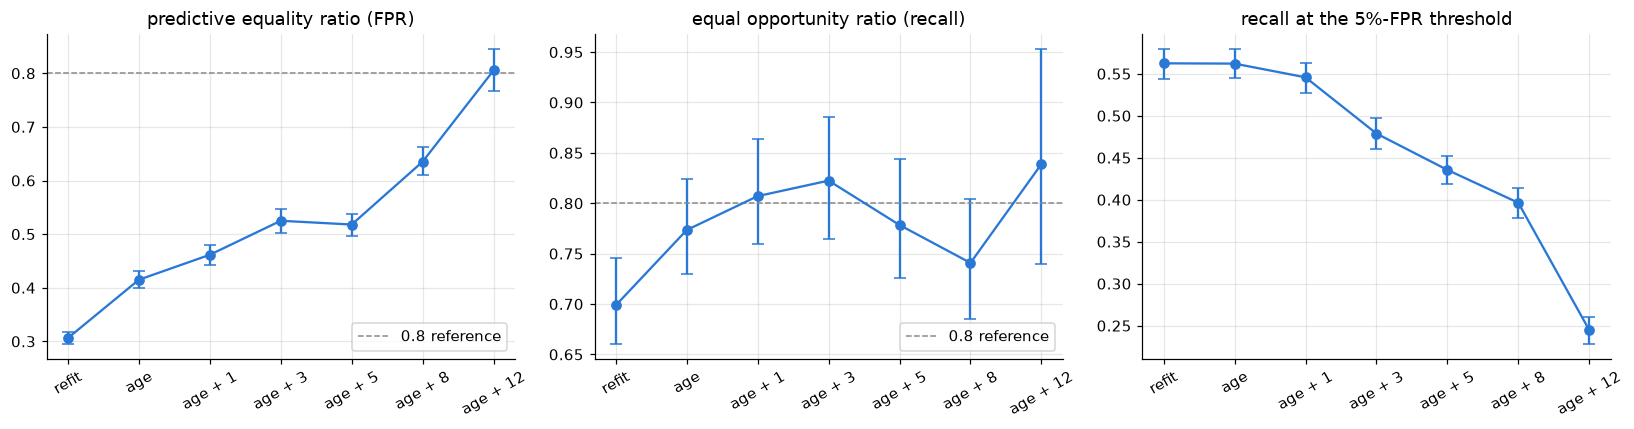

,"age predictability (AUC, section 2.4)",predictive equality (month 4),recall (month 4)
refit,NaN,0.311,0.670
age,0.859,0.402,0.660
age + 1,0.796,0.450,0.653
age + 3,0.746,0.523,0.592
age + 5,0.712,0.492,0.509
age + 8,0.678,0.577,0.485
age + 12,0.621,0.731,0.321


In [51]:
chain = ['control', 'drop_age'] + [f'proxies_{k}' for k in PROXY_GRID if k > 0]
x_labels = ['refit', 'age'] + [f'age + {k}' for k in PROXY_GRID if k > 0]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in zip(axes, ['predictive equality', 'equal opportunity', 'recall'],
                             ['predictive equality ratio (FPR)', 'equal opportunity ratio (recall)', 'recall at the 5%-FPR threshold']):
    iv = with_interval(results_test, chain, column)
    ax.errorbar(range(len(chain)), iv['estimate'], yerr=[iv['estimate'] - iv['CI low'], iv['CI high'] - iv['estimate']], fmt='o-', color=BLUE, capsize=4)
    if column != 'recall':
        ax.axhline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1, label='0.8 reference')
        ax.legend(loc='lower right')
    ax.set_xticks(range(len(chain)))
    ax.set_xticklabels(x_labels, rotation=30)
    ax.set_title(title)
plt.tight_layout()
plt.show()

curve = pd.DataFrame({'age predictability (AUC, section 2.4)': [np.nan, proxy_curve.loc[0, PROXY_ORDER_NAME]] + [proxy_curve.loc[k, PROXY_ORDER_NAME] for k in PROXY_GRID if k > 0]},
                     index=x_labels)
curve['predictive equality (month 4)'] = [results_m4[n].loc[0, 'predictive equality'] for n in chain]
curve['recall (month 4)'] = [results_m4[n].loc[0, 'recall'] for n in chain]
curve.round(3)

### **7.7 Reweighing**
Test the mitigation that targets the cause found with the variants: the link between age and fraud in the training data. Reweighing at half and full strength, with and without `customer_age` as an input, each compared with the refit control with paired intervals.

**Findings (test months)**
- **Full strength is the best of the retrained models:** predictive equality 0.90 (0.86-0.94), equal opportunity 0.98, recall -0.024 (-0.034 to -0.014), +36 cost per 10,000 at R = 10 (+20 to +51, about +3.1%), and no change in false alarms (+0.16 per 1,000, not significant).
- **The effect is far from linear in the strength.** Half strength gives only 0.50, with a small recall loss (-0.007, interval -0.014 to -0.001); full strength gives 0.90.
- **Reweighing together with dropping age is worse (0.53) than reweighing alone.** A possible reason, not tested: with age kept as an input, the model can use it to separate the age effect from the other risk factors.
- The reweighed model still takes `customer_age` as an input, as the frozen model does; what changes is that the training signal no longer links age and fraud.

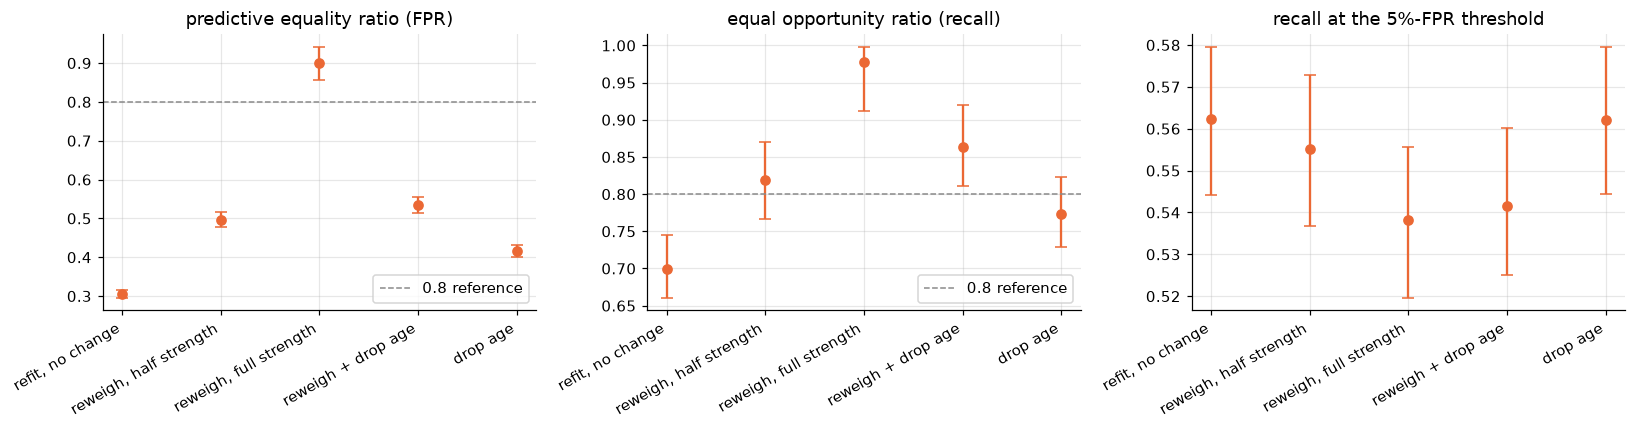

In [52]:
chain = ['control', 'reweigh_0.5', 'reweigh_1', 'reweigh_1_drop_age', 'drop_age']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in zip(axes, ['predictive equality', 'equal opportunity', 'recall'],
                             ['predictive equality ratio (FPR)', 'equal opportunity ratio (recall)', 'recall at the 5%-FPR threshold']):
    iv = with_interval(results_test, chain, column)
    ax.errorbar(range(len(chain)), iv['estimate'], yerr=[iv['estimate'] - iv['CI low'], iv['CI high'] - iv['estimate']], fmt='o', color=ORANGE, capsize=4)
    if column != 'recall':
        ax.axhline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1, label='0.8 reference')
        ax.legend(loc='lower right')
    ax.set_xticks(range(len(chain)))
    ax.set_xticklabels([LABELS[n] for n in chain], rotation=30, ha='right')
    ax.set_title(title)
plt.tight_layout()
plt.show()

### **7.8 Group-Specific Thresholds**
Show the price of group thresholds, group by group. The five rules on the test months, with the recall and FPR of each group. Equal FPR is the strongest version; "equal recall" shows what equal opportunity (instead of predictive equality) would look like.

**Findings**
- **A smooth path to equal FPR.** Predictive equality for 25, 50, 75 and 100% of the gap closed is 0.39, 0.50, 0.65 and 0.91, with recall 0.558, 0.558, 0.550 and 0.538 (-0.024 at equal FPR, interval -0.033 to -0.014).
- **The false alarms are redistributed, not removed.** They stay at about 52.4 per 1,000 applications by construction, but at equal FPR the 50+ group goes from 123 to 56 per 1,000 and the others from 38 to 52.
- **The price is in the recall of each group:** 50+ falls from 0.70 to 0.53 and the others rise from 0.49 to 0.54; overall about 3 more fraud cases are missed per 10,000 (61.6 to 64.9).
- **Equal recall** reaches 0.88 and equal opportunity 0.91 without losing overall recall, but at 6.3% overall FPR (+9.6 false alarms per 1,000, +92 cost at R = 10).
- **The two best options are equivalent in outcome.** Full-strength reweighing (0.90, recall -0.024, cost +36) and equal-FPR thresholds (0.91, recall -0.024, cost +34) give the same fairness at the same price; reweighing changes the model and needs no age-dependent cut-off, whereas thresholds change only the cut-off but use age at decision time.
- Employment CC improves with age mitigations (0.40 to 0.84 with reweighing) because most of its gap was an age effect.

,FPR 50+,FPR under 50,TPR 50+,TPR under 50,recall,FPR,predictive equality,equal opportunity,"false alarms per 1,000"
frozen model (shared threshold),0.1266,0.0389,0.6997,0.4891,0.5615,0.0531,0.3072,0.6991,52.386501
"group thresholds, FPR gap closed 25%",0.1086,0.0418,0.6629,0.5028,0.5578,0.0526,0.3851,0.7585,51.905499
"group thresholds, FPR gap closed 50%",0.0914,0.0457,0.6303,0.5195,0.5576,0.0531,0.5005,0.8242,52.386501
"group thresholds, FPR gap closed 75%",0.0751,0.0490,0.5891,0.5294,0.5499,0.0532,0.6518,0.8987,52.469398
"group thresholds, equal FPR",0.0574,0.0523,0.5323,0.5404,0.5376,0.0531,0.9118,0.9849,52.402100
"group thresholds, equal recall",0.0564,0.0641,0.5282,0.5830,0.5641,0.0629,0.8789,0.9061,61.981998


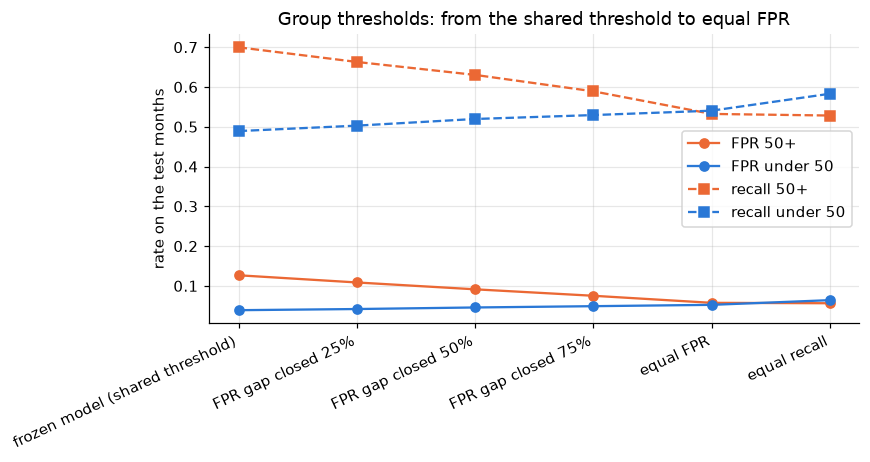

In [53]:
gt = ['frozen'] + list(GROUP_RULES)
group_view = pd.DataFrame({LABELS[n]: results_test[n].loc[0, ['FPR 50+', 'FPR under 50', 'TPR 50+', 'TPR under 50', 'recall', 'FPR', 'predictive equality',
                                                              'equal opportunity', 'false alarms per 1,000']] for n in gt}).T
display(group_view.round(4))

fig, ax = plt.subplots(figsize=(8, 4.3))
for column, colour, label in [('FPR 50+', ORANGE, 'FPR 50+'), ('FPR under 50', BLUE, 'FPR under 50')]:
    ax.plot(range(len(gt)), [results_test[n].loc[0, column] for n in gt], marker='o', color=colour, label=label)
for column, colour, label in [('TPR 50+', ORANGE, 'recall 50+'), ('TPR under 50', BLUE, 'recall under 50')]:
    ax.plot(range(len(gt)), [results_test[n].loc[0, column] for n in gt], marker='s', linestyle='--', color=colour, label=label)
ax.set_xticks(range(len(gt)))
ax.set_xticklabels([LABELS[n].replace('group thresholds, ', '') for n in gt], rotation=25, ha='right')
ax.set_ylabel('rate on the test months')
ax.set_title('Group thresholds: from the shared threshold to equal FPR')
ax.legend()
plt.tight_layout()
plt.show()

## **8. The Trade-Off Between Fairness and Fraud Detection**
The mitigations give many candidates, each with a different mix of fairness and cost. This section answers two questions: which candidate is best for a given requirement, and what each fairness gain costs in fraud caught, false alarms and money. The requirement is a cap on the FPR gap, and the choice is made on month 4 (not the test months). The test months then report the chosen candidates.

**Findings**
- The tighter the requirement, the more it costs, and a cap of 0.02-0.04 on the FPR gap is the sensible region (predictive equality 0.85 on month 4).
- Reweighing and equal-FPR thresholds are tied; fairness costs +34-36 per 10,000 at R = 10, and the ordering of the candidates barely changes with the cost ratio.
- In practice, closing the gap moves about 67 false alarms per 1,000 away from the 50+ group, at a price of 13 more per 1,000 for the others and about 3 more missed frauds per 10,000.

### **8.1 Choosing on Month 4**
Pick the best candidate for each fairness requirement, without looking at the test months. The requirement is a **cap on the FPR gap**: the absolute difference between the FPR of the 50+ group and of the others must not exceed delta. Among the candidates that meet the cap, the one with the lowest cost at a cost ratio R is chosen (the constrained minimum-cost rule). Month 4 is used because the model never trained on it and the thresholds were set on month 5. There is no standard cap, so five values are tried (0.10, 0.06, 0.04, 0.02, 0.01), with R = 5, 10, 20 and 50 (the values of notebook 04). Cost is R x missed fraud + false alarms, per 10,000 applications. No standard exists for a cap on a difference of FPR. 0.10 is looser than the frozen model's gap and does not bind; 0.01 is one percentage point (nearly equal FPR). The choice at each cap is shown and none is declared the answer.

**Findings**
- With a cap of 0.04 or 0.02, the cheapest candidate is equal-FPR group thresholds at R = 5 and 10, and full-strength reweighing at R = 20 and 50; at R = 10 they differ by about 4 in cost (1168.5 against 1173.0), so it is a tie.
- A cap of 0.01 forces the equal-recall rule, which costs about four times as much as a cap of 0.02-0.04 at R = 10 (+128 against +32).
- A loose cap (0.10) picks something close to the frozen model.
- **A weakness of choosing on month 4.** At R = 5 the loose caps pick "drop age + 5 proxies" because it was 27 cheaper than the frozen model on month 4, but on the test months it is about +62 more expensive. Thresholds are set on month 5 and, because of drift, each model flags a different share of month-4 applications, so the month-4 cost partly reflects the number of alerts and not the ranking quality. This pick should not be used; the picks at R = 10-50 are consistent with the test results.

In [54]:
DELTAS = [0.10, 0.06, 0.04, 0.02, 0.01]
gap_m4 = pd.Series({n: results_m4[n].loc[0, 'FPR gap'] for n in CANDIDATES})
print('FPR gap on month 4 (50+ minus under 50, absolute):')
display(gap_m4.rename(index=LABELS).round(4).to_frame('FPR gap'))


def choose(delta, ratio, results=results_m4):
    feasible = [n for n in CANDIDATES if results[n].loc[0, 'FPR gap'] <= delta]
    if not feasible:
        return None
    return min(feasible, key=lambda n: results[n].loc[0, f'cost per 10,000 (R={ratio})'])


choice_table = pd.DataFrame({f'R = {ratio}': {f'gap <= {delta:.2f}': (LABELS[choose(delta, ratio)] if choose(delta, ratio) else 'none meets the cap') for delta in DELTAS}
                             for ratio in COST_RATIOS})
print('Choice on month 4, for every cap (rows) and cost ratio (columns):')
choice_table

FPR gap on month 4 (50+ minus under 50, absolute):


,FPR gap
frozen model (shared threshold),0.1209
"refit, no change",0.1216
drop age,0.0902
drop age + 1 proxies,0.0783
drop age + 3 proxies,0.0558
drop age + 5 proxies,0.0565
drop age + 8 proxies,0.0513
drop age + 12 proxies,0.0238
"reweigh, half strength",0.0679
"reweigh, full strength",0.0132


Choice on month 4, for every cap (rows) and cost ratio (columns):


,R = 5,R = 10,R = 20,R = 50
gap <= 0.10,drop age + 5 proxies,"group thresholds, FPR gap closed 25%","group thresholds, FPR gap closed 25%","group thresholds, FPR gap closed 25%"
gap <= 0.06,drop age + 5 proxies,"group thresholds, FPR gap closed 75%","group thresholds, FPR gap closed 75%","group thresholds, FPR gap closed 75%"
gap <= 0.04,"group thresholds, equal FPR","group thresholds, equal FPR","reweigh, full strength","reweigh, full strength"
gap <= 0.02,"group thresholds, equal FPR","group thresholds, equal FPR","reweigh, full strength","reweigh, full strength"
gap <= 0.01,"group thresholds, equal recall","group thresholds, equal recall","group thresholds, equal recall","group thresholds, equal recall"


In [55]:
rows = []
for ratio in COST_RATIOS:
    for delta in DELTAS:
        name = choose(delta, ratio)
        if name is None:
            continue
        rows.append({'R': ratio, 'cap': delta, 'chosen': LABELS[name], 'month-4 cost': results_m4[name].loc[0, f'cost per 10,000 (R={ratio})'],
                     'frozen model month-4 cost': results_m4['frozen'].loc[0, f'cost per 10,000 (R={ratio})'],
                     'month-4 recall': results_m4[name].loc[0, 'recall'], 'month-4 FPR gap': results_m4[name].loc[0, 'FPR gap'],
                     'month-4 predictive equality': results_m4[name].loc[0, 'predictive equality']})
selection_detail = pd.DataFrame(rows).set_index(['R', 'cap'])
selection_detail['extra cost'] = selection_detail['month-4 cost'] - selection_detail['frozen model month-4 cost']
selection_detail.round(3)

chosen  month-4 cost  \
R  cap                                                        
5  0.10                  drop age + 5 proxies    923.192017   
   0.06                  drop age + 5 proxies    923.192017   
   0.04           group thresholds, equal FPR    953.833984   
   0.02           group thresholds, equal FPR    953.833984   
   0.01        group thresholds, equal recall   1060.498047   
10 0.10  group thresholds, FPR gap closed 25%   1135.208984   
   0.06  group thresholds, FPR gap closed 75%   1153.425049   
   0.04           group thresholds, equal FPR   1168.493042   
   0.02           group thresholds, equal FPR   1168.493042   
   0.01        group thresholds, equal recall   1264.818970   
20 0.10  group thresholds, FPR gap closed 25%   1515.659058   
   0.06  group thresholds, FPR gap closed 75%   1556.741943   
   0.04                reweigh, full strength   1597.162964   
   0.02                reweigh, full strength   1597.162964   
   0.01        group thresholds, equal recall   1673.462036   
50 0.10  group thresholds, FPR gap closed 25%   2657.008057   
   0.06  group thresholds, FPR gap closed 75%   2766.694092   
   0.04                reweigh, full strength   2869.766113   
   0.02                reweigh, full strength   2869.766113   
   0.01        group thresholds, equal recall   2899.389893   

         frozen model month-4 cost  month-4 recall  month-4 FPR gap  \
R  cap                                                                
5  0.10                 949.918030           0.509            0.056   
   0.06                 949.918030           0.509            0.056   
   0.04                 949.918030           0.622            0.013   
   0.02                 949.918030           0.622            0.013   
   0.01                 949.918030           0.641            0.003   
10 0.10                1136.384033           0.665            0.095   
   0.06                1136.384033           0.645            0.042   
   0.04                1136.384033           0.622            0.013   
   0.02                1136.384033           0.622            0.013   
   0.01                1136.384033           0.641            0.003   
20 0.10                1509.314941           0.665            0.095   
   0.06                1509.314941           0.645            0.042   
   0.04                1509.314941           0.627            0.013   
   0.02                1509.314941           0.627            0.013   
   0.01                1509.314941           0.641            0.003   
50 0.10                2628.110107           0.665            0.095   
   0.06                2628.110107           0.645            0.042   
   0.04                2628.110107           0.627            0.013   
   0.02                2628.110107           0.627            0.013   
   0.01                2628.110107           0.641            0.003   

         month-4 predictive equality  extra cost  
R  cap                                            
5  0.10                        0.492  -26.726000  
   0.06                        0.492  -26.726000  
   0.04                        0.850    3.916000  
   0.02                        0.850    3.916000  
   0.01                        0.962  110.579002  
10 0.10                        0.383   -1.175000  
   0.06                        0.618   17.041000  
   0.04                        0.850   32.109001  
   0.02                        0.850   32.109001  
   0.01                        0.962  128.434998  
20 0.10                        0.383    6.344000  
   0.06                        0.618   47.426998  
   0.04                        0.847   87.848000  
   0.02                        0.847   87.848000  
   0.01                        0.962  164.145996  
50 0.10                        0.383   28.898001  
   0.06                        0.618  138.584000  
   0.04                        0.847  241.656006  
   0.02                        0.847  241.656006  
   0.01           

### **8.2 The Chosen Candidates on the Test Months**
Report the candidates chosen on month 4 on the test months, with intervals. For the five caps at R = 10, each chosen candidate is shown next to the frozen model and the refit control. Differences are **paired** (same resamples), against the refit control for retrained models and the frozen model for group thresholds, because each pair has the same seeds.

**Findings**
- The five caps pick four distinct candidates: gap closed 25% (predictive equality 0.385, recall 0.558, cost 1140), 75% (0.652, 0.550, 1157), equal FPR (0.912, 0.538, 1173) and equal recall (0.879, 0.564, cost 1232 with overall FPR 6.3%). The frozen model is 0.307, 0.562 and 1139.
- Paired differences are narrow: for example, drop age gains +0.109 in predictive equality (+0.102 to +0.116) with recall -0.000 (-0.006 to +0.006) and cost +16.5 (+8.2 to +25.5).

In [56]:
REFERENCE = {name: ('control' if FAMILY[name] == 'retrained' else 'frozen') for name in CANDIDATES}
DIFF_COLUMNS = ['recall', 'false alarms per 1,000', 'cost per 10,000 (R=10)', 'predictive equality', 'FPR gap']


def difference_table(names):
    rows = []
    for name in names:
        ref = REFERENCE[name]
        row = {'candidate': LABELS[name], 'compared with': LABELS[ref] if ref != name else '(reference)'}
        for column in DIFF_COLUMNS:
            if ref == name:
                row[column] = '0'
                continue
            d = paired_difference(results_test, name, ref, column)
            row[column] = f"{d['difference']:+.3f} ({d['CI low']:+.3f} to {d['CI high']:+.3f})"
        rows.append(row)
    return pd.DataFrame(rows).set_index('candidate')


chosen_names = []
for delta in DELTAS:
    name = choose(delta, 10)
    if name and name not in chosen_names:
        chosen_names.append(name)
print('chosen on month 4 at R = 10, for the five caps:', [LABELS[n] for n in chosen_names])
pd.DataFrame({LABELS[n]: results_test[n].loc[0, SUMMARY_COLUMNS] for n in ['frozen', 'control'] + chosen_names}).T.round(4)

chosen on month 4 at R = 10, for the five caps: ['group thresholds, FPR gap closed 25%', 'group thresholds, FPR gap closed 75%', 'group thresholds, equal FPR', 'group thresholds, equal recall']


,recall,FPR,FPR 50+,FPR under 50,predictive equality,equal opportunity,"false alarms per 1,000","cost per 10,000 (R=10)"
frozen model (shared threshold),0.5615,0.0531,0.1266,0.0389,0.3072,0.6991,52.386501,1139.441284
"refit, no change",0.5624,0.0530,0.1266,0.0388,0.3063,0.6987,52.299599,1137.272339
"group thresholds, FPR gap closed 25%",0.5578,0.0526,0.1086,0.0418,0.3851,0.7585,51.905499,1139.802246
"group thresholds, FPR gap closed 75%",0.5499,0.0532,0.0751,0.0490,0.6518,0.8987,52.469398,1156.562378
"group thresholds, equal FPR",0.5376,0.0531,0.0574,0.0523,0.9118,0.9849,52.402100,1173.156616
"group thresholds, equal recall",0.5641,0.0629,0.0564,0.0641,0.8789,0.9061,61.981998,1231.690063


In [57]:
print('Paired differences on the test months (candidate minus its reference), with 95% intervals')
difference_table([n for n in CANDIDATES if n not in ('frozen', 'control')])

Paired differences on the test months (candidate minus its reference), with 95% intervals


,compared with,recall,"false alarms per 1,000","cost per 10,000 (R=10)",predictive equality,FPR gap
candidate,,,,,,
drop age,"refit, no change",-0.000 (-0.006 to +0.006),+1.597 (+1.228 to +1.960),+16.454 (+8.151 to +25.482),+0.109 (+0.102 to +0.116),-0.025 (-0.027 to -0.024)
drop age + 1 proxies,"refit, no change",-0.017 (-0.025 to -0.009),-0.707 (-1.141 to -0.275),+16.341 (+4.657 to +28.271),+0.155 (+0.145 to +0.166),-0.037 (-0.038 to -0.035)
drop age + 3 proxies,"refit, no change",-0.084 (-0.097 to -0.071),-4.548 (-5.282 to -3.807),+71.915 (+51.840 to +90.923),+0.219 (+0.201 to +0.236),-0.050 (-0.052 to -0.047)
drop age + 5 proxies,"refit, no change",-0.127 (-0.143 to -0.113),-2.512 (-3.371 to -1.637),+153.081 (+128.448 to +177.369),+0.212 (+0.194 to +0.229),-0.047 (-0.050 to -0.044)
drop age + 8 proxies,"refit, no change",-0.166 (-0.182 to -0.148),+1.901 (+0.860 to +2.886),+252.165 (+224.163 to +277.684),+0.329 (+0.307 to +0.353),-0.059 (-0.063 to -0.056)
drop age + 12 proxies,"refit, no change",-0.318 (-0.336 to -0.299),-6.270 (-7.405 to -5.149),+383.297 (+349.010 to +416.483),+0.499 (+0.464 to +0.538),-0.077 (-0.081 to -0.073)
"reweigh, half strength","refit, no change",-0.007 (-0.014 to -0.001),-0.382 (-0.776 to -0.018),+6.422 (-3.382 to +16.343),+0.190 (+0.179 to +0.201),-0.042 (-0.044 to -0.040)
"reweigh, full strength","refit, no change",-0.024 (-0.034 to -0.014),+0.156 (-0.422 to +0.715),+35.543 (+19.953 to +50.854),+0.594 (+0.558 to +0.628),-0.082 (-0.085 to -0.080)
reweigh + drop age,"refit, no change",-0.021 (-0.028 to -0.013),-1.150 (-1.591 to -0.675),+17.771 (+5.077 to +29.423),+0.228 (+0.214 to +0.241),-0.048 (-0.050 to -0.046)


### **8.3 The Whole Picture: Fairness Against Recall and Against Cost**
- Show every candidate on the test months in one picture.
- Left: predictive equality against recall (up and to the right is better on both); the line joins the candidates that no other candidate beats on both. Right: the absolute FPR gap against the cost at R = 10 (down and to the left is better on both). The frontier describes the test results and is not a basis for choosing: choices were made on month 4.

**Findings**
- The candidates at the top of the predictive equality axis are full-strength reweighing and equal-FPR thresholds (about 0.90 and 0.91, recall 0.54), and equal-recall thresholds (0.88) at higher recall (0.564).
- Dropping proxies lies far to the left (low recall) for the same predictive equality: 12 proxies reach 0.805 with recall 0.245.

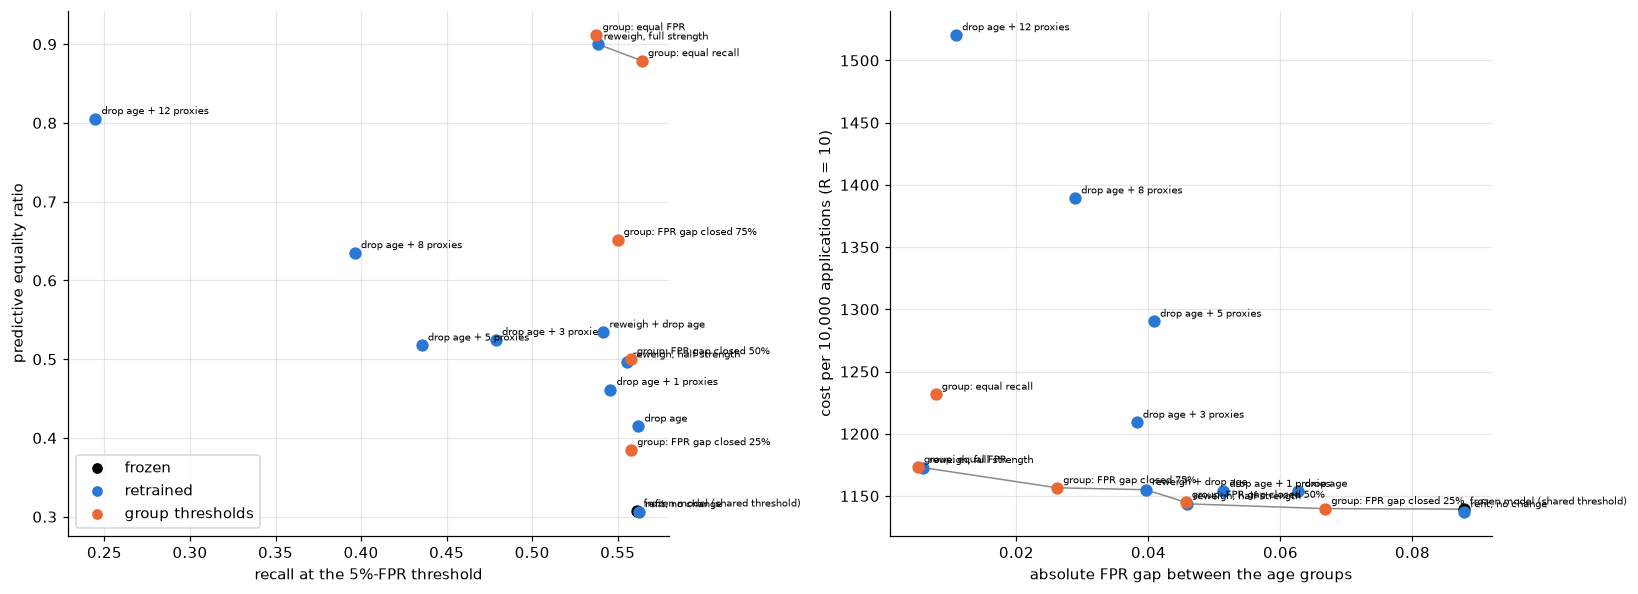

In [58]:
FAMILY_COLOUR = {'frozen': 'black', 'retrained': BLUE, 'group thresholds': ORANGE}
points = pd.DataFrame({'recall': [results_test[n].loc[0, 'recall'] for n in CANDIDATES],
                       'PE': [results_test[n].loc[0, 'predictive equality'] for n in CANDIDATES],
                       'gap': [results_test[n].loc[0, 'FPR gap'] for n in CANDIDATES],
                       'cost': [results_test[n].loc[0, 'cost per 10,000 (R=10)'] for n in CANDIDATES]}, index=CANDIDATES)


def front(df, x, y, x_higher_better, y_higher_better):
    keep = []
    for n, r in df.iterrows():
        dominated = False
        for m, s in df.iterrows():
            if m == n:
                continue
            better_x = s[x] >= r[x] if x_higher_better else s[x] <= r[x]
            better_y = s[y] >= r[y] if y_higher_better else s[y] <= r[y]
            strictly = (s[x] != r[x]) or (s[y] != r[y])
            if better_x and better_y and strictly:
                dominated = True
                break
        if not dominated:
            keep.append(n)
    return df.loc[keep].sort_values(x)


fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, x, y, xl, yl, xh, yh in [(axes[0], 'recall', 'PE', 'recall at the 5%-FPR threshold', 'predictive equality ratio', True, True),
                                 (axes[1], 'gap', 'cost', 'absolute FPR gap between the age groups', 'cost per 10,000 applications (R = 10)', False, False)]:
    for n in CANDIDATES:
        ax.scatter(points.loc[n, x], points.loc[n, y], color=FAMILY_COLOUR[FAMILY[n]], s=50, zorder=3)
        ax.annotate(LABELS[n].replace('group thresholds, ', 'group: '), (points.loc[n, x], points.loc[n, y]), fontsize=6.5, xytext=(4, 3), textcoords='offset points')
    f = front(points, x, y, xh, yh)
    ax.plot(f[x], f[y], color=GREY, linewidth=1, zorder=1)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
for fam, colour in FAMILY_COLOUR.items():
    axes[0].scatter([], [], color=colour, label=fam)
axes[0].legend(loc='lower left')
plt.tight_layout()
plt.show()

### **8.4 Does the Answer Depend on the Cost Ratio?**
The real cost of a missed fraud is unknown, so check whether the conclusion depends on it. The extra cost of each candidate compared with the frozen model, at R = 5, 10, 20 and 50, on the test months. If the ordering is the same at every R, the conclusion does not depend on R.

**Findings**
- **Extra cost over the frozen model at R = 5, 10, 20, 50:** full-strength reweighing +17, +33, +66, +164; equal-FPR thresholds +17, +34, +67, +168 (both are paid in missed fraud, so they grow with R); equal-recall thresholds +94, +92, +89, +77 (paid in false alarms, so they stay flat).
- **The ordering changes only at the high end:** at R = 50 equal recall (+77) is cheaper than equal FPR (+168), but at R = 20 or below it is not.
- Drop age costs about +14 at every R (+15, +14, +14, +11), and proxy removal climbs steeply with R (12 proxies: +159, +381, +826, +2,160).

,R = 5,R = 10,R = 20,R = 50
"refit, no change",-1.500000,-2.200000,-3.500000,-7.400000
drop age,14.700000,14.300000,13.500000,11.000000
drop age + 1 proxies,3.100000,14.200000,36.299999,102.599998
drop age + 3 proxies,11.700000,69.699997,185.800003,534.099976
drop age + 5 proxies,62.500000,150.899994,327.799988,858.500000
drop age + 8 proxies,134.100006,250.000000,481.899994,1177.400024
drop age + 12 proxies,158.800003,381.100006,825.799988,2159.899902
"reweigh, half strength",-0.200000,4.300000,13.200000,40.000000
"reweigh, full strength",17.000000,33.400002,66.099998,164.100006
reweigh + drop age,1.600000,15.600000,43.599998,127.500000


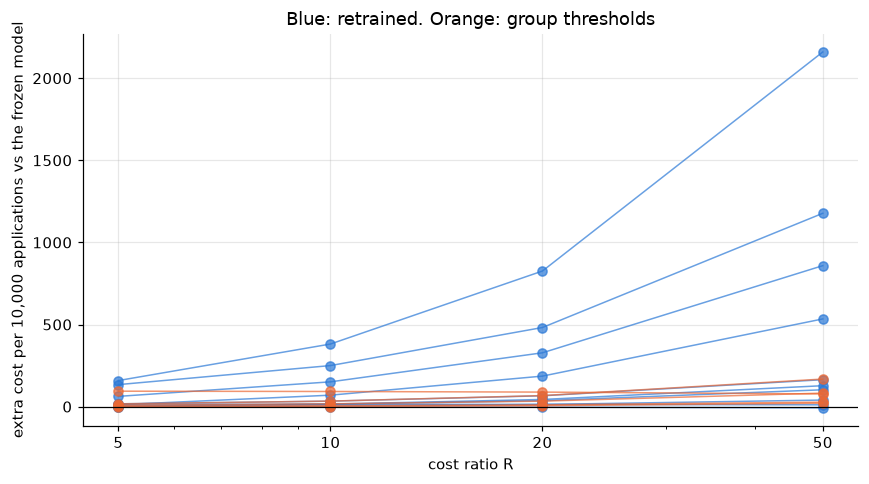

In [59]:
cost_columns = [f'cost per 10,000 (R={r})' for r in COST_RATIOS]
extra = pd.DataFrame({LABELS[n]: [results_test[n].loc[0, c] - results_test['frozen'].loc[0, c] for c in cost_columns] for n in CANDIDATES if n != 'frozen'},
                     index=[f'R = {r}' for r in COST_RATIOS]).T
display(extra.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
for n in CANDIDATES:
    if n == 'frozen':
        continue
    ax.plot(COST_RATIOS, [results_test[n].loc[0, c] - results_test['frozen'].loc[0, c] for c in cost_columns], marker='o', color=FAMILY_COLOUR[FAMILY[n]], alpha=0.7, linewidth=1)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xscale('log')
ax.set_xticks(COST_RATIOS)
ax.set_xticklabels(COST_RATIOS)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel('cost ratio R')
ax.set_ylabel('extra cost per 10,000 applications vs the frozen model')
ax.set_title('Blue: retrained. Orange: group thresholds')
plt.tight_layout()
plt.show()

### **8.5 What the Fairness Costs in Operations**
Express the trade-off in terms a fraud team can use. For the frozen model and the chosen candidates: false alarms per 1,000 applications **of each group**, fraud cases missed per 10,000 applications, and recall by group. A fairer model has fewer false alarms for the 50+ group; the question is how many more fraud cases are missed and how many more false alarms the other group gets.

**Findings**
- **The gap in practice.** The frozen model gives 123 false alarms per 1,000 applications of the 50+ group and 38 per 1,000 of the others, with the same overall alert volume (52 per 1,000).
- **What reweighing or equal FPR changes.** The 50+ group falls to 56 false alarms per 1,000 and the others rise to 52 (reweighing: 56.4 and 51.7; equal FPR: 55.7 and 51.8). Missed fraud rises from 61.6 to 64.8-64.9 per 10,000 (about 3 more).
- **Who loses recall.** The 50+ group's recall falls from 0.70 to 0.53 and the others' rises from 0.49 to 0.54. The group that is flagged less is the one where more fraud passes, and this must be stated with the result.
- **Equal recall** adds false alarms for the others (63 per 1,000) and raises the overall alert volume to 62 per 1,000, with 61.2 fraud cases missed per 10,000.
- Month 6 and month 7 give the same picture (equal-FPR thresholds: 0.93 and 0.92 against 0.31 for the frozen model).

In [60]:
fraud_rate_test = y_mit[is_test].mean()
ops = pd.DataFrame({LABELS[n]: {'false alarms per 1,000, 50+': results_test[n].loc[0, 'false alarms per 1,000, 50+'],
                                'false alarms per 1,000, under 50': results_test[n].loc[0, 'false alarms per 1,000, under 50'],
                                'false alarms per 1,000, all': results_test[n].loc[0, 'false alarms per 1,000'],
                                'fraud missed per 10,000, all': 10_000 * fraud_rate_test * (1 - results_test[n].loc[0, 'recall']),
                                'recall 50+': results_test[n].loc[0, 'TPR 50+'], 'recall under 50': results_test[n].loc[0, 'TPR under 50']}
                    for n in list(dict.fromkeys(['frozen', 'control'] + chosen_names + ['reweigh_1']))}).T
ops.round(2)

,"false alarms per 1,000, 50+","false alarms per 1,000, under 50","false alarms per 1,000, all","fraud missed per 10,000, all",recall 50+,recall under 50
frozen model (shared threshold),122.93,38.47,52.39,61.56,0.70,0.49
"refit, no change",122.94,38.37,52.30,61.43,0.70,0.49
"group thresholds, FPR gap closed 25%",105.41,41.35,51.91,62.07,0.66,0.50
"group thresholds, FPR gap closed 75%",72.93,48.43,52.47,63.19,0.59,0.53
"group thresholds, equal FPR",55.71,51.75,52.40,64.91,0.53,0.54
"group thresholds, equal recall",54.71,63.42,61.98,61.19,0.53,0.58
"reweigh, full strength",56.37,51.68,52.46,64.83,0.53,0.54


## **9. Does a Mitigation Carry Over?**
A mitigation chosen on one month of one dataset is only useful if it holds up on other months and on other data.

Two checks: the same candidates on month 6 and month 7 separately (thresholds unchanged), and the recipes carried to the BAF variants, trained again on each variant's months 0-3 with its own month-5 thresholds and no retuning. Variants II and IV (gap 0.14-0.15) are where a mitigation has the most to repair; variants I, III and V (gap small) are where it must do no harm. A fourth part extends reweighing to housing status.

**Findings**
- The mitigations are stable from month 6 to month 7.
- **Full-strength reweighing carries over to every dataset:** it repairs variants II and IV to about 0.85 and does no harm to the others.
- Reweighing is the preferred option: a realistic path to age fairness exists at a small, measured price. Housing status is a larger and costlier gap that age mitigations do not repair.

### **9.1 Across Months**
Check that a mitigation's fairness is not a one-month accident. The frozen model, the refit control, the candidates chosen on month 4 at R = 10 and full-strength reweighing, on month 6 and month 7 separately, with the thresholds unchanged.

**Findings**
- Predictive equality is stable between the two months: reweighing 0.919 and 0.908, equal-FPR thresholds 0.932 and 0.919, equal recall 0.861 and 0.871, against 0.315 and 0.308 for the frozen model.
- The cost level moves with the alert volume, not with the mitigation: the overall FPR is 5.7-5.9% in month 6 and 4.7-4.9% in month 7, so the cost at R = 10 is about 1,170-1,200 in month 6 and 1,100-1,140 in month 7 for every candidate.

In [61]:
test_months_of_rows = mit.loc[is_test, 'month'].to_numpy()
shown = list(dict.fromkeys(['frozen', 'control'] + chosen_names + ['reweigh_1']))
rows = []
for month in TEST_MONTHS:
    sel = test_months_of_rows == month
    month_results = evaluate_flags(y_mit[is_test][sel], old_mit[is_test][sel], {n: {s: f[sel] for s, f in flags_at['test'][n].items()} for n in shown}, n_resamples=0)
    for n in shown:
        rows.append({'month': month, 'candidate': LABELS[n], **month_results[n].loc[0, ['recall', 'FPR', 'predictive equality', 'equal opportunity', 'cost per 10,000 (R=10)']]})
pd.DataFrame(rows).set_index(['candidate', 'month']).sort_index(level=0, sort_remaining=True).round(4)

recall     FPR  \
candidate                            month                   
frozen model (shared threshold)      6      0.5614  0.0589   
                                     7      0.5616  0.0467   
group thresholds, FPR gap closed 25% 6      0.5523  0.0580   
                                     7      0.5634  0.0467   
group thresholds, FPR gap closed 75% 6      0.5392  0.0574   
                                     7      0.5608  0.0485   
group thresholds, equal FPR          6      0.5237  0.0569   
                                     7      0.5517  0.0490   
group thresholds, equal recall       6      0.5472  0.0669   
                                     7      0.5814  0.0584   
refit, no change                     6      0.5637  0.0588   
                                     7      0.5612  0.0466   
reweigh, full strength               6      0.5262  0.0570   
                                     7      0.5504  0.0490   

                                            predictive equality  \
candidate                            month                        
frozen model (shared threshold)      6                   0.3145   
                                     7                   0.3075   
group thresholds, FPR gap closed 25% 6                   0.3935   
                                     7                   0.3875   
group thresholds, FPR gap closed 75% 6                   0.6643   
                                     7                   0.6593   
group thresholds, equal FPR          6                   0.9319   
                                     7                   0.9188   
group thresholds, equal recall       6                   0.8606   
                                     7                   0.8710   
refit, no change                     6                   0.3143   
                                     7                   0.3056   
reweigh, full strength               6                   0.9194   
                                     7                   0.9079   

                                            equal opportunity  \
candidate                            month                      
frozen model (shared threshold)      6                 0.6979   
                                     7                 0.6940   
group thresholds, FPR gap closed 25% 6                 0.7556   
                                     7                 0.7529   
group thresholds, FPR gap closed 75% 6                 0.8959   
                                     7                 0.8909   
group thresholds, equal FPR          6                 0.9811   
                                     7                 0.9988   
group thresholds, equal recall       6                 0.9033   
                                     7                 0.9204   
refit, no change                     6                 0.7025   
                                     7                 0.6892   
reweigh, full strength               6                 0.9721   
                                     7                 0.9934   

                                            cost per 10,000 (R=10)  
candidate                            month                          
frozen model (shared threshold)      6                 1169.310669  
                                     7                 1106.078857  
group thresholds, FPR gap closed 25% 6                 1172.010254  
                                     7                 1103.827881  
group thresholds, FPR gap closed 75% 6                 1184.472290  
                                     7                 1125.388550  
group thresholds, equal FPR          6                 1199.356567  
                                     7                 1143.892700  
group thresholds, equal recall       6                 1266.585327  
                                     7                 1192.713989  
refit, no change                     6                 1165.131958  
                                     7  

### **9.2 Which Recipe to Carry to the Variants**
Fix, before looking at the variants, which retrained recipe is carried to them. Among the retrained settings (not the control), keep those whose recall on month 4 is not more than 0.02 below the control's (about the sampling interval of recall in notebook 04, so a smaller loss cannot be told from noise), and take the one with the highest predictive equality on month 4. Full-strength reweighing is carried as well.

**Findings.** The control's recall on month 4 is 0.670, and three settings are eligible (drop age, drop age plus 1 proxy, reweighing at half strength). The rule picks **reweighing at half strength**, which only reaches 0.50 on Base, so full-strength reweighing is carried too and is the one that matters.

In [62]:
FREE_RECALL_LOSS = 0.02
retrained_keys = [k for k in MITIGATIONS if k != 'control']
control_recall = results_m4['control'].loc[0, 'recall']
eligible = [k for k in retrained_keys if results_m4[k].loc[0, 'recall'] >= control_recall - FREE_RECALL_LOSS]
picked = max(eligible, key=lambda k: results_m4[k].loc[0, 'predictive equality']) if eligible else None
CARRY_KEYS = list(dict.fromkeys(([picked] if picked else []) + ['reweigh_1']))
print(f'control recall on month 4: {control_recall:.3f}; eligible (recall within {FREE_RECALL_LOSS} of it): {[LABELS[k] for k in eligible]}')
print('carried to the variants:', [LABELS[k] for k in CARRY_KEYS])
pd.DataFrame({LABELS[k]: results_m4[k].loc[0, ['recall', 'predictive equality', 'equal opportunity']] for k in ['control'] + retrained_keys}).T.round(4)

control recall on month 4: 0.670; eligible (recall within 0.02 of it): ['drop age', 'drop age + 1 proxies', 'reweigh, half strength']
carried to the variants: ['reweigh, half strength', 'reweigh, full strength']


,recall,predictive equality,equal opportunity
"refit, no change",0.6701,0.3110,0.7652
drop age,0.6605,0.4016,0.8440
drop age + 1 proxies,0.6534,0.4503,0.8800
drop age + 3 proxies,0.5916,0.5232,0.9183
drop age + 5 proxies,0.5094,0.4924,0.9515
drop age + 8 proxies,0.4851,0.5768,0.9637
drop age + 12 proxies,0.3212,0.7309,0.9840
"reweigh, half strength",0.6609,0.4856,0.8875
"reweigh, full strength",0.6270,0.8470,0.8893
reweigh + drop age,0.6467,0.5381,0.9343


In [63]:
VAR_CACHE = f'{DATA_DIR}/cache/variant_mitigation_scores.parquet'
VARIANT_NAMES = [d for d in DATASETS if d != 'base']


def variant_scores(dataset):
    df = pd.read_csv(f'{DATA_DIR}/{DATASET_FILES[dataset]}')
    train_part = df[df['month'].isin(TRAIN_MONTHS)]
    X_train = make_features(train_part, **FEATURES)
    y_tr, old_tr = train_part[TARGET].to_numpy(), (train_part['customer_age'] >= AGE_CUT).to_numpy()
    score_part = df[df['month'].isin(CALIBRATION_MONTHS + TEST_MONTHS)]
    X_score = make_features(score_part, **FEATURES)
    table = pd.DataFrame({'dataset': dataset, 'row_id': score_part.index.to_numpy(), 'month': score_part['month'].to_numpy(),
                          'y_true': score_part[TARGET].to_numpy(), 'customer_age': score_part['customer_age'].to_numpy()})
    for key in CARRY_KEYS:
        for seed in MIT_SEEDS:
            table[column_name(key, seed)] = fit_and_score(MITIGATIONS[key], X_train, y_tr, old_tr, X_score, seed)
    return table


need = [column_name(k, s) for k in CARRY_KEYS for s in MIT_SEEDS]
variant_mit = pd.read_parquet(VAR_CACHE) if os.path.exists(VAR_CACHE) else None
if variant_mit is not None and not all(c in variant_mit for c in need):
    variant_mit = None
    print('the saved scores are for other recipes: training again')
if variant_mit is None:
    start = time.time()
    parts = []
    for dataset in VARIANT_NAMES:
        parts.append(variant_scores(dataset))
        print(f'{dataset:12s} {len(CARRY_KEYS)} recipes x {len(MIT_SEEDS)} seeds trained, {(time.time() - start) / 60:.1f} min so far')
    variant_mit = pd.concat(parts, ignore_index=True)
    try:
        variant_mit.to_parquet(VAR_CACHE, index=False)
    except Exception as error:
        print(f'the scores could not be saved ({type(error).__name__}); they stay in memory')
else:
    print(f'Loaded the saved scores from {VAR_CACHE}')
variant_mit['dataset'] = pd.Categorical(variant_mit['dataset'], categories=DATASETS)

variant_i    2 recipes x 3 seeds trained, 0.5 min so far


variant_ii   2 recipes x 3 seeds trained, 1.0 min so far


variant_iii  2 recipes x 3 seeds trained, 1.5 min so far


variant_iv   2 recipes x 3 seeds trained, 2.0 min so far


variant_v    2 recipes x 3 seeds trained, 2.5 min so far


### **9.3 The Results on Every Dataset**
Test whether the mitigations work on other data, and whether they do harm where the model was already fair. For each dataset (Base included): the untreated retrained model, equal-FPR group thresholds applied to it, and the two carried recipes. Thresholds come from each dataset's own month 5, the test months are 6-7, and intervals are from 1,000 paired resamples.

**Findings**

| Dataset | untreated | half strength | full strength | equal-FPR thresholds | recall change, full strength |
|---|---|---|---|---|---|
| Base | 0.31 | 0.50 | 0.90 | 0.91 | -0.024 |
| Variant I | 0.83 | 0.90 | 0.96 | 0.90 | -0.004 |
| Variant II | 0.14 | 0.36 | 0.86 | 0.94 | -0.052 |
| Variant III | 0.93 | 0.95 | 0.98 | 0.91 | -0.000 |
| Variant IV | 0.15 | 0.37 | 0.85 | 0.94 | **+0.060** |
| Variant V | 0.91 | 0.92 | 0.95 | 0.91 | +0.003 |

(predictive equality; the last column is the change in recall at the operating point.)
- Variants I, III and V were already fair and are not harmed (recall within 0.005). Variants II and IV, with a gap of 0.14-0.15, are repaired to 0.86 and 0.85.
- **The recall results fit the cause.** In variant IV the age bias is in the training months only, and removing it **raises** recall by 6.0 points (0.46 to 0.52). In variant II the difference in fraud rate is also in the test data (2.3% against 0.5%), as on Base, and repairing the gap costs 5.2 points of recall (2.4 points on Base). When the age-fraud link is a distortion of the training data, fixing it is free or better; when it is a real difference in fraud rates, fixing it costs recall because the model can no longer use that difference.
- **Reweighing is the preferred option** if the legal position on using age in a cut-off is uncertain, since it needs no age-dependent threshold. It does change what the model has learned and would need its own validation. On Base the higher fraud rate of older applicants is real, and the weights remove its effect, which is a decision for the owners of the model.
- **The costs are not equal across groups:** the 50+ group gets about 67 fewer false alarms per 1,000 but its recall falls from 0.70 to 0.53, while the others' recall rises from 0.49 to 0.54.

In [64]:
def dataset_frame(dataset):
    """y, age, month and the scores of the control and the carried recipes for one dataset (columns named key__seed)."""
    if dataset == 'base':
        d = mit[['row_id', 'month', 'y_true', 'customer_age']].copy()
        for key in ['control'] + CARRY_KEYS:
            for s in MIT_SEEDS:
                d[column_name(key, s)] = mit[column_name(key, s)].to_numpy()
        return d[d['month'].isin(CALIBRATION_MONTHS + TEST_MONTHS)].reset_index(drop=True)
    treated = variant_mit[variant_mit['dataset'] == dataset].reset_index(drop=True)
    untreated = retrained[retrained['dataset'] == dataset].reset_index(drop=True)
    assert (treated['row_id'].to_numpy() == untreated['row_id'].to_numpy()).all(), 'the rows of section 7.2 and 9.2 differ'
    d = treated[['row_id', 'month', 'y_true', 'customer_age'] + [column_name(k, s) for k in CARRY_KEYS for s in MIT_SEEDS]].copy()
    for s in MIT_SEEDS:
        d[column_name('control', s)] = untreated[f'score_seed{s}'].to_numpy()
    return d


carry_results, carry_rows = {}, []
start = time.time()
for dataset in DATASETS:
    d = dataset_frame(dataset)
    y5, o5 = d.loc[d['month'].isin(CALIBRATION_MONTHS), 'y_true'].to_numpy(), (d.loc[d['month'].isin(CALIBRATION_MONTHS), 'customer_age'] >= AGE_CUT).to_numpy()
    in5, int_ = d['month'].isin(CALIBRATION_MONTHS).to_numpy(), d['month'].isin(TEST_MONTHS).to_numpy()
    y_t, o_t = d.loc[int_, 'y_true'].to_numpy(), (d.loc[int_, 'customer_age'] >= AGE_CUT).to_numpy()
    cands = {}
    cuts = {key: {s: threshold_at_fpr(y5, d.loc[in5, column_name(key, s)].to_numpy(), TARGET_FPR) for s in MIT_SEEDS} for key in ['control'] + CARRY_KEYS}
    for key in ['control'] + CARRY_KEYS:
        cands[key] = {s: d.loc[int_, column_name(key, s)].to_numpy() >= cuts[key][s] for s in MIT_SEEDS}
    gc = {s: group_cuts(y5, o5, d.loc[in5, column_name('control', s)].to_numpy(), cuts['control'][s], 'fpr', 1.0) for s in MIT_SEEDS}
    cands['control + equal-FPR group thresholds'] = {s: np.where(o_t, d.loc[int_, column_name('control', s)].to_numpy() >= gc[s][0],
                                                                 d.loc[int_, column_name('control', s)].to_numpy() >= gc[s][1]) for s in MIT_SEEDS}
    res = evaluate_flags(y_t, o_t, cands)
    carry_results[dataset] = res
    for name in cands:
        pe_d = paired_difference(res, name, 'control', 'predictive equality') if name != 'control' else None
        carry_rows.append({'dataset': dataset, 'recipe': LABELS.get(name, name), 'recall': res[name].loc[0, 'recall'],
                           'FPR 50+': res[name].loc[0, 'FPR 50+'], 'FPR under 50': res[name].loc[0, 'FPR under 50'],
                           'predictive equality': res[name].loc[0, 'predictive equality'],
                           'PE CI low': res[name].loc[1:, 'predictive equality'].quantile(0.025), 'PE CI high': res[name].loc[1:, 'predictive equality'].quantile(0.975),
                           'PE change vs untreated': pe_d['difference'] if pe_d else 0.0,
                           'equal opportunity': res[name].loc[0, 'equal opportunity'],
                           'recall change vs untreated': res[name].loc[0, 'recall'] - res['control'].loc[0, 'recall']})
print(f'{len(DATASETS)} datasets evaluated in {(time.time() - start) / 60:.1f} min')
carry_table = pd.DataFrame(carry_rows).set_index(['dataset', 'recipe'])
carry_table.round(4)

6 datasets evaluated in 0.5 min


recall  FPR 50+  \
dataset     recipe                                                  
base        refit, no change                      0.5624   0.1266   
            reweigh, half strength                0.5551   0.0911   
            reweigh, full strength                0.5382   0.0581   
            control + equal-FPR group thresholds  0.5357   0.0571   
variant_i   refit, no change                      0.5439   0.0640   
            reweigh, half strength                0.5410   0.0596   
            reweigh, full strength                0.5395   0.0558   
            control + equal-FPR group thresholds  0.5435   0.0600   
variant_ii  refit, no change                      0.5748   0.0978   
            reweigh, half strength                0.5637   0.0828   
            reweigh, full strength                0.5226   0.0599   
            control + equal-FPR group thresholds  0.5166   0.0577   
variant_iii refit, no change                      0.5202   0.0581   
            reweigh, half strength                0.5176   0.0570   
            reweigh, full strength                0.5201   0.0566   
            control + equal-FPR group thresholds  0.5197   0.0585   
variant_iv  refit, no change                      0.4634   0.0973   
            reweigh, half strength                0.5028   0.0827   
            reweigh, full strength                0.5234   0.0613   
            control + equal-FPR group thresholds  0.5279   0.0586   
variant_v   refit, no change                      0.5256   0.0553   
            reweigh, half strength                0.5268   0.0551   
            reweigh, full strength                0.5282   0.0544   
            control + equal-FPR group thresholds  0.5249   0.0550   

                                                  FPR under 50  \
dataset     recipe                                               
base        refit, no change                            0.0388   
            reweigh, half strength                      0.0452   
            reweigh, full strength                      0.0523   
            control + equal-FPR group thresholds        0.0523   
variant_i   refit, no change                            0.0534   
            reweigh, half strength                      0.0536   
            reweigh, full strength                      0.0538   
            control + equal-FPR group thresholds        0.0539   
variant_ii  refit, no change                            0.0140   
            reweigh, half strength                      0.0296   
            reweigh, full strength                      0.0517   
            control + equal-FPR group thresholds        0.0543   
variant_iii refit, no change                            0.0539   
            reweigh, half strength                      0.0544   
            reweigh, full strength                      0.0555   
            control + equal-FPR group thresholds        0.0533   
variant_iv  refit, no change                            0.0147   
            reweigh, half strength                      0.0304   
            reweigh, full strength                      0.0523   
            control + equal-FPR group thresholds        0.0548   
variant_v   refit, no change                            0.0501   
            reweigh, half strength                      0.0507   
            reweigh, full strength                      0.0518   
            control + equal-FPR group thresholds        0.0501   

                                                  predictive equality  \
dataset     recipe                                                      
base        refit, no change                                   0.3063   
            reweigh, half strength                             0.4963   
            reweigh, full strength                             0.9000   
            control + equal-FPR group thresholds               0.9146   
variant_i   refit, no change                                   0.8338   
            reweigh, half s

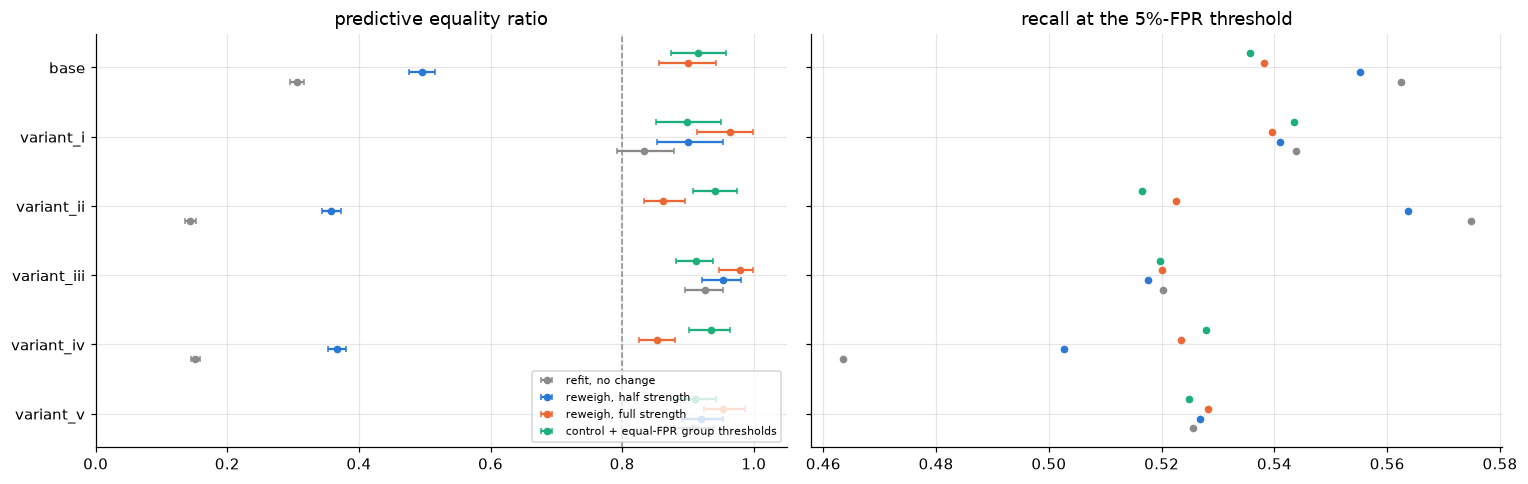

In [65]:
recipes = list(dict.fromkeys(carry_table.index.get_level_values('recipe')))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
palette = [GREY, BLUE, ORANGE, GREEN, 'black']
for ax, column, title in [(axes[0], 'predictive equality', 'predictive equality ratio'), (axes[1], 'recall', 'recall at the 5%-FPR threshold')]:
    for i, recipe in enumerate(recipes):
        sub = carry_table.xs(recipe, level='recipe').loc[DATASETS]
        ys = np.arange(len(DATASETS))[::-1] + (i - (len(recipes) - 1) / 2) * 0.14
        if column == 'predictive equality':
            ax.errorbar(sub[column], ys, xerr=[sub[column] - sub['PE CI low'], sub['PE CI high'] - sub[column]], fmt='o', color=palette[i % len(palette)], capsize=2, label=recipe, markersize=4)
        else:
            ax.plot(sub[column], ys, 'o', color=palette[i % len(palette)], label=recipe, markersize=4)
    ax.set_title(title)
    if column == 'predictive equality':
        ax.axvline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1)
        ax.set_xlim(0, 1.05)
axes[0].set_yticks(np.arange(len(DATASETS))[::-1])
axes[0].set_yticklabels(DATASETS)
axes[0].legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

### **9.4 An Extension: Reweighing on Housing Status**
Housing status BA keeps the largest gap (predictive equality about 0.08) after every age mitigation. Reweighing is generic, so test it on housing, **alone** and **together with age** (the four cells of age x housing BA). The same recipe as before: frozen hyperparameters, months 0-3, 3 seeds, full strength only (the half-strength test showed that the effect is not linear), own 5%-FPR threshold from month 5. Age and housing status stay in the model as inputs. In the training months the fraud rate of housing BA is 3.35% against 0.53% for other housing (6.3 times), so this is a stronger intervention than for age. Weights range from 0.29 to 1.81 (housing) and 0.20 to 2.25 (age x housing), and make the weighted fraud rate the same in every group (0.97%).

**Findings** (predictive equality, test months)

| | age 50+ | income 0.9 | employment CC | housing BA | recall | cost per 10,000 (R=10) |
|---|---|---|---|---|---|---|
| refit, no change | 0.31 | 0.34 | 0.40 | 0.08 | 0.562 | 1137 |
| reweigh on age | **0.90** | 0.33 | 0.84 | 0.09 | 0.538 | 1173 |
| reweigh on housing BA | 0.34 | 0.39 | 0.31 | **0.80** (0.76-0.84) | 0.422 | 1272 |
| reweigh on age x housing BA | **0.84** (0.80-0.88) | 0.38 | 0.60 | **0.77** (0.73-0.80) | 0.418 | 1276 |

- **Each repair is specific to its group.** Reweighing on age leaves housing BA at 0.09, and reweighing on housing leaves age at 0.34.
- **The housing repair is seven times as expensive.** Recall falls by 14.1 points (-15.7 to -12.5) for housing and 14.4 points for both, against 2.4 points for age alone; the cost at R = 10 rises by +135 (+12%) against +36 (+3.1%). Housing BA is a strong real risk factor (6 times the fraud rate), so removing its link to the label removes much of the signal the model uses.
- **Joint reweighing gets age almost free once housing is paid for:** the recall loss (-14.4) is about that of housing alone (-14.1), and age reaches 0.84 and housing 0.77.
- **Income 0.9 stays at 0.33-0.39 under every version:** reweighing on age or housing does not repair its gap. Employment CC follows age.
- **Meaning.** Fixing the age gap is cheap and fixing the housing gap is not. A bank would adopt the age repair and treat housing status as a business and legal decision (is the feature legitimate, and is a 14-point recall loss acceptable?), not as a modelling fix.

In [66]:
def reweighing_weights_cells(y, cell_codes, strength=1.0):
    """w(cell, y) = P(cell) P(y) / P(cell, y) for any grouping of the applications into cells (generalises the age version of 8.1)."""
    y, codes = np.asarray(y), np.asarray(cell_codes)
    w = np.ones(len(y))
    for c in np.unique(codes):
        for label in (0, 1):
            cell = (codes == c) & (y == label)
            if cell.any():
                w[cell] = ((codes == c).mean() * (y == label).mean() / cell.mean()) ** strength
    return w


HOUSING_NAME = 'housing_status = BA'
housing_train = train_raw[HOUSING_NAME].to_numpy()
HOUSING_SETTINGS = {'reweigh_housing': ('reweigh on housing BA', housing_train.astype(int)),
                    'reweigh_age_housing': ('reweigh on age x housing BA', old_train_all.astype(int) * 2 + housing_train.astype(int))}
LABELS.update({key: label for key, (label, _) in HOUSING_SETTINGS.items()})
FAMILY.update({key: 'retrained' for key in HOUSING_SETTINGS})

rows = []
for key, (label, codes) in HOUSING_SETTINGS.items():
    w = reweighing_weights_cells(y_train_all, codes)
    rows.append({'setting': label, 'smallest weight': w.min(), 'largest weight': w.max(),
                 'weighted fraud rate, housing BA': np.average(y_train_all[housing_train], weights=w[housing_train]),
                 'weighted fraud rate, other housing': np.average(y_train_all[~housing_train], weights=w[~housing_train]),
                 'weighted fraud rate, 50+': np.average(y_train_all[old_train_all], weights=w[old_train_all]),
                 'weighted fraud rate, under 50': np.average(y_train_all[~old_train_all], weights=w[~old_train_all])})
display(pd.DataFrame(rows).set_index('setting').round(4))
print('unweighted fraud rate, housing BA: %.4f, other housing: %.4f' % (y_train_all[housing_train].mean(), y_train_all[~housing_train].mean()))

,smallest weight,largest weight,"weighted fraud rate, housing BA","weighted fraud rate, other housing","weighted fraud rate, 50+","weighted fraud rate, under 50"
setting,,,,,,
reweigh on housing BA,0.2884,1.8118,0.0097,0.0097,0.0178,0.0077
reweigh on age x housing BA,0.2019,2.2538,0.0097,0.0097,0.0097,0.0097


unweighted fraud rate, housing BA: 0.0335, other housing: 0.0053


In [67]:
HOUSING_CACHE = f'{DATA_DIR}/cache/housing_reweigh_scores.parquet'
cached_h = pd.read_parquet(HOUSING_CACHE) if os.path.exists(HOUSING_CACHE) else None
if cached_h is not None and (len(cached_h) != len(mit) or not (cached_h['row_id'].to_numpy() == mit['row_id'].to_numpy()).all()):
    cached_h = None
if cached_h is None:
    cached_h = mit[['row_id', 'month']].copy()

if any(column_name(key, s) not in cached_h for key in HOUSING_SETTINGS for s in MIT_SEEDS):
    X_train_h = make_features(base_raw[base_raw['month'].isin(TRAIN_MONTHS)], **FEATURES)
    X_score_h = make_features(base_raw.loc[mit['row_id'].to_numpy()], **FEATURES)
    for key, (label, codes) in HOUSING_SETTINGS.items():
        start = time.time()
        weights = reweighing_weights_cells(y_train_all, codes)
        for seed in MIT_SEEDS:
            if column_name(key, seed) not in cached_h:
                model = make_xgboost(seed).fit(X_train_h, y_train_all, sample_weight=weights)
                cached_h[column_name(key, seed)] = model.predict_proba(X_score_h)[:, 1].astype(np.float32)
        print(f'{label:30s} {len(MIT_SEEDS)} seeds trained, {(time.time() - start) / 60:.1f} min')
        try:
            cached_h.to_parquet(HOUSING_CACHE, index=False)
        except Exception as error:
            print(f'  (the scores could not be saved: {type(error).__name__})')
else:
    print(f'Loaded the saved scores from {HOUSING_CACHE}')
for key in HOUSING_SETTINGS:
    for seed in MIT_SEEDS:
        mit[column_name(key, seed)] = cached_h[column_name(key, seed)].to_numpy()
    retrained_cuts[key] = {s: threshold_at_fpr(y_mit[is_m5], mit.loc[is_m5, column_name(key, s)].to_numpy(), TARGET_FPR) for s in MIT_SEEDS}
    for where, rows_ in (('month 4', is_m4), ('test', is_test)):
        flags_at[where][key] = {s: mit.loc[rows_, column_name(key, s)].to_numpy() >= retrained_cuts[key][s] for s in MIT_SEEDS}

reweigh on housing BA          3 seeds trained, 0.2 min


reweigh on age x housing BA    3 seeds trained, 0.2 min


In [68]:
HOUSING_VIEW = ['control', 'reweigh_1', 'reweigh_housing', 'reweigh_age_housing']
test_masks = {name: mit.loc[is_test, name].to_numpy() for name in GROUP_NAMES}
by_group = {name: evaluate_flags(y_mit[is_test], test_masks[name], {n: flags_at['test'][n] for n in HOUSING_VIEW}) for name in GROUP_NAMES}

rows = []
for n in HOUSING_VIEW:
    row = {'setting': LABELS[n]}
    for name in GROUP_NAMES:
        iv = with_interval(by_group[name], [n], 'predictive equality').iloc[0]
        row[f'PE {name}'] = f"{iv['estimate']:.3f} ({iv['CI low']:.3f}-{iv['CI high']:.3f})"
    res = by_group['age 50+']
    row['recall'] = f"{res[n].loc[0, 'recall']:.3f}"
    row['false alarms per 1,000'] = f"{res[n].loc[0, 'false alarms per 1,000']:.1f}"
    row['cost per 10,000 (R=10)'] = f"{res[n].loc[0, 'cost per 10,000 (R=10)']:.0f}"
    rows.append(row)
display(pd.DataFrame(rows).set_index('setting'))

rows = []
for n in HOUSING_VIEW[1:]:
    row = {'setting': LABELS[n]}
    for column in ['recall', 'false alarms per 1,000', 'cost per 10,000 (R=10)']:
        d = paired_difference(by_group['age 50+'], n, 'control', column)
        row[column] = f"{d['difference']:+.3f} ({d['CI low']:+.3f} to {d['CI high']:+.3f})"
    rows.append(row)
print('Paired differences from the refit control (test months):')
pd.DataFrame(rows).set_index('setting')

,PE age 50+,PE income = 0.9,PE employment_status = CC,PE housing_status = BA,recall,"false alarms per 1,000","cost per 10,000 (R=10)"
setting,,,,,,,
"refit, no change",0.306 (0.295-0.317),0.335 (0.323-0.347),0.401 (0.374-0.431),0.083 (0.080-0.087),0.562,52.3,1137
"reweigh, full strength",0.900 (0.857-0.942),0.333 (0.322-0.345),0.837 (0.757-0.923),0.090 (0.086-0.094),0.538,52.5,1173
reweigh on housing BA,0.339 (0.326-0.353),0.394 (0.379-0.408),0.312 (0.294-0.334),0.801 (0.763-0.839),0.422,46.0,1272
reweigh on age x housing BA,0.835 (0.797-0.876),0.384 (0.369-0.399),0.601 (0.558-0.659),0.766 (0.731-0.800),0.418,45.9,1276


Paired differences from the refit control (test months):


,recall,"false alarms per 1,000","cost per 10,000 (R=10)"
setting,,,
"reweigh, full strength",-0.024 (-0.034 to -0.014),+0.156 (-0.422 to +0.715),+35.543 (+19.953 to +50.854)
reweigh on housing BA,-0.141 (-0.157 to -0.125),-6.270 (-7.218 to -5.359),+135.017 (+109.133 to +160.784)
reweigh on age x housing BA,-0.144 (-0.161 to -0.128),-6.353 (-7.336 to -5.468),+139.066 (+113.416 to +166.175)


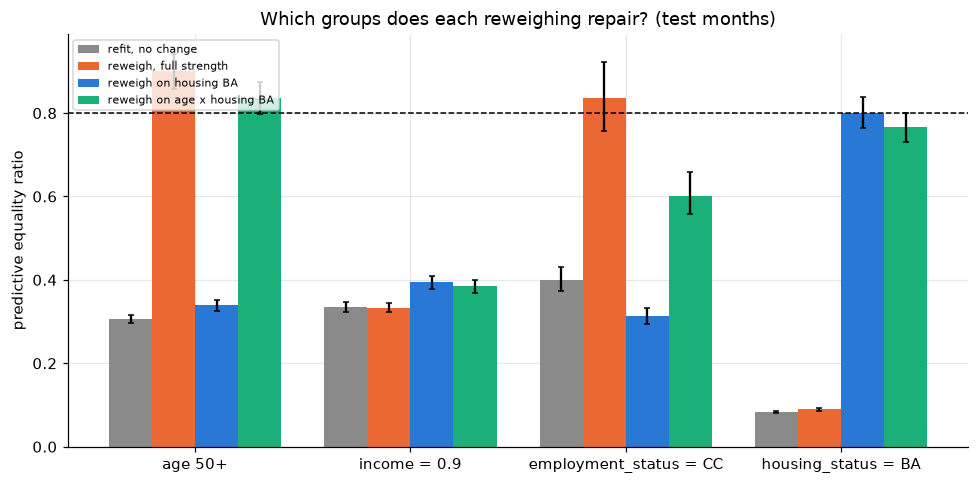

In [69]:
fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.2
for i, n in enumerate(HOUSING_VIEW):
    est = [with_interval(by_group[name], [n], 'predictive equality').iloc[0] for name in GROUP_NAMES]
    ax.bar(np.arange(len(GROUP_NAMES)) + (i - 1.5) * width, [e['estimate'] for e in est], width,
           yerr=[[e['estimate'] - e['CI low'] for e in est], [e['CI high'] - e['estimate'] for e in est]],
           color=[GREY, ORANGE, BLUE, GREEN][i], capsize=2, label=LABELS[n])
ax.axhline(FOUR_FIFTHS, color='black', linestyle='--', linewidth=1)
ax.set_xticks(range(len(GROUP_NAMES)))
ax.set_xticklabels(GROUP_NAMES)
ax.set_ylabel('predictive equality ratio')
ax.set_title('Which groups does each reweighing repair? (test months)')
ax.legend(fontsize=7, loc='upper left')
plt.tight_layout()
plt.show()

## **10. Fairness in the Review Workflow**
Notebook 03 (section 6) simulated how a bank could split alerts between the model and 50 analysts, and its section 6.4 showed that the cheapest policy is not the fairest. This section does what notebook 03 did not: it measures every analyst with the full set of group measures, and tests **routing rules that choose analysts for fairness** (a fair analyst pool, balanced review). Notebook 03's cheapest policy stays in the tables as the comparison row. The alerts, analyst decisions, history months (4-6) used to profile analysts, test month (7), cost ratios and five simulation seeds are those of notebook 03, and the model scores come from the same frozen models, so nothing is re-scored. There are 30,622 alerts (all matched to a Base row), 50 analysts, 17,883 history alerts (2,197 fraud) and 4,457 test alerts (711 fraud). These alerts were already flagged by the BAF alert model, so the rates are on flagged applicants and **are not comparable with the earlier sections** (the AI-only FPR here is 0.42 and its predictive equality 0.75, against 0.31 for the whole population).

**Findings**
- The cheaper analysts are the less fair ones, so routing on cost alone is the least fair routing.
- A fair pool of analysts (a minimum predictive equality) lifts fairness at a cost of about 17% for 0.80, mostly by flagging more in both age groups.
- Human review reduces the gap between the age groups by about a quarter (equalised odds difference 0.137 for AI only, about 0.10 with review), but none of the routing rules removes it.

In [70]:
import glob
FIFAR_DIR = f'{DATA_DIR}/fifar'
if not os.path.exists(f'{FIFAR_DIR}/alert_data/processed_data/alerts.parquet'):    # look for the folder notebook 03 used
    found = glob.glob(f'{DATA_DIR}/**/alert_data/processed_data/alerts.parquet', recursive=True) + glob.glob('../**/alert_data/processed_data/alerts.parquet', recursive=True)
    if found:
        FIFAR_DIR = os.path.dirname(os.path.dirname(os.path.dirname(found[0])))
        print('FiFAR folder found at', FIFAR_DIR)
FA_ALERTS = f'{FIFAR_DIR}/alert_data/processed_data/alerts.parquet'
FA_EXPERTS = f'{FIFAR_DIR}/synthetic_experts/expert_predictions.parquet'
FIFAR_OK = os.path.exists(FA_ALERTS) and os.path.exists(FA_EXPERTS)
FA_HISTORY, FA_TEST = [4, 5, 6], [7]      # as in notebook 03
FA_MAIN_RATIO = 10

if not FIFAR_OK:
    print(f'The FiFAR files were not found under {FIFAR_DIR}: section 10 is skipped. Set FIFAR_DIR to the folder that notebook 03 used and run again.')
else:
    fa_alerts = pd.read_parquet(FA_ALERTS)
    expert_predictions = pd.read_parquet(FA_EXPERTS)
    ANALYSTS = list(expert_predictions.columns)
    expert_predictions = expert_predictions.loc[fa_alerts.index]

    # Link each alert to its Base row (notebook 03, section 3.1), then take its scores from the table of section 1.1
    KEY = ['name_email_similarity', 'velocity_6h', 'credit_risk_score', 'customer_age', 'month']
    left = fa_alerts[KEY].round(6).reset_index()
    right = base_raw[KEY].round(6).reset_index(names='row_id')
    link = left.merge(right, on=KEY, how='left').set_index('case_id')
    print(f"{link['row_id'].notna().sum():,} of {len(fa_alerts):,} alerts matched to a Base row, {link.index.duplicated().sum()} matched twice")
    fa_alerts['row_id'] = link.loc[fa_alerts.index, 'row_id'].astype(int)
    by_row = base.set_index('row_id')
    assert (by_row.loc[fa_alerts['row_id'], 'customer_age'].to_numpy() == fa_alerts['customer_age'].to_numpy()).all(), 'the linked rows do not match'
    for seed in SEEDS:
        fa_alerts[f'score_seed{seed}'] = by_row.loc[fa_alerts['row_id'], f'score_seed{seed}'].to_numpy()

    fa_hist = fa_alerts['month'].isin(FA_HISTORY).to_numpy()
    fa_test = fa_alerts['month'].isin(FA_TEST).to_numpy()
    fa_y_hist, fa_y_test = fa_alerts.loc[fa_hist, TARGET].to_numpy(), fa_alerts.loc[fa_test, TARGET].to_numpy()
    fa_old_hist, fa_old_test = (fa_alerts.loc[fa_hist, 'customer_age'] >= AGE_CUT).to_numpy(), (fa_alerts.loc[fa_test, 'customer_age'] >= AGE_CUT).to_numpy()
    D_hist = expert_predictions.to_numpy()[fa_hist].astype(bool)      # alerts x analysts
    D_test = expert_predictions.to_numpy()[fa_test].astype(bool)
    print(f'{len(ANALYSTS)} analysts; history alerts (months {FA_HISTORY}): {fa_hist.sum():,} ({fa_y_hist.sum():,} fraud); test alerts (month {FA_TEST}): {fa_test.sum():,} ({fa_y_test.sum():,} fraud)')
    print('fraud cases in history by group (recall needs at least %d each): 50+ %d, under 50 %d' % (MIN_FRAUD_CASES, fa_y_hist[fa_old_hist].sum(), fa_y_hist[~fa_old_hist].sum()))

30,622 of 30,622 alerts matched to a Base row, 0 matched twice
50 analysts; history alerts (months [4, 5, 6]): 17,883 (2,197 fraud); test alerts (month [7]): 4,457 (711 fraud)
fraud cases in history by group (recall needs at least 50 each): 50+ 1057, under 50 1140


### **10.1 The Analysts, Group by Group**
Give each analyst the full set of group measures, to see who is fair. For each analyst: FPR and recall for the 50+ group and the others, predictive equality, equal opportunity and the equalised odds difference, from the **history months only** (so picking analysts later does not use month 7). The model on the same alerts is shown for comparison, at the lowest-cost threshold for a cost ratio of 10.

**Findings**
- **Every analyst flags genuine 50+ applicants more often:** predictive equality ranges from 0.54 to 0.97, with a median of 0.81 (quartiles 0.70 and 0.88).
- **Cost and fairness pull apart.** The Spearman correlation between analyst cost and predictive equality is 0.68, and the 10 cheapest analysts have a median of 0.70 against 0.81 for all 50.
- The model on the same alerts (seed 0) has predictive equality 0.765 and an equalised odds difference of 0.132, similar to the median analyst, and analysts' recall gaps are small (equal opportunity 0.87-1.0).

In [71]:
def lowest_cost_threshold(y_true, scores_, ratio):
    # Copied from notebook 03, section 6.1.
    order = np.argsort(-scores_)
    sorted_scores = scores_[order]
    is_fraud = y_true[order] == 1
    false_alarms = np.cumsum(~is_fraud)
    missed_fraud = is_fraud.sum() - np.cumsum(is_fraud)
    costs = ratio * missed_fraud + false_alarms
    best = np.argmin(costs)
    if ratio * is_fraud.sum() <= costs[best]:
        return np.inf
    return sorted_scores[best]


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def group_measures(D, y, old):
    """Rates of one or many decision vectors (columns of D) by age group."""
    D = np.asarray(D, dtype=float)
    if D.ndim == 1:
        D = D[:, None]
    g, f = y == 0, y == 1
    out = {'FPR 50+': D[g & old].mean(axis=0), 'FPR under 50': D[g & ~old].mean(axis=0),
           'recall 50+': D[f & old].mean(axis=0), 'recall under 50': D[f & ~old].mean(axis=0),
           'recall': D[f].mean(axis=0), 'FPR': D[g].mean(axis=0)}
    out['predictive equality'] = np.minimum(out['FPR 50+'], out['FPR under 50']) / np.maximum(out['FPR 50+'], out['FPR under 50'])
    out['equal opportunity'] = np.minimum(out['recall 50+'], out['recall under 50']) / np.maximum(out['recall 50+'], out['recall under 50'])
    out['equalised odds difference'] = np.maximum(np.abs(out['FPR 50+'] - out['FPR under 50']), np.abs(out['recall 50+'] - out['recall under 50']))
    return out


if FIFAR_OK:
    fa_thresholds = {(ratio, seed): lowest_cost_threshold(fa_y_hist, fa_alerts.loc[fa_hist, f'score_seed{seed}'].to_numpy(), ratio)
                     for ratio in COST_RATIOS for seed in SEEDS}
    analyst_profile = pd.DataFrame(group_measures(D_hist, fa_y_hist, fa_old_hist), index=ANALYSTS)
    analyst_profile['cost per 1,000 alerts (R=10)'] = [1000 * (FA_MAIN_RATIO * ((fa_y_hist == 1) & ~D_hist[:, j]).sum() + ((fa_y_hist == 0) & D_hist[:, j]).sum()) / len(fa_y_hist)
                                                        for j in range(len(ANALYSTS))]
    model_hist = {k: v[0] for k, v in group_measures(fa_alerts.loc[fa_hist, 'score_seed0'].to_numpy() >= fa_thresholds[(FA_MAIN_RATIO, 0)], fa_y_hist, fa_old_hist).items()}
    summary = analyst_profile.describe().loc[['min', '25%', '50%', '75%', 'max']]
    display(pd.concat([summary, pd.Series(model_hist, name='our model (seed 0)').to_frame().T]).round(3))

    rho, p_value = stats.spearmanr(analyst_profile['cost per 1,000 alerts (R=10)'], analyst_profile['predictive equality'])
    best10 = analyst_profile.sort_values('cost per 1,000 alerts (R=10)').head(10)
    print(f'Spearman correlation between an analyst cost (lower is better) and predictive equality: {rho:.2f} (p = {p_value:.3f}); '
          f'the 10 cheapest analysts have a median predictive equality of {best10["predictive equality"].median():.2f} against {analyst_profile["predictive equality"].median():.2f} for all 50')
    print('quantiles of analyst predictive equality:', analyst_profile['predictive equality'].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_dict())

,FPR 50+,FPR under 50,recall 50+,recall under 50,recall,FPR,predictive equality,equal opportunity,equalised odds difference,"cost per 1,000 alerts (R=10)"
min,0.016,0.009,0.693,0.616,0.662,0.012,0.539,0.866,0.015,286.976
25%,0.154,0.106,0.781,0.738,0.756,0.125,0.698,0.942,0.042,404.406
50%,0.319,0.263,0.851,0.819,0.832,0.287,0.811,0.964,0.054,453.615
75%,0.482,0.416,0.915,0.892,0.901,0.444,0.877,0.988,0.067,530.839
max,0.776,0.721,0.989,0.982,0.985,0.744,0.967,0.999,0.135,673.377
our model (seed 0),0.560,0.428,0.817,0.706,0.760,0.484,0.765,0.864,0.132,NaN


Spearman correlation between an analyst cost (lower is better) and predictive equality: 0.68 (p = 0.000); the 10 cheapest analysts have a median predictive equality of 0.70 against 0.81 for all 50
quantiles of analyst predictive equality: {0.1: 0.67, 0.25: 0.7, 0.5: 0.81, 0.75: 0.88, 0.9: 0.93}


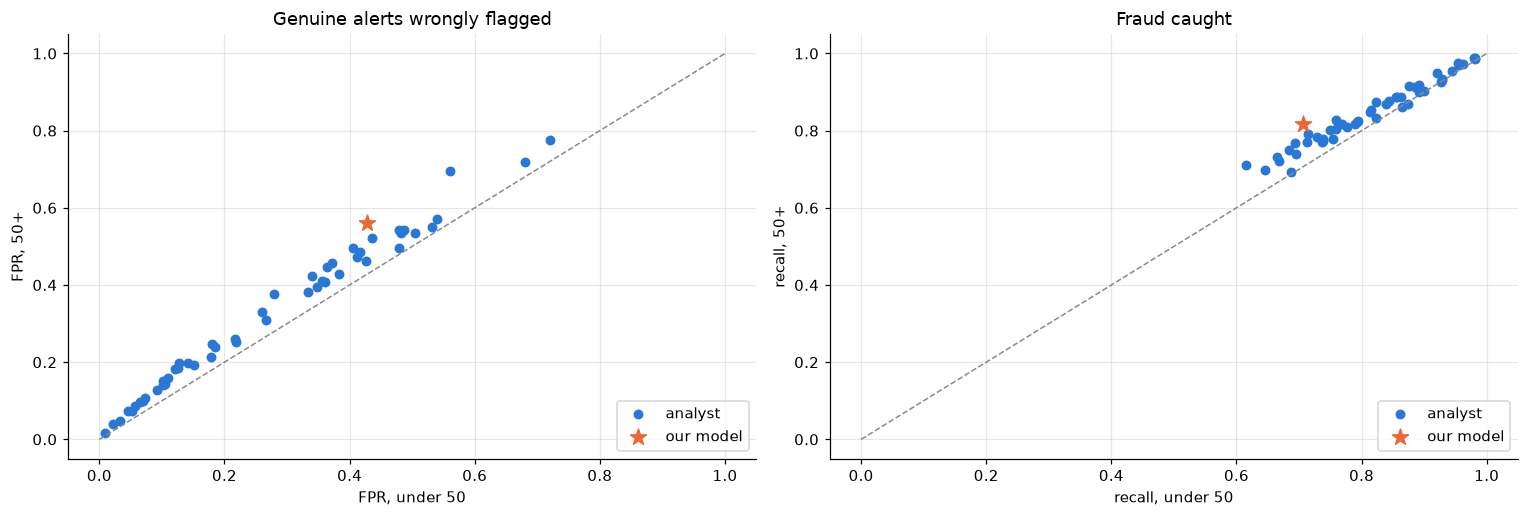

In [72]:
if FIFAR_OK:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    ax = axes[0]
    ax.scatter(analyst_profile['FPR under 50'], analyst_profile['FPR 50+'], color=BLUE, s=30, label='analyst')
    ax.scatter(model_hist['FPR under 50'], model_hist['FPR 50+'], color=ORANGE, s=120, marker='*', label='our model')
    ax.plot([0, 1], [0, 1], color=GREY, linestyle='--', linewidth=1)
    ax.set_xlabel('FPR, under 50')
    ax.set_ylabel('FPR, 50+')
    ax.set_title('Genuine alerts wrongly flagged')
    ax.legend(loc='lower right')
    ax = axes[1]
    ax.scatter(analyst_profile['recall under 50'], analyst_profile['recall 50+'], color=BLUE, s=30, label='analyst')
    ax.scatter(model_hist['recall under 50'], model_hist['recall 50+'], color=ORANGE, s=120, marker='*', label='our model')
    ax.plot([0, 1], [0, 1], color=GREY, linestyle='--', linewidth=1)
    ax.set_xlabel('recall, under 50')
    ax.set_ylabel('recall, 50+')
    ax.set_title('Fraud caught')
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

### **10.2 Routing Rules That Take Fairness into Account**
Test whether routing can be made fairer than notebook 03's cheapest policy, which sends the alerts the model is least sure about to the 10 cheapest analysts. Three changes, each aimed at one reason the policy could be unfair:
1. **Fair pool.** The 10 analysts are chosen among those whose history predictive equality is at least tau, still by lowest cost. tau is not standard, so three values are tested (0.7, 0.8 as the four-fifths reference, and 0.9). Analysts are profiled on the history months only. 0.8 is the four-fifths reference, and 0.7 and 0.9 show how the result moves around it.
2. **Balanced review.** The same share of alerts is reviewed in both age groups (the least-sure alerts of each group, separately), so neither group is reviewed less.
3. **Both.**

The model's own decision for the alerts that are not reviewed uses the threshold of the previous subsection. Capacity runs from 0 to 100% of the month-7 alerts in steps of 10%, cost ratios are 5, 10, 20 and 50, and each simulation is run for 5 seeds (mean and spread are reported).

**Findings**
- The fair pools hold 10, 10 and 8 analysts (tau 0.7, 0.8, 0.9), with a median predictive equality of 0.79, 0.85 and 0.94, against 0.69 for the 10 cheapest.

In [73]:
TAUS = [0.7, 0.8, 0.9]
CAPACITIES = np.round(np.arange(0, 1.01, 0.1), 1)
POLICY_SPEC = {'AI only': None,
               'Unsure alerts, all analysts': ('unsure', 'all'),
               'Unsure alerts, best 10 by cost': ('unsure', 'best'),
               **{f'Unsure alerts, best 10 with PE >= {tau}': ('unsure', ('fair', tau)) for tau in TAUS},
               'Balanced review, best 10 by cost': ('balanced', 'best'),
               'Balanced review, best 10 with PE >= 0.8': ('balanced', ('fair', 0.8))}
BASELINE_POLICY = 'Unsure alerts, best 10 by cost'

if FIFAR_OK:
    history_cost = {ratio: np.array([ratio * ((fa_y_hist == 1) & ~D_hist[:, j]).sum() + ((fa_y_hist == 0) & D_hist[:, j]).sum() for j in range(len(ANALYSTS))]) for ratio in COST_RATIOS}
    pools = {}
    for ratio in COST_RATIOS:
        order = np.argsort(history_cost[ratio])
        pools[('all', ratio)] = np.arange(len(ANALYSTS))
        pools[('best', ratio)] = order[:10]
        for tau in TAUS:
            ok = order[analyst_profile['predictive equality'].to_numpy()[order] >= tau]
            pools[(('fair', tau), ratio)] = ok[:10]
    print('analysts in the fair pools (at most 10):', {tau: len(pools[(('fair', tau), FA_MAIN_RATIO)]) for tau in TAUS})
    print('median predictive equality of the pool of the best 10 / of each fair pool (cost ratio 10):',
          round(analyst_profile['predictive equality'].to_numpy()[pools[('best', FA_MAIN_RATIO)]].mean(), 3),
          {tau: round(analyst_profile['predictive equality'].to_numpy()[pools[(('fair', tau), FA_MAIN_RATIO)]].mean(), 3) for tau in TAUS})


def fa_simulate(policy, capacity, ratio, seed):
    rng = np.random.default_rng(seed)
    scores_ = fa_alerts.loc[fa_test, f'score_seed{seed}'].to_numpy()
    threshold = fa_thresholds[(ratio, seed)]
    decisions = scores_ >= threshold
    reviewed = np.array([], dtype=int)
    spec = POLICY_SPEC[policy]
    if spec is not None and capacity > 0:
        distance = np.abs(logit(scores_) - logit(min(threshold, 1)))
        if spec[0] == 'unsure':
            reviewed = np.argsort(distance)[:int(round(capacity * len(scores_)))]
        else:   # the same share of each age group is reviewed
            parts = []
            for g in (fa_old_test, ~fa_old_test):
                idx = np.where(g)[0]
                parts.append(idx[np.argsort(distance[idx])[:int(round(capacity * len(idx)))]])
            reviewed = np.concatenate(parts)
        assigned = rng.choice(pools[(spec[1], ratio)], size=len(reviewed))
        decisions[reviewed] = D_test[reviewed, assigned]
    return decisions, reviewed


def fa_metrics(decisions, reviewed, ratio):
    m = {k: v[0] for k, v in group_measures(decisions, fa_y_test, fa_old_test).items()}
    n = len(decisions)
    m['cost per 1,000 alerts'] = 1000 * (ratio * ((fa_y_test == 1) & ~decisions).sum() + ((fa_y_test == 0) & decisions).sum()) / n
    in_review = np.zeros(n, dtype=bool)
    in_review[reviewed] = True
    m['review rate 50+'], m['review rate under 50'] = in_review[fa_old_test].mean(), in_review[~fa_old_test].mean()
    return m


if FIFAR_OK:
    start = time.time()
    rows = []
    for ratio in COST_RATIOS:
        for policy in POLICY_SPEC:
            for capacity in CAPACITIES:
                for seed in SEEDS:
                    decisions, reviewed = fa_simulate(policy, capacity, ratio, seed)
                    rows.append({'cost ratio': ratio, 'policy': policy, 'capacity': capacity, 'seed': seed, **fa_metrics(decisions, reviewed, ratio)})
    fa_simulation = pd.DataFrame(rows)
    fa_results = fa_simulation.drop(columns='seed').groupby(['cost ratio', 'policy', 'capacity'], sort=False).mean()
    print(f'{len(fa_simulation):,} simulations in {(time.time() - start) / 60:.1f} min')

analysts in the fair pools (at most 10): {0.7: 10, 0.8: 10, 0.9: 8}
median predictive equality of the pool of the best 10 / of each fair pool (cost ratio 10): 0.692 {0.7: np.float64(0.788), 0.8: np.float64(0.85), 0.9: np.float64(0.94)}


1,760 simulations in 0.0 min


### **10.3 Results at Half Capacity (Cost Ratio 10)**
Compare every policy at the middle of the capacity range. Every policy at 50% capacity, the mean over 5 seeds with the spread over seeds for cost and predictive equality, and the review rate of each age group.

**Findings**

| Policy | cost per 1,000 | predictive equality | recall | FPR 50+ / under 50 | equalised odds difference |
|---|---|---|---|---|---|
| AI only | 796 | 0.754 | 0.722 | 0.506 / 0.382 | 0.137 |
| Unsure alerts, best 10 by cost (notebook 03) | **510** | 0.727 | 0.840 | 0.373 / 0.271 | 0.102 |
| Unsure alerts, fair pool tau 0.7 | 550 | 0.777 | 0.859 | 0.456 / 0.355 | 0.102 |
| Unsure alerts, fair pool tau 0.8 | 596 | **0.804** | 0.881 | 0.558 / 0.449 | 0.109 |
| Unsure alerts, fair pool tau 0.9 | 670 | **0.848** | 0.877 | 0.632 / 0.535 | 0.097 |
| Balanced review, best 10 by cost | 500 | 0.739 | 0.844 | 0.365 / 0.270 | 0.097 |
| Balanced review, fair pool tau 0.8 | 592 | 0.798 | 0.882 | 0.559 / 0.446 | 0.113 |

The spread over seeds is 8-20 for cost and 0.010-0.026 for predictive equality.
- **The cheap policy is a little less fair than the model alone** (0.727 against 0.754), but the difference of 0.027 has a spread of 0.020, so it is not clearly real.
- **A fair pool buys fairness, not for free.** Tau 0.8 costs +86 per 1,000 alerts (+17%) for +0.078 in predictive equality (spread 0.017), tau 0.9 costs +160 for +0.121 (0.015), and tau 0.7 costs +40 for +0.050 (0.021). All remain far cheaper than AI only (796), and recall rises from 0.84 to 0.88 because the fairer analysts also flag more.
- **Using all 50 analysts** (583, predictive equality 0.802) reaches the same fairness as the tau 0.8 pool for slightly less, so the pool is not clearly better than simply not choosing on cost.
- **Most of the gain is a higher flag rate in both groups, not a smaller gap.** Under tau 0.8 the FPR rises from 0.37 to 0.56 for 50+ and from 0.27 to 0.45 for the others, so the ratio improves, but the equalised odds difference stays 0.09-0.11 for every review policy (0.137 for AI only). Review reduces this gap (the equalised odds difference) by about a quarter; no routing rule removes it.
- **Balanced review changes nothing here.** The least-sure-alerts rule already reviews both groups at the same rate (0.496 against 0.502), so the balanced rule moves cost by -9 and predictive equality by +0.013, inside the spread over seeds.

In [74]:
if FIFAR_OK:
    at = fa_simulation[(fa_simulation['cost ratio'] == FA_MAIN_RATIO) & (fa_simulation['capacity'] == 0.5)]
    cols = ['cost per 1,000 alerts', 'recall', 'FPR', 'FPR 50+', 'FPR under 50', 'recall 50+', 'recall under 50', 'predictive equality',
            'equal opportunity', 'equalised odds difference', 'review rate 50+', 'review rate under 50']
    mean_table = at.groupby('policy', sort=False)[cols].mean()
    sd = at.groupby('policy', sort=False)[['cost per 1,000 alerts', 'predictive equality']].std()
    mean_table['sd of cost over seeds'], mean_table['sd of PE over seeds'] = sd['cost per 1,000 alerts'], sd['predictive equality']
    display(mean_table.round(3))

    base_runs = at[at['policy'] == BASELINE_POLICY].set_index('seed')
    rows = []
    for policy in POLICY_SPEC:
        if policy == BASELINE_POLICY:
            continue
        runs = at[at['policy'] == policy].set_index('seed')
        row = {'policy': policy}
        for column in ['cost per 1,000 alerts', 'predictive equality', 'equal opportunity', 'recall']:
            d = runs[column] - base_runs[column]
            row[column] = f'{d.mean():+.3f} (sd {d.std():.3f})'
        rows.append(row)
    print(f'Difference from the notebook-03 policy ({BASELINE_POLICY}), mean and spread over the 5 seeds:')
    display(pd.DataFrame(rows).set_index('policy'))

,"cost per 1,000 alerts",recall,FPR,FPR 50+,FPR under 50,recall 50+,recall under 50,predictive equality,equal opportunity,equalised odds difference,review rate 50+,review rate under 50,sd of cost over seeds,sd of PE over seeds
policy,,,,,,,,,,,,,,
AI only,796.141,0.722,0.420,0.506,0.382,0.807,0.670,0.754,0.831,0.137,0.000,0.000,15.602,0.026
"Unsure alerts, all analysts",583.217,0.851,0.411,0.477,0.383,0.896,0.823,0.802,0.919,0.094,0.496,0.502,20.034,0.021
"Unsure alerts, best 10 by cost",509.625,0.840,0.302,0.373,0.271,0.885,0.811,0.727,0.917,0.102,0.496,0.502,9.801,0.016
"Unsure alerts, best 10 with PE >= 0.7",549.921,0.859,0.386,0.456,0.355,0.898,0.834,0.777,0.929,0.102,0.496,0.502,12.171,0.014
"Unsure alerts, best 10 with PE >= 0.8",595.782,0.881,0.482,0.558,0.449,0.925,0.853,0.804,0.923,0.109,0.496,0.502,8.226,0.010
"Unsure alerts, best 10 with PE >= 0.9",670.406,0.877,0.565,0.632,0.535,0.920,0.851,0.848,0.925,0.097,0.496,0.502,10.151,0.014
"Balanced review, best 10 by cost",500.157,0.844,0.299,0.365,0.270,0.894,0.813,0.739,0.909,0.097,0.500,0.500,8.326,0.018
"Balanced review, best 10 with PE >= 0.8",592.102,0.882,0.480,0.559,0.446,0.921,0.857,0.798,0.931,0.113,0.500,0.500,8.484,0.016


Difference from the notebook-03 policy (Unsure alerts, best 10 by cost), mean and spread over the 5 seeds:


,"cost per 1,000 alerts",predictive equality,equal opportunity,recall
policy,,,,
AI only,+286.516 (sd 21.539),+0.027 (sd 0.020),-0.086 (sd 0.016),-0.118 (sd 0.017)
"Unsure alerts, all analysts",+73.592 (sd 17.569),+0.075 (sd 0.015),+0.002 (sd 0.013),+0.012 (sd 0.008)
"Unsure alerts, best 10 with PE >= 0.7",+40.296 (sd 16.563),+0.050 (sd 0.021),+0.013 (sd 0.010),+0.019 (sd 0.013)
"Unsure alerts, best 10 with PE >= 0.8",+86.157 (sd 11.099),+0.078 (sd 0.017),+0.006 (sd 0.010),+0.041 (sd 0.008)
"Unsure alerts, best 10 with PE >= 0.9",+160.781 (sd 13.022),+0.121 (sd 0.015),+0.009 (sd 0.012),+0.038 (sd 0.009)
"Balanced review, best 10 by cost",-9.468 (sd 16.260),+0.013 (sd 0.018),-0.007 (sd 0.007),+0.004 (sd 0.010)
"Balanced review, best 10 with PE >= 0.8",+82.477 (sd 12.709),+0.071 (sd 0.017),+0.014 (sd 0.013),+0.042 (sd 0.008)


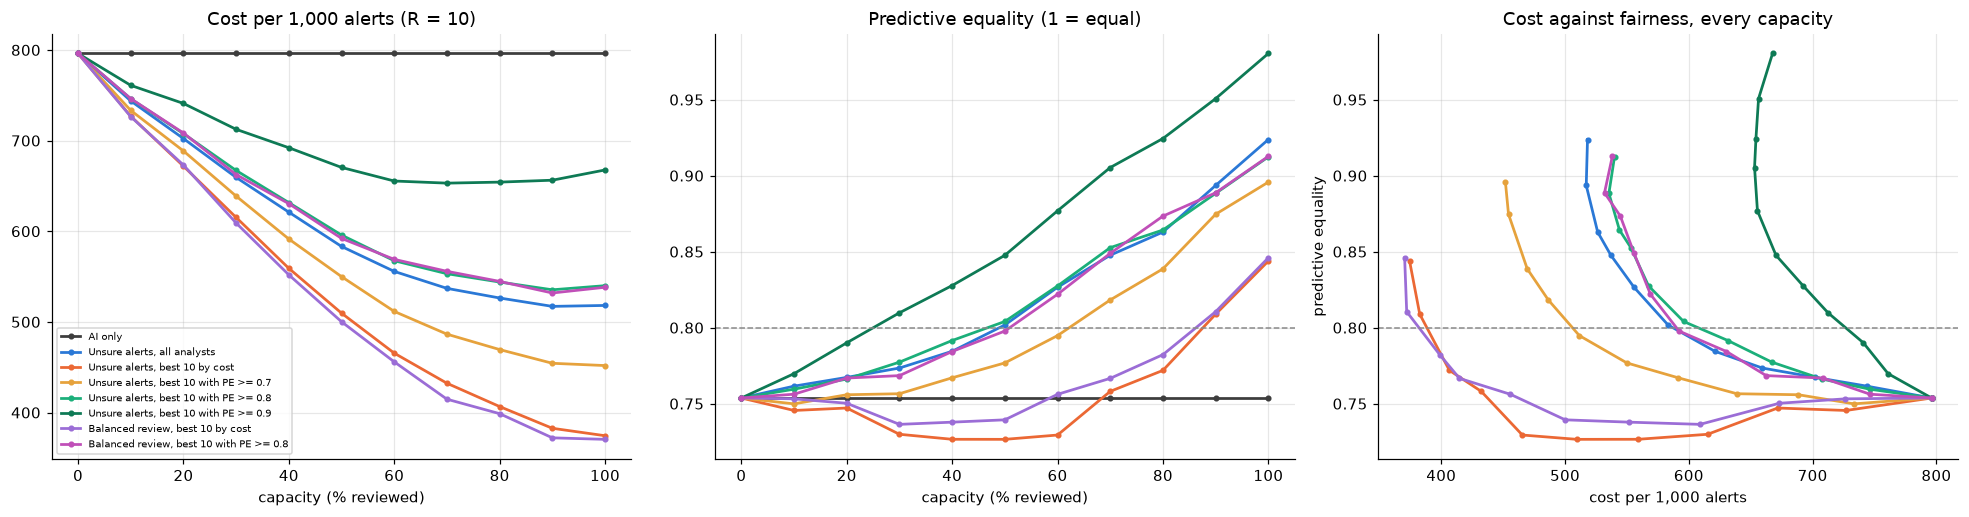

In [75]:
if FIFAR_OK:
    main_rows = fa_results.loc[FA_MAIN_RATIO].reset_index()
    palette = {'AI only': '#3d3d3d', 'Unsure alerts, all analysts': BLUE, BASELINE_POLICY: ORANGE, 'Unsure alerts, best 10 with PE >= 0.7': '#e6a23c',
               'Unsure alerts, best 10 with PE >= 0.8': GREEN, 'Unsure alerts, best 10 with PE >= 0.9': '#0e7a55',
               'Balanced review, best 10 by cost': '#9b6dd6', 'Balanced review, best 10 with PE >= 0.8': '#c04fb8'}
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    for policy in POLICY_SPEC:
        part = main_rows[main_rows['policy'] == policy]
        style = dict(color=palette[policy], linewidth=1.8, marker='o', markersize=3, label=policy)
        axes[0].plot(part['capacity'] * 100, part['cost per 1,000 alerts'], **style)
        axes[1].plot(part['capacity'] * 100, part['predictive equality'], **style)
        axes[2].plot(part['cost per 1,000 alerts'], part['predictive equality'], **style)
    axes[0].set_title('Cost per 1,000 alerts (R = 10)')
    axes[1].set_title('Predictive equality (1 = equal)')
    axes[0].set_xlabel('capacity (% reviewed)')
    axes[1].set_xlabel('capacity (% reviewed)')
    axes[2].set_xlabel('cost per 1,000 alerts')
    axes[2].set_ylabel('predictive equality')
    axes[2].set_title('Cost against fairness, every capacity')
    axes[1].axhline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1)
    axes[2].axhline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1)
    axes[0].legend(fontsize=6.5)
    plt.tight_layout()
    plt.show()

### **10.4 Does It Depend on the Cost Ratio and the Capacity?**
Check that the conclusions hold at other cost ratios, and see how much review capacity each policy needs to reach fairness. Cost and predictive equality of each policy at 50% capacity for every cost ratio, and the smallest capacity at which each policy reaches a predictive equality of at least 0.8 (cost ratio 10).

**Findings**
- **Capacity needed to reach 0.8:** notebook 03's policy needs 90% of alerts reviewed, the tau 0.7 pool 70%, the tau 0.8 pool 50%, the tau 0.9 pool 30%, all analysts 50%, balanced review with the tau 0.8 pool 60%, and AI only never. A fairer pool gets there with much less review, which is a second way it pays back its higher cost per alert.
- **Predictive equality rises with the cost ratio for every policy** (AI only: 0.59, 0.75, 0.90, 0.94 for R = 5, 10, 20, 50).
- **The fair-pool gain is largest at low R.** Over the cheapest policy, tau 0.8 adds +0.063 at R = 5, +0.077 at R = 10, +0.054 at R = 20 and nothing at R = 50 (0.925 against 0.926), where every policy is already above 0.85.
- At R = 20 and 50 the table shows larger effects for balanced review (for example 0.937 against 0.840 at R = 20, at the same cost 633), but the spread over seeds was only measured at R = 10, so these are not read as real.
- **Limits.** The analysts are synthetic, month 7 is one month, the seeds measure the randomness of the simulation and not of the data, and tau is a choice.

In [76]:
if FIFAR_OK:
    half = fa_results.xs(0.5, level='capacity')
    display(half['cost per 1,000 alerts'].unstack('cost ratio').round(0))
    display(half['predictive equality'].unstack('cost ratio').round(3))
    need = {}
    for policy in POLICY_SPEC:
        part = main_rows[main_rows['policy'] == policy].set_index('capacity')['predictive equality']
        reached = part[part >= FOUR_FIFTHS]
        need[policy] = reached.index.min() if len(reached) else np.nan
    print('Smallest capacity (share of alerts reviewed) with predictive equality >= 0.8 at cost ratio 10 (NaN = never):')
    display(pd.Series(need, name='capacity').to_frame())

cost ratio,5,10,20,50
policy,,,,
AI only,590.0,796.0,840.0,853.0
"Unsure alerts, all analysts",450.0,583.0,710.0,1004.0
"Unsure alerts, best 10 by cost",346.0,510.0,633.0,750.0
"Unsure alerts, best 10 with PE >= 0.7",405.0,550.0,638.0,750.0
"Unsure alerts, best 10 with PE >= 0.8",479.0,596.0,657.0,750.0
"Unsure alerts, best 10 with PE >= 0.9",542.0,670.0,734.0,886.0
"Balanced review, best 10 by cost",350.0,500.0,633.0,719.0
"Balanced review, best 10 with PE >= 0.8",479.0,592.0,669.0,733.0


cost ratio,5,10,20,50
policy,,,,
AI only,0.594,0.754,0.895,0.941
"Unsure alerts, all analysts",0.749,0.802,0.863,0.858
"Unsure alerts, best 10 by cost",0.705,0.727,0.840,0.926
"Unsure alerts, best 10 with PE >= 0.7",0.761,0.777,0.864,0.926
"Unsure alerts, best 10 with PE >= 0.8",0.768,0.804,0.894,0.925
"Unsure alerts, best 10 with PE >= 0.9",0.793,0.848,0.929,0.949
"Balanced review, best 10 by cost",0.742,0.739,0.937,0.978
"Balanced review, best 10 with PE >= 0.8",0.867,0.798,0.933,0.987


Smallest capacity (share of alerts reviewed) with predictive equality >= 0.8 at cost ratio 10 (NaN = never):


,capacity
AI only,NaN
"Unsure alerts, all analysts",0.5
"Unsure alerts, best 10 by cost",0.9
"Unsure alerts, best 10 with PE >= 0.7",0.7
"Unsure alerts, best 10 with PE >= 0.8",0.5
"Unsure alerts, best 10 with PE >= 0.9",0.3
"Balanced review, best 10 by cost",0.9
"Balanced review, best 10 with PE >= 0.8",0.6


## **11. Accountability**
Fairness numbers are only useful if someone is responsible for them. This section keeps to three things: what is recorded for every decision, how much a monthly fairness ratio moves by chance (which sets the size of the drop trigger that the monitor in notebook 07 uses), and who owns what, how a customer can contest a decision, which rules apply and what this analysis cannot say. Owners are roles, to be filled in by the bank. The model card and the monitor of the final system are in notebook 07.

### **11.1 A Decision Log for Every Case**
A decision can only be contested and audited if each decision stores what was known and what was done. Five test cases (true positive, false positive, false negative, true negative and one borderline case) with the record that would be stored. **Internal reason codes** are the largest positive contributions to the fraud score in calibrated log-odds (TreeSHAP; a feature and its missing flag are grouped); they are for analysts and auditors. The **customer-facing text is generic** on purpose, because detailed reasons would tell a fraudster what to avoid. In production one decision rule has to be fixed; here the decision is the one of seed 0, and the number of seeds above their threshold is stored next to it.

**Findings**
- The record holds the model version, mitigation, mean calibrated probability, the threshold (0.0443), the seeds above it (5 of 5, 5 of 5, 0 of 5, 0 of 5 and 1 of 5), the decision, the internal reasons and the generic customer text; reviewer, override and outcome are filled in later.
- Reason codes are only generated for flagged applications. The false positive is flagged mainly because of housing status (+0.82) and device OS (+0.58), which is what an analyst needs to see and what the customer should not be told.
- The borderline case (1 of 5 seeds above the threshold) shows why the number of seeds above is stored: the decision is not unanimous.

In [77]:
import hashlib


def file_hash(path):
    try:
        with open(path, 'rb') as f:
            return hashlib.sha256(f.read()).hexdigest()[:12]
    except OSError:
        return 'file not found'


def reason_codes(position, seed=0, top=3):
    contributions = shap_contributions(models[seed], X_real.iloc[[position]])[0][:-1] * calibration['seeds'][str(seed)]['a']
    grouped = pd.Series(contributions, index=X_real.columns).groupby(group_of).sum()
    return '; '.join(f'{name} ({value:+.2f})' for name, value in grouped.sort_values(ascending=False).head(top).items())


MODEL_VERSION = (f"{final_model['model']}, {len(SEEDS)} seeds, trained on months {final_model.get('trained_on_months', TRAIN_MONTHS)}, "
                 f"file hash seed 0: {file_hash('../outputs/models/' + final_model['model'] + '_seed0.joblib')}")


def decision_record(i, mitigation='none (frozen threshold)'):
    p_mean = float(np.mean([p_test[s][i] for s in SEEDS]))
    flagged = bool(flags_test[0][i])
    return {
        'application id (row_id)': int(test.loc[i, 'row_id']), 'month': int(test.loc[i, 'month']),
        'model version': MODEL_VERSION, 'fairness mitigation': mitigation,
        'mean calibrated fraud probability': round(p_mean, 4),
        'calibrated threshold (seed 0)': round(float(calibrate(thresholds[0], 0)), 4),
        'seeds above their threshold': f'{sum(bool(flags_test[s][i]) for s in SEEDS)} of {len(SEEDS)}',
        'decision': 'flag for review' if flagged else 'pass',
        'internal reason codes (calibrated log-odds)': reason_codes(i) if flagged else '(not generated for passed applications)',
        'customer-facing text': 'We need to check some details of your application before we can open the account.' if flagged else '-',
        'reviewer id / decision / override / reason / time': 'to be filled by the review step',
        'later outcome (fraud confirmed or not)': 'to be filled when known',
    }


rng_cases = np.random.default_rng(0)
f0 = flags_test[0]
pools_ = {'true positive': np.where(f0 & (y_test == 1))[0], 'false positive': np.where(f0 & (y_test == 0))[0],
          'false negative': np.where(~f0 & (y_test == 1))[0], 'true negative': np.where(~f0 & (y_test == 0))[0]}
cases = {name: int(rng_cases.choice(idx)) for name, idx in pools_.items()}
p0 = p_test[0]
border = np.where(~f0 & (p0 > 0.8 * calibrate(thresholds[0], 0)))[0]
cases['borderline pass'] = int(rng_cases.choice(border)) if len(border) else int(rng_cases.choice(pools_['true negative']))
pd.DataFrame({name: decision_record(i) for name, i in cases.items()})

,true positive,false positive,false negative,true negative,borderline pass
application id (row_id),513383,555392,512417,55576,68656
month,6,6,6,7,7
model version,"xgboost, 5 seeds, trained on months [0, 1, 2, ...","xgboost, 5 seeds, trained on months [0, 1, 2, ...","xgboost, 5 seeds, trained on months [0, 1, 2, ...","xgboost, 5 seeds, trained on months [0, 1, 2, ...","xgboost, 5 seeds, trained on months [0, 1, 2, ..."
fairness mitigation,none (frozen threshold),none (frozen threshold),none (frozen threshold),none (frozen threshold),none (frozen threshold)
mean calibrated fraud probability,0.0589,0.051,0.0124,0.0014,0.0352
calibrated threshold (seed 0),0.0443,0.0443,0.0443,0.0443,0.0443
seeds above their threshold,5 of 5,5 of 5,0 of 5,0 of 5,1 of 5
decision,flag for review,flag for review,pass,pass,pass
internal reason codes (calibrated log-odds),session_length_in_minutes (+0.59); credit_risk...,housing_status (+0.82); device_os (+0.58); inc...,(not generated for passed applications),(not generated for passed applications),(not generated for passed applications)
customer-facing text,We need to check some details of your applicat...,We need to check some details of your applicat...,-,-,-


### **11.2 How Much Does One Month's Fairness Ratio Move?**
Fairness can change after deployment (new customers, new fraud patterns, drift), so a monitor needs a rule for when someone must act. A ratio measured on one month also moves by chance, so the rule has to know how much movement is noise. This subsection measures that noise. It sets the size of the **drop trigger** (predictive equality falling by more than the noise below its value at deployment) that the monitor in notebook 07 uses. The monitor itself is not built here. Month by month (months 4-7), predictive equality of the frozen model, the reweighed model and the equal-FPR thresholds, each with a 95% interval from paired Poisson resamples (300 per month). The noise is the median half-width of those intervals over months and models. Month 5 is the month the thresholds were set on, so it is in-sample. The overall FPR on genuine applications is shown too, because a fixed threshold drifts.

**Findings**
- The noise in one month's predictive equality is about **0.04**, so that is the size of the drop trigger.
- **The frozen model sits at 0.31-0.32 in every month**, far below the 0.8 reference every time, so a floor trigger would fire from day one. That is the finding of this notebook, not a monitoring failure.
- **The mitigated models stay above the floor.** Reweighing is at 0.85, 0.98, 0.92 and 0.91 and equal-FPR thresholds at 0.85, 0.99, 0.93 and 0.92, but the month-4 interval of the reweighed model (0.81-0.89) comes close to 0.8, so a floor alone is not enough and a drop trigger is needed as well.
- **The alert volume moves more than the fairness ratio.** The overall FPR of the frozen threshold is 7.7%, 5.0%, 5.9% and 4.7% in months 4 to 7 (the mitigated models show the same), a swing of about 3 points, which justifies a scheduled check of the threshold.

In [78]:
MONITOR = ['frozen', 'reweigh_1', 'group_equal_fpr']
MONITOR_MONTHS = [4, 5, 6, 7]


def flags_on(name, rows):
    if name == 'frozen':
        return {s: mit.loc[rows, f'score_seed{s}'].to_numpy() >= thresholds[s] for s in SEEDS}
    if name in MITIGATIONS or name in HOUSING_SETTINGS:
        return {s: mit.loc[rows, column_name(name, s)].to_numpy() >= retrained_cuts[name][s] for s in MIT_SEEDS}
    return {s: np.where(old_mit[rows], mit.loc[rows, f'score_seed{s}'].to_numpy() >= group_cut_table[name][s][0],
                        mit.loc[rows, f'score_seed{s}'].to_numpy() >= group_cut_table[name][s][1]) for s in SEEDS}


rows = []
for month in MONITOR_MONTHS:
    sel = (mit['month'] == month).to_numpy()
    res = evaluate_flags(y_mit[sel], old_mit[sel], {n: flags_on(n, sel) for n in MONITOR}, n_resamples=300)
    for n in MONITOR:
        iv = with_interval(res, [n], 'predictive equality').iloc[0]
        rows.append({'month': month, 'model': LABELS[n], 'key': n, 'predictive equality': iv['estimate'], 'CI low': iv['CI low'], 'CI high': iv['CI high'],
                     'equal opportunity': res[n].loc[0, 'equal opportunity'], 'overall FPR': res[n].loc[0, 'FPR'], 'recall': res[n].loc[0, 'recall'],
                     'recall 50+': res[n].loc[0, 'TPR 50+'], 'recall under 50': res[n].loc[0, 'TPR under 50']})
monitor = pd.DataFrame(rows)
NOISE = float(((monitor['CI high'] - monitor['CI low']) / 2).median())
print(f'noise half-width of monthly predictive equality (median over months and models): {NOISE:.3f}')
monitor.drop(columns='key').set_index(['model', 'month']).round(3)

noise half-width of monthly predictive equality (median over months and models): 0.041


,,predictive equality,CI low,CI high,equal opportunity,overall FPR,recall,recall 50+,recall under 50
model,month,,,,,,,,
frozen model (shared threshold),4,0.313,0.300,0.324,0.766,0.077,0.672,0.776,0.595
"reweigh, full strength",4,0.847,0.808,0.890,0.889,0.076,0.627,0.585,0.658
"group thresholds, equal FPR",4,0.850,0.809,0.891,0.892,0.075,0.622,0.582,0.652
frozen model (shared threshold),5,0.322,0.306,0.336,0.638,0.050,0.542,0.715,0.456
"reweigh, full strength",5,0.980,0.917,0.999,0.917,0.050,0.520,0.550,0.504
"group thresholds, equal FPR",5,0.991,0.929,0.999,0.925,0.050,0.521,0.548,0.507
frozen model (shared threshold),6,0.315,0.299,0.328,0.698,0.059,0.561,0.687,0.480
"reweigh, full strength",6,0.919,0.861,0.970,0.972,0.057,0.526,0.517,0.532
"group thresholds, equal FPR",6,0.932,0.877,0.986,0.981,0.057,0.524,0.518,0.528


### **11.3 Owners, Contesting a Decision, Rules and Limits**
Say who is responsible for what, how a customer can contest a decision, which rules apply, and what this analysis cannot say. Owners are roles, not names, and the cadence follows the drift seen in notebooks 02 and 04 and in the monthly figures above. The rules are a framing for compliance to confirm, not legal advice.

**Findings (what the tables decide)**

| What | Owner (role) | Cadence | Action rule |
|---|---|---|---|
| The model, its version and the choice of mitigation | Model owner (fraud analytics lead), approved by model risk | on every change | A new version gets its own results table; the cost ratio R and the cap on the FPR gap are written down with the decision |
| The decision threshold | Threshold owner (head of fraud risk) | monthly check, formal review quarterly | Re-set on new data, never on one month alone |
| The fairness monitor (notebook 07) | Fairness reviewer (independent of the model team) | monthly | A trigger starts an investigation; the reviewer can ask for a pause |
| Complaints and contests | Customer outcomes team | continuous, summary monthly | Patterns by age or other group go to the fairness reviewer |

- **Contesting a decision.** The customer is told only that the application needs checking and what they can do (no score, threshold or features). A human reviewer who did not make the first decision can override the model, and overrides are logged. Confirmed false alarms are fed back as labels: they are the only way to measure FPR by group on real data.
- **MAS FEAT principles (Singapore).** Published in 2018: 14 principles in four groups (fairness, ethics, accountability, transparency), followed by the Veritas assessment methodologies (February 2022). MAS published a consultation paper on Guidelines on AI Risk Management on 13 November 2025 (closed 31 January 2026); whether the final guidelines are out should be checked.
- **EU AI Act.** Credit-scoring AI is high-risk under Annex III, with an exception for AI whose main intended use is detecting financial fraud, so a fraud model like this one falls outside that item (its application date has been postponed, to December 2027 in the Commission's draft guidelines).
- **Age at decision time.** Group-specific thresholds treat applicants differently by age, which some jurisdictions restrict; this is why they are reported as a bound and reweighing is preferred.
- **No single fairness definition is required.** With base rates that differ (2.9% against 1.1%), FPR, recall and precision cannot all be equal; predictive equality was chosen because it counts innocent customers wrongly flagged.
- **What this analysis cannot say.** BAF is synthetic, so real labels (from investigations, with possible label bias and feedback loops) must be re-measured; intervals cover sampling, not the uncertainty of the thresholds or of the future; the review step uses synthetic analysts; and whether a recall loss is acceptable in return for fairness is a decision for the owners above.

## **Summary and Recommendations**
1. **The gap is real and stable.** The frozen model flags genuine 50+ applicants 3.3 times as often (FPR 12.7% against 3.9%, predictive equality 0.31), in every month and on every BAF variant. Recall differs too (0.70 against 0.49). The model ranks the two age groups equally well and is equally well calibrated; the gap comes from one shared threshold applied to groups whose scores differ.
2. **Why.** Using `customer_age` directly explains about a quarter of the distance to parity; the rest is spread over many proxies. A model trained on data where age and fraud are not linked has almost no gap, so the link between age and fraud in the training data is the main cause.
3. **What works.** Removing age or proxies is weak or expensive (12 proxies reach 0.80 but lose more than half the recall). **Reweighing at full strength** (0.90) and **equal-FPR group thresholds** (0.91) give the same fairness for about 2 points of recall (+34 to +36 cost per 10,000 at R = 10, about 3%). Reweighing carries over to all the BAF variants and repairs the two with a gap (II and IV) to about 0.85.
4. **Preferred option.** Reweighing, because it needs no age-dependent cut-off; the thresholds are a bound. Whether the higher fraud rate of older applicants should be neutralised is a decision for the owners of the model.
5. **Housing status is a bigger and costlier gap.** Predictive equality 0.08, repaired only by a 14-point recall loss, and not repaired by any age mitigation.
6. **Human review helps, but does not close the gap.** Choosing analysts with a minimum predictive equality of 0.8 reaches 0.80 for about 17% more cost, mostly by flagging more in both groups; the difference between the groups stays near 0.10, and the cheapest analysts are the least fair.
7. **Accountability.** A decision log with internal reasons and a generic customer message, named owners and a contest route, and a drop trigger of 0.04 for monitoring (the noise of one month's predictive equality). The model card and the monitor are in notebook 07.
8. **Not done here.** Anything that needs real data and real labels.

**Used in the final system.** Reweighing (full strength) and the fair analyst pool are carried into the final system in notebook 07, which compares its review results with the table of section 10.3.